<div align="center">
  <table style="border-collapse: collapse; width: 100%;">
    <tr>
      <td align="center" width="20%" style="vertical-align: middle;">
        <img src="https://upload.wikimedia.org/wikipedia/commons/c/ca/Escudo-UNAM-escalable.svg" width="110px" style="background-color: #ffffff; border-radius: 10px; padding: 6px;">
      </td>
      <td align="center" width="60%" style="vertical-align: middle;">
        <h3>Universidad Nacional Autónoma de México</h3>
        <h4>Facultad de Ciencias</h4>
        <br>
        <strong>Diplomado "Métodos estadísticos y matemáticos para la ciencia de datos"</strong>
        <br><br>
        <em>Prof. M. en C. David Chaffrey Moreno Fernández</em>
        <br><br>
        <strong>Equipo:</strong><br>
        Benavides Esquivel Luis Ángel<br>
        Hernández Álvarez Miriam Fernanda<br>
        Pineda Pineda Pablo<br>
        Ramírez Martínez Rubén
      </td>
      <td align="center" width="20%" style="vertical-align: middle;">
        <img src="https://upload.wikimedia.org/wikipedia/commons/5/5b/Escudo-facultad-ciencias-unam-escalable.svg" width="110px" style="background-color: #ffffff; border-radius: 10px; padding: 6px;">
      </td>
    </tr>
  </table>
</div>

# ENSAFI 2023 · Análisis exploratorio de datos (EDA)
Notebook **solo exploratorio**: describe qué hay en la encuesta, qué tan limpia viene y qué patrones aparecen a simple vista. No contiene modelos ni conclusiones causales.

**Contenido**
0. ¿Qué es la ENSAFI?
1. Carga de datos
2. Estructura, llaves y valores especiales
3. Valores nulos: ¿faltan datos o son saltos del cuestionario?
4. Viviendas y hogares
5. Personas del hogar (sociodemografía)
6. La persona elegida: ingreso, ahorro, deuda
7. Comportamiento, bienestar y estrés financiero
8. Metas, vejez y CONDUSEF
9. Geografía y segmentos
10. Hallazgos y preguntas para la siguiente etapa

**Convención de lectura:** todas las cifras son **ponderadas** con el factor de expansión que corresponde a cada tabla (se indica en cada sección) salvo que se diga "n" o "sin ponderar".

## 0. ¿Qué es la ENSAFI?

**ENSAFI** = *Encuesta Nacional sobre Salud Financiera*. Es una encuesta en hogares del **INEGI** realizada con la **CONDUSEF** (Comisión Nacional para la Protección y Defensa de los Usuarios de Servicios Financieros). Esta edición es la de **2023**.

**Objetivo (según el propio cuestionario):** conocer la **percepción de la población sobre el manejo de sus finanzas**, si tiene **preocupaciones por su situación financiera** y el **impacto en su vida**. Es decir, no mide solo cuánto se gana o se debe, sino cómo se *siente* y se *comporta* la gente con su dinero.

**Cómo se levanta**
* Se visita una **vivienda seleccionada** y se identifica a todos los **hogares** que hay en ella (hogar = personas que comparten un mismo gasto para comer).
* Una persona del hogar (de 18 años o más) informa sobre la vivienda, el hogar y todos sus integrantes.
* Después se entrevista **individualmente a una sola persona de 18 años o más por hogar**, la *persona elegida*: la del **cumpleaños inmediato posterior** a la fecha de la entrevista (pregunta 3.6). Sobre ella se contestan las secciones 5 a 10.
* Las preguntas más sensibles (ingresos, gastos, deudas) las contesta la propia persona en un **dispositivo electrónico**; el entrevistador no ve la respuesta.
* Los datos son confidenciales (Art. 37 de la Ley del SNIEG) y de respuesta obligatoria (Art. 45).

**Estructura del cuestionario y de los archivos**

| Sección | Tema | Unidad | Archivo CSV |
|---|---|---|---|
| 1 | Características de la vivienda: cuartos, bienes, tenencia, escrituras, crédito de vivienda | vivienda | `TVIVIENDA` |
| 2 | Identificación de hogares en la vivienda | vivienda | `TVIVIENDA` |
| 3 | Sociodemografía: parentesco, sexo, edad, escolaridad, actividad económica | **cada persona** del hogar | `TSDEM` |
| 4 | Socioeconomía del hogar: ingresos, cuentas, créditos, ahorro, deudas, decisiones, privación | hogar | `THOGAR` |
| 5 | Características personales y laborales (discapacidad, hijos, trabajo, ingreso) | persona elegida | `TMODULO` |
| 6 | Deuda, ahorro y gasto individual | persona elegida | `TMODULO` |
| 7 | Comportamiento y percepciones del bienestar financiero, rasgos psicológicos | persona elegida | `TMODULO` |
| 8 | Estrés financiero: preocupación, emociones, consecuencias | persona elegida | `TMODULO` |
| 9 | Metas financieras y fuentes de ingreso para la vejez | persona elegida | `TMODULO` |
| 10 | Conocimiento de CONDUSEF y temas de interés | persona elegida | `TMODULO` |

**Cómo leer los nombres de variables:** `P{sección}_{pregunta}_{inciso}`. Ejemplo: `P7_7_3` = sección 7, pregunta 7, inciso 3 ("¿paga sus cuentas a tiempo?"). Las variables sin prefijo `P` (`FAC_*`, `UPM`, `EST_DIS`, `ENT`, `TLOC`, `REGION`, `NIV_BIENES`, `INGRESO_M`, …) son de diseño muestral o derivadas por INEGI.

**Ojo con tres cosas al analizar la ENSAFI**
1. **Saltos del cuestionario:** muchas preguntas solo se hacen a un subgrupo (ej. deuda de la vivienda solo a quien tiene crédito). Un `NaN` ahí suele ser *"no aplica"*, no dato perdido (sección 3).
2. **Códigos especiales:** `9` = "No sabe" en los bloques Sí/No; `99999` y similares en montos; `98`/`99` en edad. No son valores reales.
3. **Es una muestra probabilística compleja:** hay estratos, UPM (unidad primaria de muestreo) y factores de expansión. Sin ponderar, los porcentajes **no** representan a la población.

**Fuente:** https://www.inegi.org.mx/programas/ensafi/2023/

## 1. Carga de datos

In [1]:
# Paqueterías a usar
from pathlib import Path
import zipfile
import shutil
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

try:
    from IPython.display import display
except ImportError:          # permite correr el mismo código como script .py
    display = print

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")
AZUL, ROJO, GRIS = "#3b6ea5", "#c0504d", "#8c8c8c"

SALIDAS = Path("salidas") / "eda"
SALIDAS.mkdir(parents=True, exist_ok=True)

# Qué archivos se necesitan
required_files = (
    "THOGAR.csv",
    "TMODULO.csv",
    "TSDEM.csv",
    "TVIVIENDA.csv",
)


# Leer los datos
def localizar_archivos_ensafi(nombre_carpeta: str = ".") -> dict[str, Path]:
  """Localiza todos los archivos CSV dentro de la carpeta indicada (y sus subcarpetas)

  y devuelve un diccionario con el nombre del archivo (sin extensión) como
  llave
  y su objeto Path como valor.
  """
  ruta_base = Path(nombre_carpeta).resolve()

  if not ruta_base.exists():
    raise FileNotFoundError(f"La carpeta '{ruta_base}' no existe.")

  # Busca todos los archivos .csv de forma recursiva
  archivos_encontrados = {
      archivo.stem.upper(): archivo
      for archivo in ruta_base.rglob("*.csv")
      if "salidas" not in archivo.parts   # ignora resultados generados por el proyecto
  }

  if not archivos_encontrados:
    print(f"No se encontraron archivos CSV en: {ruta_base}")
  else:
    print(f"Archivos localizados en '{ruta_base}':")
    for nombre, ruta in archivos_encontrados.items():
      print(f"  - {nombre}: {ruta.name}")

  return archivos_encontrados


# Busca los CSV en ../data (repo), data/ o la carpeta actual
CARPETA_DATOS = next((p for p in ("../data", "data", ".") if Path(p).exists()), ".")
rutas = localizar_archivos_ensafi(CARPETA_DATOS)

faltantes = [f for f in required_files if Path(f).stem.upper() not in rutas]
if faltantes:
    raise FileNotFoundError(f"Faltan archivos requeridos: {faltantes}")

# Cargar directamente las tablas usando el diccionario
df_tsdem = pd.read_csv(rutas["TSDEM"], low_memory=False)
df_tmodulo = pd.read_csv(rutas["TMODULO"], low_memory=False).copy()   # .copy() defragmenta (253 columnas)
df_tvivienda = pd.read_csv(rutas["TVIVIENDA"], low_memory=False)
df_thogar = pd.read_csv(rutas["THOGAR"], low_memory=False)

Archivos localizados en 'C:\Users\52443\Downloads\ensafi-repo\data':
  - THOGAR: THOGAR.csv
  - TMODULO: TMODULO.csv
  - TSDEM: TSDEM.csv
  - TVIVIENDA: TVIVIENDA.csv


### Funciones de apoyo
Pequeñas utilidades para no repetir código: porcentajes ponderados, bloques de preguntas Sí/No y gráfica de barras.

In [2]:
def pct_ponderado(serie, w, mapa=None, orden=None):
    """% ponderado de cada categoría (ignora NaN). Devuelve Series en %."""
    d = pd.DataFrame({"x": serie, "w": w}).dropna(subset=["x"])
    r = d.groupby("x")["w"].sum() / d["w"].sum() * 100
    if mapa:
        r.index = [mapa.get(i, i) for i in r.index]
    if orden:
        r = r.reindex([o for o in orden if o in r.index])
    return r


def media_pond(x, w):
    m = x.notna()
    return float(np.average(x[m], weights=w[m]))


def cuantil_pond(x, w, q):
    m = x.notna()
    xv, wv = x[m].to_numpy(), w[m].to_numpy()
    o = np.argsort(xv)
    return float(np.interp(q, np.cumsum(wv[o]) / wv.sum(), xv[o]))


def bloque(df, cols, etiquetas, w, si=1, validos=(1, 2), universo=None):
    """% ponderado de 'sí' en un bloque de reactivos, sobre quienes dieron respuesta válida.

    `validos` excluye 'No sabe' (9) y NaN. `universo` es una máscara de quién DEBÍA responder.
    Devuelve DataFrame con % sí, n válido y % 'no sabe'.
    """
    d = df if universo is None else df[universo]
    wd = d[w]
    filas = []
    for c, e in zip(cols, etiquetas):
        ok = d[c].isin(validos)
        filas.append({
            "reactivo": e,
            "% sí": np.average((d.loc[ok, c] == si).astype(float), weights=wd[ok]) * 100,
            "n válido": int(ok.sum()),
            "% no sabe": float(wd[d[c] == 9].sum() / wd[d[c].notna()].sum() * 100),
        })
    return pd.DataFrame(filas).sort_values("% sí", ascending=False).reset_index(drop=True)


def barras(serie, titulo, xlabel="% ponderado", archivo=None, color=AZUL, figsize=(8.5, 4), fmt="{:.1f}%"):
    """Barras horizontales con etiqueta de valor."""
    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(serie.index.astype(str), serie.values, color=color)
    ax.invert_yaxis()
    for i, v in enumerate(serie.values):
        ax.text(v + serie.max() * 0.01, i, fmt.format(v), va="center", fontsize=9)
    ax.set(title=titulo, xlabel=xlabel, xlim=(0, serie.max() * 1.15))
    plt.tight_layout()
    if archivo:
        fig.savefig(SALIDAS / archivo, dpi=130, bbox_inches="tight")
    plt.show()


def bloque_barras(tabla, titulo, archivo=None, color=AZUL, figsize=(9, 4)):
    display(tabla.round(1))
    barras(tabla.set_index("reactivo")["% sí"], titulo, archivo=archivo, color=color, figsize=figsize)

## 2. Estructura, llaves y valores especiales

In [3]:
estructura = pd.DataFrame({
    "tabla": ["TVIVIENDA", "THOGAR", "TSDEM", "TMODULO"],
    "unidad de observación": ["vivienda", "hogar", "persona (todas las del hogar)", "persona elegida (1 por hogar, 18+)"],
    "filas": [len(df_tvivienda), len(df_thogar), len(df_tsdem), len(df_tmodulo)],
    "columnas": [df_tvivienda.shape[1], df_thogar.shape[1], df_tsdem.shape[1], df_tmodulo.shape[1]],
    "factor de expansión": ["FAC_VIV", "FAC_HOG", "FAC_HOG", "FAC_ELE"],
    "población representada (millones)": [df_tvivienda["FAC_VIV"].sum() / 1e6, df_thogar["FAC_HOG"].sum() / 1e6,
                                          df_tsdem["FAC_HOG"].sum() / 1e6, df_tmodulo["FAC_ELE"].sum() / 1e6],
})
display(estructura)
print("Lectura: la muestra tiene ~20 mil hogares que representan ~38.7 millones de hogares y ~129.6 millones de personas;")
print("TMODULO (adultos elegidos) representa ~92.8 millones de personas de 18+.")

,tabla,unidad de observación,filas,columnas,factor de expansión,población representada (millones)
0,TVIVIENDA,vivienda,20201,36,FAC_VIV,38.16
1,THOGAR,hogar,20448,55,FAC_HOG,38.67
2,TSDEM,persona (todas las del hogar),67781,25,FAC_HOG,129.59
3,TMODULO,"persona elegida (1 por hogar, 18+)",20448,253,FAC_ELE,92.81


Lectura: la muestra tiene ~20 mil hogares que representan ~38.7 millones de hogares y ~129.6 millones de personas;
TMODULO (adultos elegidos) representa ~92.8 millones de personas de 18+.


### 2.1 Llaves de unión
`VIV_SEL` **no** identifica una vivienda (es el número de vivienda dentro de cada UPM). La llave correcta es `LLAVEVIV`; `LLAVEHOG` identifica al hogar.

In [4]:
print(f"VIV_SEL único en TVIVIENDA? {df_tvivienda['VIV_SEL'].is_unique}  (valores de {df_tvivienda['VIV_SEL'].min()} a {df_tvivienda['VIV_SEL'].max()})")
print(f"LLAVEVIV único en TVIVIENDA? {df_tvivienda['LLAVEVIV'].is_unique}")
print(f"LLAVEHOG único en THOGAR? {df_thogar['LLAVEHOG'].is_unique} | en TMODULO? {df_tmodulo['LLAVEHOG'].is_unique}")
print(f"LLAVEVIV == UPM*100 + VIV_SEL en {((df_tvivienda['UPM'] * 100 + df_tvivienda['VIV_SEL']) == df_tvivienda['LLAVEVIV']).mean():.0%} de las viviendas")

hogares_por_viv = df_thogar.groupby("LLAVEVIV").size()
print(f"\nViviendas con más de un hogar: {(hogares_por_viv > 1).sum():,} de {len(hogares_por_viv):,} ({(hogares_por_viv > 1).mean():.1%})")
print(f"Hogares en THOGAR cuya vivienda NO está en TVIVIENDA: {(~df_thogar['LLAVEVIV'].isin(df_tvivienda['LLAVEVIV'])).sum()}")
print(f"Hogares en TMODULO sin registro en THOGAR: {(~df_tmodulo['LLAVEHOG'].isin(df_thogar['LLAVEHOG'])).sum()}")
print(f"Personas en TSDEM cuyo hogar no está en THOGAR: {(~df_tsdem['LLAVEHOG'].isin(df_thogar['LLAVEHOG'])).sum()}")

VIV_SEL único en TVIVIENDA? False  (valores de 1 a 24)
LLAVEVIV único en TVIVIENDA? True
LLAVEHOG único en THOGAR? True | en TMODULO? True
LLAVEVIV == UPM*100 + VIV_SEL en 100% de las viviendas

Viviendas con más de un hogar: 213 de 20,201 (1.1%)
Hogares en THOGAR cuya vivienda NO está en TVIVIENDA: 0
Hogares en TMODULO sin registro en THOGAR: 0
Personas en TSDEM cuyo hogar no está en THOGAR: 0


### 2.2 Valores especiales ("No sabe" = 9)
En los bloques Sí/No el código 9 significa *No sabe*. Medimos cuánto aparece: sirve para saber qué preguntas son más difíciles de responder.

In [5]:
def pct_no_sabe(df, nombre):
    filas = []
    for c in df.columns:
        vals = set(df[c].dropna().unique())
        if vals and vals <= {1, 2, 9} and 9 in vals:
            filas.append({"tabla": nombre, "variable": c, "% no sabe": (df[c] == 9).sum() / df[c].notna().sum() * 100,
                          "n no sabe": int((df[c] == 9).sum())})
    return pd.DataFrame(filas)


ns = pd.concat([pct_no_sabe(df_tvivienda, "TVIVIENDA"), pct_no_sabe(df_thogar, "THOGAR"),
                pct_no_sabe(df_tmodulo, "TMODULO")]).sort_values("% no sabe", ascending=False)
display(ns.head(12).round(2))
print(f"{len(ns)} variables Sí/No con algún 'No sabe'. Mediana: {ns['% no sabe'].median():.2f}%  | máximo: {ns['% no sabe'].max():.1f}%")
print("El máximo es P10_2 (¿cuál es la actividad de CONDUSEF?): ahí 'No sabe' es una respuesta de conocimiento, no un dato perdido. En el resto, 'No sabe' es < 2%.")

,tabla,variable,% no sabe,n no sabe
10,TMODULO,P10_2,38.58,2109
9,TMODULO,P5_18_7,1.75,167
5,TVIVIENDA,P1_10,1.54,29
10,THOGAR,P4_4_2,1.36,235
0,TMODULO,P5_5,1.28,262
1,TVIVIENDA,P1_8_2,0.94,113
2,TVIVIENDA,P1_8_3,0.92,111
0,TVIVIENDA,P1_8_1,0.90,109
3,TVIVIENDA,P1_8_4,0.88,106
21,THOGAR,P4_8_1,0.86,42


51 variables Sí/No con algún 'No sabe'. Mediana: 0.36%  | máximo: 38.6%
El máximo es P10_2 (¿cuál es la actividad de CONDUSEF?): ahí 'No sabe' es una respuesta de conocimiento, no un dato perdido. En el resto, 'No sabe' es < 2%.


## 3. Valores nulos: ¿faltan datos o son saltos del cuestionario?
Los `NaN` de esta encuesta casi nunca son error: son preguntas que **no aplicaban**. Lo comprobamos con las reglas de salto del cuestionario.

,tabla,columnas con algún NaN,% de celdas NaN
0,TVIVIENDA,10,14.80
1,THOGAR,25,12.49
2,TSDEM,8,14.70
3,TMODULO,83,15.49


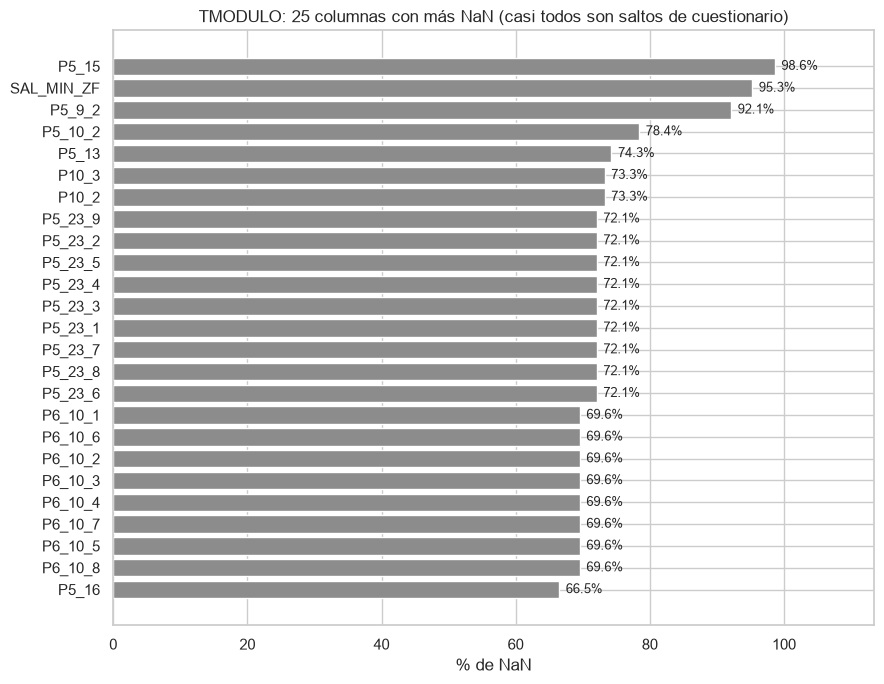

In [6]:
resumen_nulos = pd.DataFrame({
    "tabla": ["TVIVIENDA", "THOGAR", "TSDEM", "TMODULO"],
    "columnas con algún NaN": [(d.isna().any()).sum() for d in (df_tvivienda, df_thogar, df_tsdem, df_tmodulo)],
    "% de celdas NaN": [d.isna().sum().sum() / d.size * 100 for d in (df_tvivienda, df_thogar, df_tsdem, df_tmodulo)],
})
display(resumen_nulos)

top_nulos = df_tmodulo.isna().mean().mul(100).sort_values(ascending=False)
top_nulos = top_nulos[top_nulos > 0].head(25)
barras(top_nulos.iloc[::-1].iloc[::-1], "TMODULO: 25 columnas con más NaN (casi todos son saltos de cuestionario)",
       xlabel="% de NaN", archivo="01_nulos_tmodulo.png", figsize=(9, 7), color=GRIS)

In [7]:
# Auditoría de saltos: para cada pregunta condicionada, ¿el NaN coincide exactamente con quien NO debía responder?
tm, th, tv = df_tmodulo, df_thogar, df_tvivienda
tiene_credito_viv = (tv[["P1_8_1", "P1_8_2", "P1_8_3"]] == 1).any(axis=1)
reglas = [
    ("TVIVIENDA", "P1_9", tv, (tv["P1_5"] == 1) & tiene_credito_viv, "1.9 solo propietarios con crédito (P1_8 = 1 en 1, 2 o 3)"),
    ("TVIVIENDA", "P1_10", tv, tv["P1_9"] == 2, "1.10 solo si están pagando la vivienda (P1_9 = 2)"),
    ("THOGAR", "P4_4_1", th, th["FILTRO_S4_1"] == 2, "4.4 a 4.9 solo hogares NO unipersonales"),
    ("THOGAR", "P4_8_1", th, th["P4_7_1"] == 1, "4.8 solo si hay deuda en 4.7"),
    ("TMODULO", "P5_18_1", tm, tm["P5_17"].isin([1, 2, 3]), "5.18 solo empleados/jornaleros/ayudantes con pago"),
    ("TMODULO", "P6_4", tm, tm["FILTRO_S6_1"] == 1, "6.4 solo con ahorro"),
    ("TMODULO", "P6_7", tm, tm["FILTRO_S6_2"] == 1, "6.7 solo con deuda"),
    ("TMODULO", "P6_10_1", tm, tm["P6_9"] == 2, "6.10 solo si el ingreso no alcanzó"),
    ("TMODULO", "P6_11_1", tm, tm["P6_9"] == 1, "6.11 solo si sí alcanzó"),
    ("TMODULO", "P8_5_1", tm, tm["P8_4"] > 0, "8.5 solo si preocupación > 0"),
    ("TMODULO", "P10_2", tm, tm["P10_1"] == 1, "10.2 solo si conoce CONDUSEF"),
]
filas = []
for tabla, col, d, debia, desc in reglas:
    resp = d[col].notna()
    filas.append({"tabla": tabla, "pregunta": col, "regla": desc, "debía responder": int(debia.sum()),
                  "NaN esperados": int((~debia & ~resp).sum()),
                  "NaN inesperados": int((debia & ~resp).sum()),
                  "respuestas fuera de regla": int((~debia & resp).sum())})
aud = pd.DataFrame(filas)
display(aud)
print("Si 'NaN inesperados' y 'respuestas fuera de regla' son ~0, el NaN es estructural y NO debe imputarse.")

,tabla,pregunta,regla,debía responder,NaN esperados,NaN inesperados,respuestas fuera de regla
0,TVIVIENDA,P1_9,1.9 solo propietarios con crédito (P1_8 = 1 en...,4235,15966,0,0
1,TVIVIENDA,P1_10,1.10 solo si están pagando la vivienda (P1_9 = 2),1888,18313,0,0
2,THOGAR,P4_4_1,4.4 a 4.9 solo hogares NO unipersonales,17341,3107,0,0
3,THOGAR,P4_8_1,4.8 solo si hay deuda en 4.7,4897,15551,0,0
4,TMODULO,P5_18_1,5.18 solo empleados/jornaleros/ayudantes con pago,9563,10885,0,0
5,TMODULO,P6_4,6.4 solo con ahorro,10732,9716,0,0
6,TMODULO,P6_7,6.7 solo con deuda,9049,11399,0,0
7,TMODULO,P6_10_1,6.10 solo si el ingreso no alcanzó,6224,14224,0,0
8,TMODULO,P6_11_1,6.11 solo si sí alcanzó,14224,6224,0,0
9,TMODULO,P8_5_1,8.5 solo si preocupación > 0,16572,3876,0,0


Si 'NaN inesperados' y 'respuestas fuera de regla' son ~0, el NaN es estructural y NO debe imputarse.


**Regla práctica:** analizar cada pregunta condicionada solo sobre su **universo elegible** y nunca rellenar con 0. Más abajo cada gráfica indica su universo.

Un caso especial son los **bloques de opción múltiple** (p. ej. 8.5, 8.6, 7.5, 5.23): vienen codificados `1` = mencionó, `0` = no mencionó, `NaN` = la pregunta no aplicaba. Se tratan distinto a los Sí/No (`1`/`2`).

## 4. Viviendas y hogares
Factor de expansión: `FAC_VIV` (viviendas) y `FAC_HOG` (hogares).

### 4.1 Tenencia, adquisición y escrituras (TVIVIENDA)

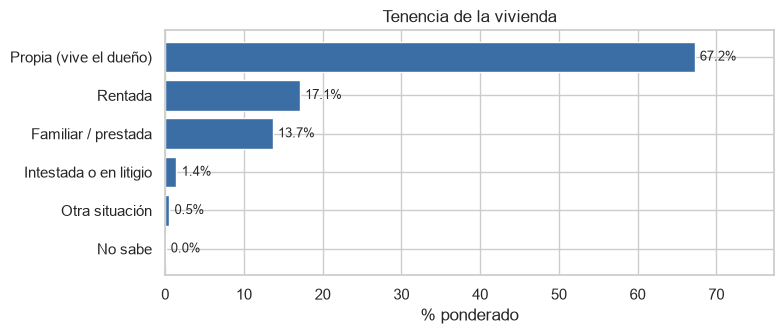

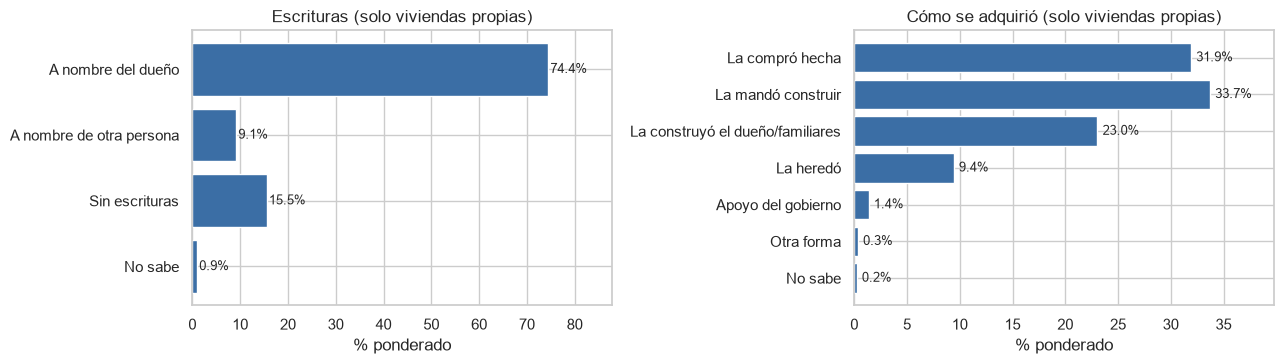

In [8]:
ten = {1: "Propia (vive el dueño)", 2: "Rentada", 3: "Familiar / prestada", 4: "Intestada o en litigio", 5: "Otra situación", 9: "No sabe"}
t1 = pct_ponderado(df_tvivienda["P1_5"], df_tvivienda["FAC_VIV"], ten, list(ten.values()))
barras(t1, "Tenencia de la vivienda", archivo="02_tenencia.png", figsize=(8, 3.5))

esc = {1: "A nombre del dueño", 2: "A nombre de otra persona", 3: "Sin escrituras", 9: "No sabe"}
adq = {1: "La compró hecha", 2: "La mandó construir", 3: "La construyó el dueño/familiares", 4: "La heredó",
       5: "Apoyo del gobierno", 6: "Otra forma", 9: "No sabe"}
prop = df_tvivienda["P1_5"] == 1
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col, mapa, tit in [(axes[0], "P1_6", esc, "Escrituras (solo viviendas propias)"),
                           (axes[1], "P1_7", adq, "Cómo se adquirió (solo viviendas propias)")]:
    s = pct_ponderado(df_tvivienda.loc[prop, col], df_tvivienda.loc[prop, "FAC_VIV"], mapa, list(mapa.values()))
    ax.barh(s.index, s.values, color=AZUL)
    ax.invert_yaxis()
    for i, v in enumerate(s.values):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.set(title=tit, xlabel="% ponderado", xlim=(0, s.max() * 1.18))
plt.tight_layout()
fig.savefig(SALIDAS / "03_escrituras_adquisicion.png", dpi=130, bbox_inches="tight")
plt.show()

### 4.2 Crédito de vivienda y bienes del hogar

,reactivo,% sí,n válido,% no sabe
0,Ahorros o recursos propios,76.60,11981,0.60
1,Crédito INFONAVIT/FOVISSSTE,23.10,11947,0.80
2,Crédito de banco o institución financiera,9.40,11943,0.90
3,"Préstamo de familiares, amistades o agiotistas",5.80,11945,0.90
4,Apoyo o subsidio del gobierno,3.50,11950,0.90


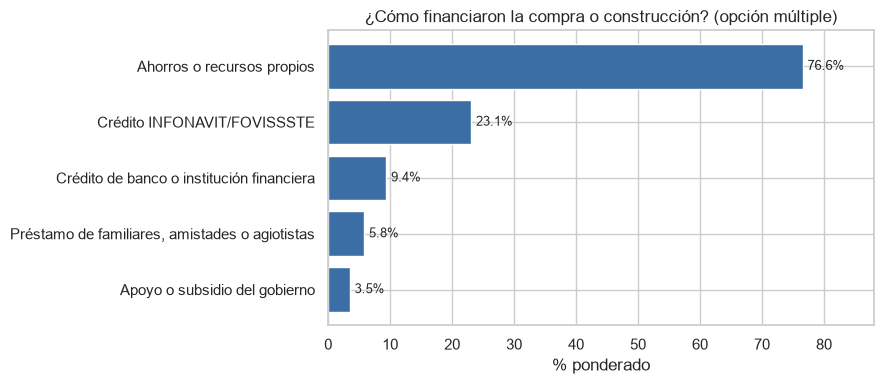


Estado de la deuda en viviendas propias con crédito (P1_9; INFONAVIT/FOVISSSTE, banco o préstamo personal):


,%
Totalmente pagada,57.90
La están pagando,41.30
La dejaron de pagar,0.40
No sabe,0.40


In [9]:
# Financiamiento (P1_8): solo si el dueño la compró hecha, la mandó construir o la construyó (P1_7 = 1, 2 o 3)
compra = df_tvivienda["P1_7"].isin([1, 2, 3])
fin = bloque(df_tvivienda, [f"P1_8_{i}" for i in range(1, 6)],
             ["Crédito INFONAVIT/FOVISSSTE", "Crédito de banco o institución financiera",
              "Préstamo de familiares, amistades o agiotistas", "Apoyo o subsidio del gobierno", "Ahorros o recursos propios"],
             "FAC_VIV", universo=compra)
bloque_barras(fin, "¿Cómo financiaron la compra o construcción? (opción múltiple)", "04_financiamiento_vivienda.png")

cred = tiene_credito_viv & prop
print("\nEstado de la deuda en viviendas propias con crédito (P1_9; INFONAVIT/FOVISSSTE, banco o préstamo personal):")
display(pct_ponderado(df_tvivienda.loc[cred, "P1_9"], df_tvivienda.loc[cred, "FAC_VIV"],
                      {1: "Totalmente pagada", 2: "La están pagando", 3: "La dejaron de pagar", 9: "No sabe"}).round(1).to_frame("%"))

,reactivo,% sí,n válido,% no sabe
0,Teléfono celular,93.60,20201,0.00
1,Refrigerador,89.80,20201,0.00
2,Lavadora,74.80,20201,0.00
3,Internet,72.40,20201,0.00
4,Microondas,48.00,20201,0.00
5,Automóvil o camioneta,46.40,20201,0.00
6,TV de paga,40.70,20201,0.00
7,Computadora/laptop/tablet,38.30,20201,0.00
8,Línea telefónica fija,36.40,20201,0.00
9,Streaming de pago,25.50,20201,0.00


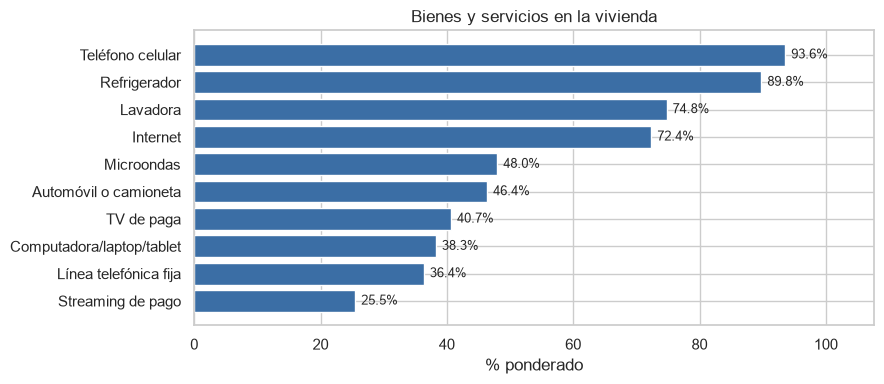

Distribución del número de bienes (0 a 10), % de viviendas:


x,0,1,2,3,4,5,6,7,8,9,10
%,1.50,4.50,6.90,9.80,12.50,13.00,11.90,12.50,10.50,9.30,7.70


In [10]:
bienes = ["Refrigerador", "Lavadora", "Microondas", "Automóvil o camioneta", "Computadora/laptop/tablet", "Línea telefónica fija",
          "Teléfono celular", "Internet", "TV de paga", "Streaming de pago"]
bn = bloque(df_tvivienda, [f"P1_4_{i:02d}" for i in range(1, 11)], bienes, "FAC_VIV", validos=(1, 2))
bloque_barras(bn, "Bienes y servicios en la vivienda", "05_bienes.png")

n_bienes = (df_tvivienda[[f"P1_4_{i:02d}" for i in range(1, 11)]] == 1).sum(axis=1)
print("Distribución del número de bienes (0 a 10), % de viviendas:")
display(pct_ponderado(n_bienes, df_tvivienda["FAC_VIV"]).round(1).to_frame("%").T)

### 4.3 Tamaño y composición del hogar (THOGAR + TSDEM)

Hogares sin personas en TSDEM: 0


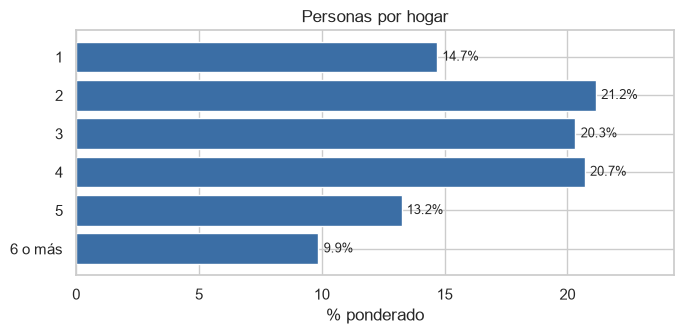

Tamaño medio del hogar (ponderado): 3.35 personas

Consistencia: FILTRO_S4_1 (1 = unipersonal) vs. personas = 1


1 persona en TSDEM,False,True
FILTRO_S4_1,,
1,0,3107
2,17341,0



Jefatura femenina (% de hogares): 34.3%
Edad media de la jefatura: 51.2 años


In [11]:
tam = df_tsdem.groupby("LLAVEHOG").size().rename("personas")
hog = df_thogar.merge(tam, on="LLAVEHOG", how="left", validate="one_to_one")
print("Hogares sin personas en TSDEM:", hog["personas"].isna().sum())

grupos = pd.cut(hog["personas"], [0, 1, 2, 3, 4, 5, 100], labels=["1", "2", "3", "4", "5", "6 o más"])
dist = pct_ponderado(grupos, hog["FAC_HOG"])
barras(dist, "Personas por hogar", archivo="06_tamano_hogar.png", figsize=(7, 3.5))
print(f"Tamaño medio del hogar (ponderado): {media_pond(hog['personas'].astype(float), hog['FAC_HOG']):.2f} personas")

# Cruce de consistencia: hogar unipersonal según FILTRO_S4_1 vs tamaño real
print("\nConsistencia: FILTRO_S4_1 (1 = unipersonal) vs. personas = 1")
display(pd.crosstab(hog["FILTRO_S4_1"], hog["personas"].eq(1), rownames=["FILTRO_S4_1"], colnames=["1 persona en TSDEM"]))

jefe = df_tsdem[df_tsdem["PAREN"] == 1]
print(f"\nJefatura femenina (% de hogares): {(jefe['SEXO'] == 2).mul(jefe['FAC_HOG']).sum() / jefe['FAC_HOG'].sum() * 100:.1f}%")
print(f"Edad media de la jefatura: {media_pond(jefe['EDAD'].where(jefe['EDAD'] < 98), jefe['FAC_HOG']):.1f} años")

### 4.4 Ingreso del hogar y privación económica (THOGAR)
`P4_3` es el **rango** de ingreso mensual del hogar (11 tramos del cuestionario). `P4_10` pregunta si hubo dinero suficiente en los últimos 3 meses.

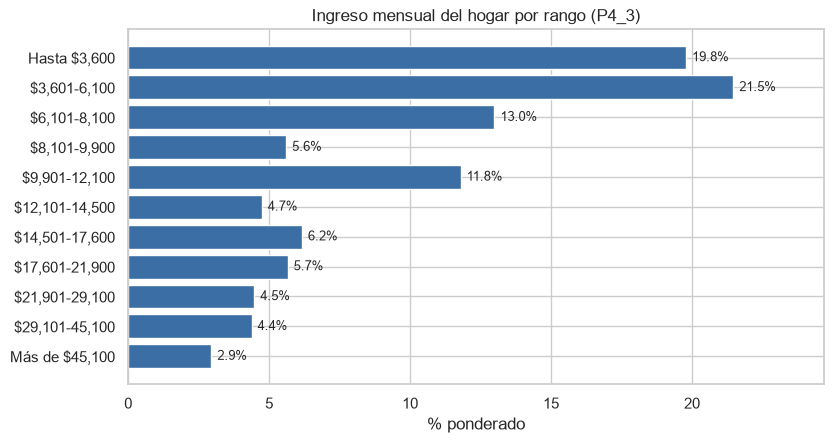

,reactivo,% sin dinero suficiente,n válido,% no sabe
5,Entretenimiento,58.80,20403,0.20
4,Mantenimiento de casa / renta o crédito,40.60,20425,0.10
3,Ropa y calzado,39.80,20427,0.10
2,Medicinas / atención médica,26.20,20420,0.10
1,Transporte,20.70,20427,0.10
0,Comida diaria,15.50,20437,0.10


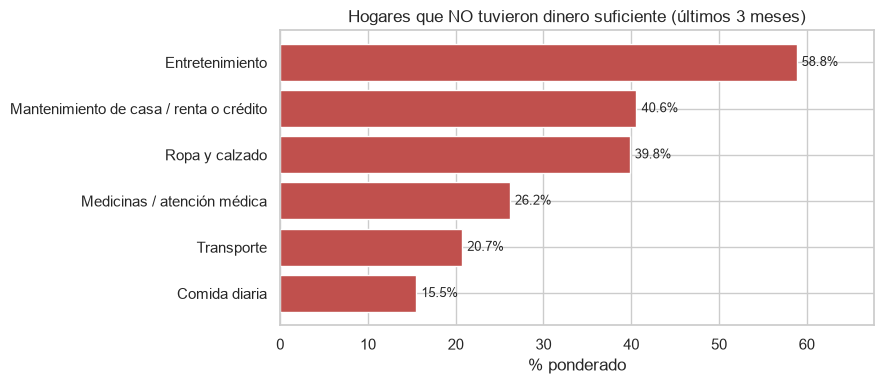

In [12]:
rangos = {1: "Hasta $3,600", 2: "$3,601-6,100", 3: "$6,101-8,100", 4: "$8,101-9,900", 5: "$9,901-12,100", 6: "$12,101-14,500",
          7: "$14,501-17,600", 8: "$17,601-21,900", 9: "$21,901-29,100", 10: "$29,101-45,100", 11: "Más de $45,100"}
r = pct_ponderado(df_thogar["P4_3"], df_thogar["FAC_HOG"], rangos, list(rangos.values()))
barras(r, "Ingreso mensual del hogar por rango (P4_3)", archivo="07_ingreso_hogar_rangos.png", figsize=(8.5, 4.6))

priv = bloque(df_thogar, [f"P4_10_{i}" for i in range(1, 7)],
              ["Comida diaria", "Mantenimiento de casa / renta o crédito", "Ropa y calzado", "Transporte", "Medicinas / atención médica", "Entretenimiento"],
              "FAC_HOG")
priv["% sin dinero suficiente"] = 100 - priv["% sí"]
display(priv[["reactivo", "% sin dinero suficiente", "n válido", "% no sabe"]].sort_values("% sin dinero suficiente", ascending=False).round(1))
barras(priv.set_index("reactivo")["% sin dinero suficiente"].sort_values(ascending=False),
       "Hogares que NO tuvieron dinero suficiente (últimos 3 meses)", archivo="08_privacion.png", color=ROJO, figsize=(9, 4))

### 4.5 Acceso a servicios financieros del hogar (THOGAR; hogares no unipersonales)
El módulo 4.4–4.9 **no se pregunta a hogares unipersonales** (15.2 % de los hogares, su `NaN` es estructural). Por eso el universo es `FILTRO_S4_1 == 2`.

,grupo,reactivo,% sí,n válido
0,Cuentas,Cuenta o tarjeta de banco,55.40,17263
1,Cuentas,Cuenta de ahorro para el retiro (Afore),43.00,17106
0,Créditos,Tarjeta departamental,36.90,17272
1,Créditos,Tarjeta o crédito de banco/personal,23.20,17274
2,Créditos,Crédito de vivienda,15.50,17279
3,Créditos,Crédito automotriz,3.90,17292
0,Hábitos de ahorro,Ahorra dinero en casa,30.80,17287
1,Hábitos de ahorro,Ahorra en banco,19.40,17266
2,Hábitos de ahorro,Ahorra en Afore,15.20,17202
3,Hábitos de ahorro,Ahorra en tandas/cajas,14.70,17286


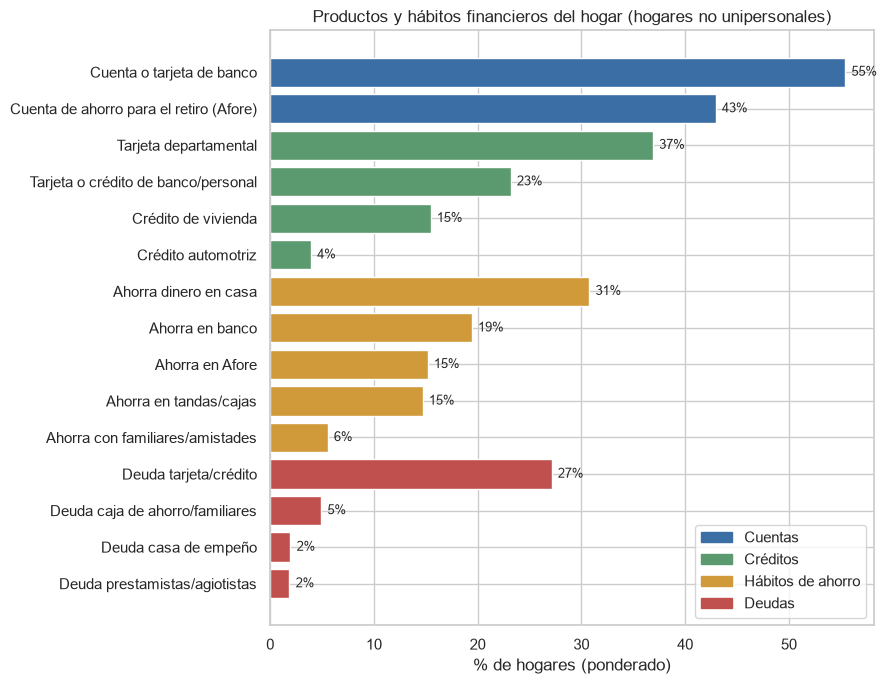

In [13]:
noun = df_thogar["FILTRO_S4_1"] == 2
tenencia = pd.concat([
    bloque(df_thogar, ["P4_4_1", "P4_4_2"], ["Cuenta o tarjeta de banco", "Cuenta de ahorro para el retiro (Afore)"], "FAC_HOG", universo=noun).assign(grupo="Cuentas"),
    bloque(df_thogar, [f"P4_5_{i}" for i in range(1, 5)], ["Tarjeta departamental", "Tarjeta o crédito de banco/personal", "Crédito automotriz", "Crédito de vivienda"], "FAC_HOG", universo=noun).assign(grupo="Créditos"),
    bloque(df_thogar, [f"P4_6_{i}" for i in range(1, 6)], ["Ahorra en banco", "Ahorra en Afore", "Ahorra en tandas/cajas", "Ahorra con familiares/amistades", "Ahorra dinero en casa"], "FAC_HOG", universo=noun).assign(grupo="Hábitos de ahorro"),
    bloque(df_thogar, [f"P4_7_{i}" for i in range(1, 5)], ["Deuda tarjeta/crédito", "Deuda caja de ahorro/familiares", "Deuda casa de empeño", "Deuda prestamistas/agiotistas"], "FAC_HOG", universo=noun).assign(grupo="Deudas"),
])
display(tenencia[["grupo", "reactivo", "% sí", "n válido"]].round(1))

fig, ax = plt.subplots(figsize=(9, 7))
colores = {"Cuentas": AZUL, "Créditos": "#5b9a6e", "Hábitos de ahorro": "#d09a3a", "Deudas": ROJO}
t = tenencia.reset_index(drop=True)
ax.barh(t.index, t["% sí"], color=[colores[g] for g in t["grupo"]])
ax.set_yticks(t.index)
ax.set_yticklabels(t["reactivo"])
ax.invert_yaxis()
for i, v in enumerate(t["% sí"]):
    ax.text(v + 0.6, i, f"{v:.0f}%", va="center", fontsize=9)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colores.values()], labels=colores.keys(), loc="lower right")
ax.set(xlabel="% de hogares (ponderado)", title="Productos y hábitos financieros del hogar (hogares no unipersonales)")
plt.tight_layout()
fig.savefig(SALIDAS / "09_servicios_financieros_hogar.png", dpi=130, bbox_inches="tight")
plt.show()

## 5. Personas del hogar (TSDEM)
Factor de expansión: `FAC_HOG`. Edad: `97` = "97 y más"; `98` y `99` = "no sabe", se excluyen.

Edades 'no sabe' (98-99) excluidas: 165 de 67,781


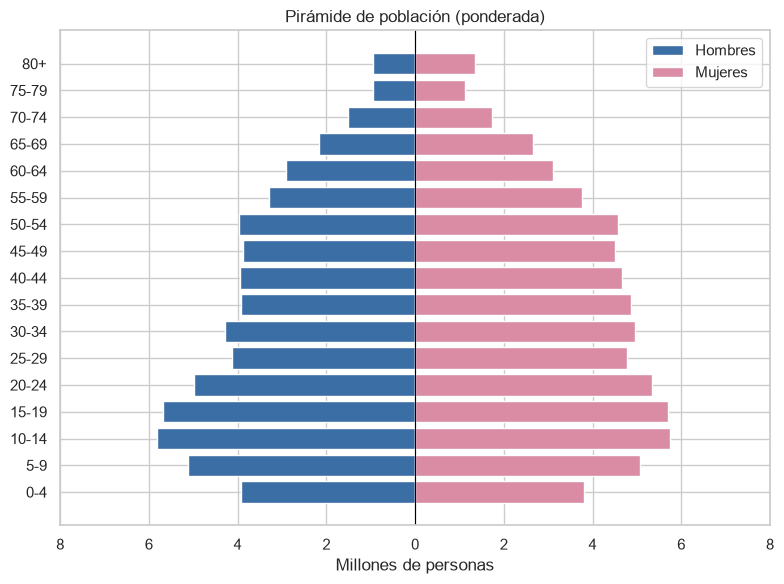

Mujeres: 52.4%  |  edad mediana: 32 años


In [14]:
t = df_tsdem.copy()
t["EDAD_L"] = t["EDAD"].where(t["EDAD"] < 98)
print(f"Edades 'no sabe' (98-99) excluidas: {t['EDAD'].ge(98).sum()} de {len(t):,}")

t["gedad"] = pd.cut(t["EDAD_L"], list(range(0, 85, 5)) + [200], right=False, labels=[f"{i}-{i+4}" for i in range(0, 80, 5)] + ["80+"])
pir = t.groupby(["gedad", "SEXO"], observed=True)["FAC_HOG"].sum().unstack() / 1e6
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(pir.index.astype(str), -pir[1], color=AZUL, label="Hombres")
ax.barh(pir.index.astype(str), pir[2], color="#d98ca3", label="Mujeres")
ax.axvline(0, color="black", lw=0.8)
ticks = ax.get_xticks()
ax.set_xticks(ticks)
ax.set_xticklabels([f"{abs(x):.0f}" for x in ticks])
ax.set(xlabel="Millones de personas", title="Pirámide de población (ponderada)")
ax.legend()
plt.tight_layout()
fig.savefig(SALIDAS / "10_piramide.png", dpi=130, bbox_inches="tight")
plt.show()
print(f"Mujeres: {pct_ponderado(t['SEXO'], t['FAC_HOG'])[2]:.1f}%  |  edad mediana: {cuantil_pond(t['EDAD_L'], t['FAC_HOG'], 0.5):.0f} años")

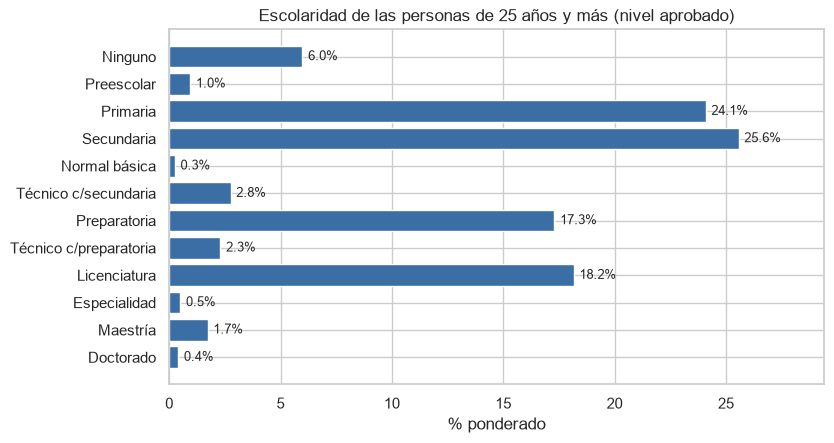

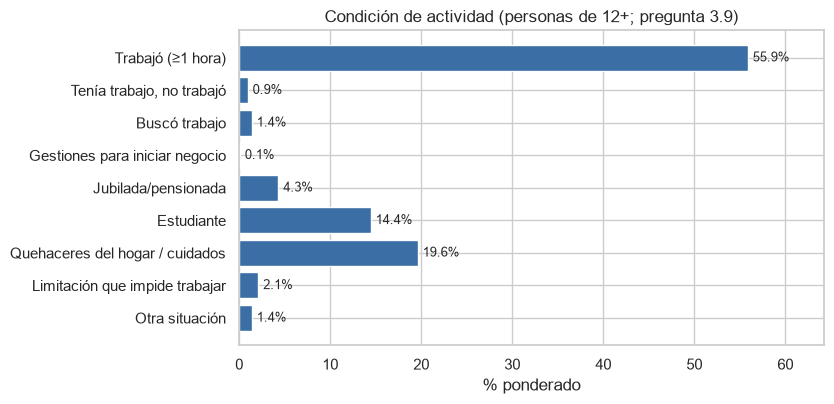

SEXO,Hombres,Mujeres
act,,
Trabajó (≥1 hora),70.70,42.80
"Tenía trabajo, no trabajó",1.20,0.60
Buscó trabajo,2.00,0.90
Gestiones para iniciar negocio,0.10,0.10
Jubilada/pensionada,5.40,3.30
Estudiante,14.50,14.40
Quehaceres del hogar / cuidados,1.70,35.40
Limitación que impide trabajar,2.40,1.70
Otra situación,1.90,0.90


In [15]:
niv = {0: "Ninguno", 1: "Preescolar", 2: "Primaria", 3: "Secundaria", 4: "Normal básica", 5: "Técnico c/secundaria",
       6: "Preparatoria", 7: "Técnico c/preparatoria", 8: "Licenciatura", 9: "Especialidad", 10: "Maestría", 11: "Doctorado"}
adultos = t[(t["EDAD_L"] >= 25)]
esc25 = pct_ponderado(adultos["NIV"].where(adultos["NIV"] != 99), adultos["FAC_HOG"], niv, list(niv.values()))
barras(esc25, "Escolaridad de las personas de 25 años y más (nivel aprobado)", archivo="11_escolaridad.png", figsize=(8.5, 4.6))

act = {1: "Trabajó (≥1 hora)", 2: "Tenía trabajo, no trabajó", 3: "Buscó trabajo", 4: "Gestiones para iniciar negocio", 5: "Jubilada/pensionada",
       6: "Estudiante", 7: "Quehaceres del hogar / cuidados", 8: "Limitación que impide trabajar", 9: "Otra situación"}
p12 = t[t["EDAD_L"] >= 12]
a = pct_ponderado(p12["P3_9"], p12["FAC_HOG"], act, list(act.values()))
barras(a, "Condición de actividad (personas de 12+; pregunta 3.9)", archivo="12_actividad.png", figsize=(8.5, 4.2))

# Actividad por sexo
tab = (p12.assign(act=p12["P3_9"].map(act)).groupby(["act", "SEXO"])["FAC_HOG"].sum().unstack())
tab = (tab / tab.sum() * 100).rename(columns={1: "Hombres", 2: "Mujeres"}).reindex(list(act.values()))
display(tab.round(1))

### 5.1 ¿La persona elegida se parece a la población adulta?
La entrevista individual se hace a una sola persona por hogar; con los factores de `TMODULO` debe reproducir la estructura por edad de los adultos. Es un chequeo de calidad del diseño.

,Adultos en TSDEM (pond.),Persona elegida (pond. FAC_ELE),Persona elegida (SIN ponderar)
18-24,15.80,15.50,12.30
25-34,19.60,19.10,19.90
35-44,18.80,18.40,19.60
45-54,18.30,19.10,17.90
55-64,14.10,14.20,14.40
65+,13.40,13.60,15.90


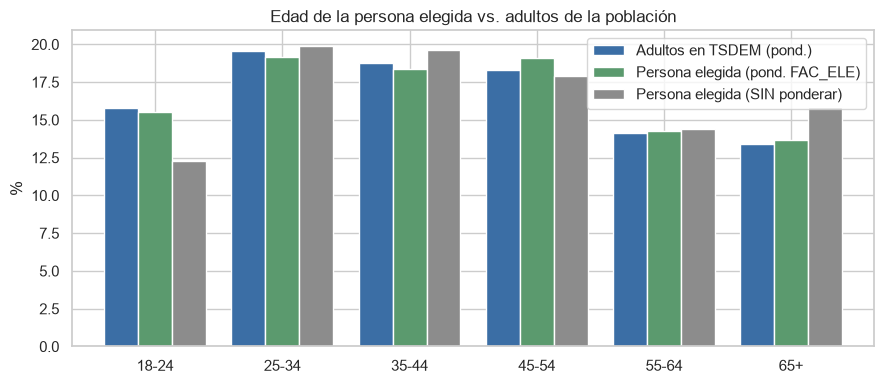

Si la serie sin ponderar se aleja de la ponderada, ponderar es indispensable.
Adultos 18+ según TSDEM: 92.6 M | según FAC_ELE: 92.8 M


In [16]:
ad = t[(t["EDAD_L"] >= 18)].copy()
bins, labs = [18, 25, 35, 45, 55, 65, 200], ["18-24", "25-34", "35-44", "45-54", "55-64", "65+"]
pop = pct_ponderado(pd.cut(ad["EDAD_L"], bins, right=False, labels=labs), ad["FAC_HOG"])
el = df_tmodulo.copy()
mod = pct_ponderado(pd.cut(el["EDAD_V"].where(el["EDAD_V"] < 98), bins, right=False, labels=labs), el["FAC_ELE"])
sin_pond = pd.cut(el["EDAD_V"].where(el["EDAD_V"] < 98), bins, right=False, labels=labs).value_counts(normalize=True).reindex(labs) * 100
comp = pd.DataFrame({"Adultos en TSDEM (pond.)": pop, "Persona elegida (pond. FAC_ELE)": mod, "Persona elegida (SIN ponderar)": sin_pond})
display(comp.round(1))
ax = comp.plot(kind="bar", figsize=(9, 4), color=[AZUL, "#5b9a6e", GRIS], width=0.8)
ax.set(ylabel="%", title="Edad de la persona elegida vs. adultos de la población", xlabel="")
plt.xticks(rotation=0)
plt.tight_layout()
ax.figure.savefig(SALIDAS / "13_representatividad_edad.png", dpi=130, bbox_inches="tight")
plt.show()
print("Si la serie sin ponderar se aleja de la ponderada, ponderar es indispensable.")
print(f"Adultos 18+ según TSDEM: {ad['FAC_HOG'].sum()/1e6:.1f} M | según FAC_ELE: {df_tmodulo['FAC_ELE'].sum()/1e6:.1f} M")

## 6. La persona elegida: ingreso, ahorro y deuda (TMODULO)
Factor de expansión: `FAC_ELE`. Montos: `99999` = no sabe, `98000` = tope "98 000 y más" (se conserva como valor).

### 6.1 Ingreso personal

In [17]:
m = df_tmodulo.copy()
w = "FAC_ELE"
# Universo: quienes declararon una situación en P5_17 (trabajaron) tienen P5_19; el resto tiene NaN estructural
m["ing"] = m["P5_19"].where(~m["P5_19"].isin([99999]))
m["periodo"] = m["P5_19A"].map({1: "Semana", 2: "Quincena", 3: "Mes", 4: "Año"})
print("Estado de P5_19 (¿cuánto gana por trabajar?):")
estado = pd.Series({
    "No aplica (NaN: no trabajó)": m["P5_19"].isna().sum(),
    "No recibe ingresos (0)": (m["P5_19"] == 0).sum(),
    "No sabe (99999)": (m["P5_19"] == 99999).sum(),
    "Declaró un monto > 0": ((m["P5_19"] > 0) & (m["P5_19"] < 99999)).sum(),
})
display(estado.to_frame("n").assign(**{"%": lambda d: d["n"] / d["n"].sum() * 100}).round(1))
print("\nINGRESO_M (variable derivada de INEGI) está vacío en:", f"{m['INGRESO_M'].isna().mean():.1%}", "de las personas elegidas")

Estado de P5_19 (¿cuánto gana por trabajar?):


,n,%
No aplica (NaN: no trabajó),6108,29.90
No recibe ingresos (0),386,1.90
No sabe (99999),636,3.10
Declaró un monto > 0,13318,65.10



INGRESO_M (variable derivada de INEGI) está vacío en: 33.0% de las personas elegidas


Ingreso mensual personal (solo quienes reportan > 0), percentiles ponderados:


,P10,P25,P50,P75,P90
$ mensuales,"2,150.00","4,300.00","7,000.00","10,750.00","18,000.00"


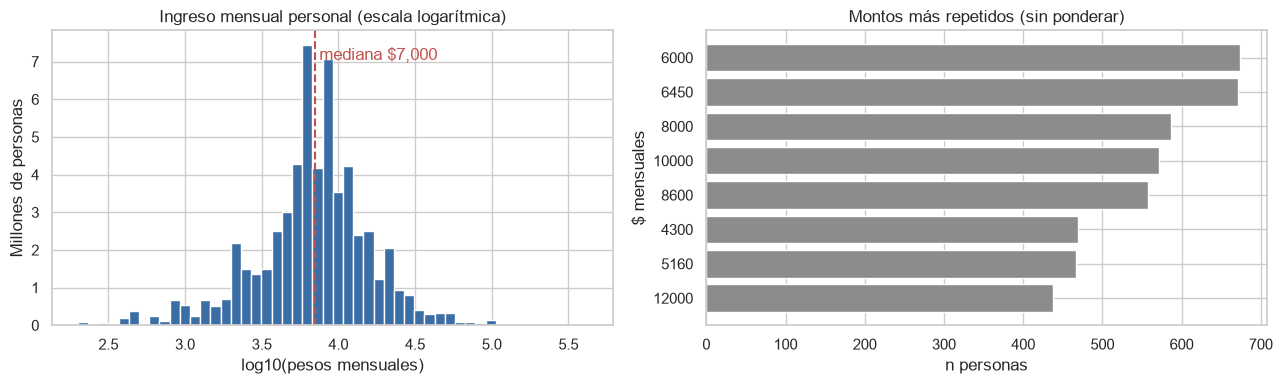

Hay 'redondeo' evidente (6,000, 8,000, 10,000…) y montos como 6,450 u 8,600 que son mensualizaciones de pagos semanales/quincenales.


In [18]:
con = m.dropna(subset=["INGRESO_M"])
con = con[con["INGRESO_M"] > 0]
q = {p: cuantil_pond(con["INGRESO_M"], con[w], p) for p in (0.1, 0.25, 0.5, 0.75, 0.9)}
print("Ingreso mensual personal (solo quienes reportan > 0), percentiles ponderados:")
display(pd.Series(q, name="$ mensuales").rename(lambda p: f"P{int(p*100)}").to_frame().T.round(0))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(np.log10(con["INGRESO_M"]), bins=50, weights=con[w] / 1e6, color=AZUL)
axes[0].set(title="Ingreso mensual personal (escala logarítmica)", xlabel="log10(pesos mensuales)", ylabel="Millones de personas")
for p, c in [(0.5, ROJO)]:
    axes[0].axvline(np.log10(q[p]), color=c, ls="--")
    axes[0].text(np.log10(q[p]) + 0.03, axes[0].get_ylim()[1] * 0.9, f"mediana ${q[p]:,.0f}", color=c)
pico = con["INGRESO_M"].value_counts().head(8)
axes[1].barh(pico.index.astype(int).astype(str), pico.values, color=GRIS)
axes[1].invert_yaxis()
axes[1].set(title="Montos más repetidos (sin ponderar)", xlabel="n personas", ylabel="$ mensuales")
plt.tight_layout()
fig.savefig(SALIDAS / "14_ingreso_personal.png", dpi=130, bbox_inches="tight")
plt.show()
print("Hay 'redondeo' evidente (6,000, 8,000, 10,000…) y montos como 6,450 u 8,600 que son mensualizaciones de pagos semanales/quincenales.")

### 6.2 Situación laboral y prestaciones

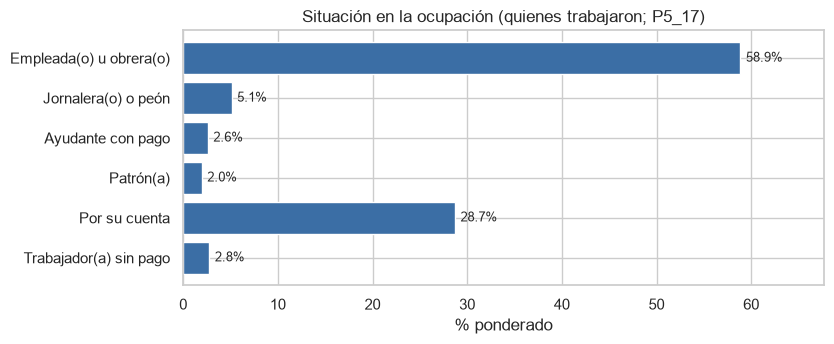

,reactivo,% sí,n válido,% no sabe
0,Servicio médico (IMSS/ISSSTE/PEMEX),53.90,9540,0.30
1,Vacaciones con goce de sueldo,50.60,9530,0.40
2,Fondo de retiro (SAR/Afore),44.70,9501,0.60
3,Crédito de vivienda (INFONAVIT/FOVISSSTE),38.70,9510,0.70
4,Préstamos personales / caja de ahorro,31.50,9509,0.70
5,Licencia de cuidados,23.80,9396,1.90
6,Seguro de gastos médicos privado,13.20,9532,0.40


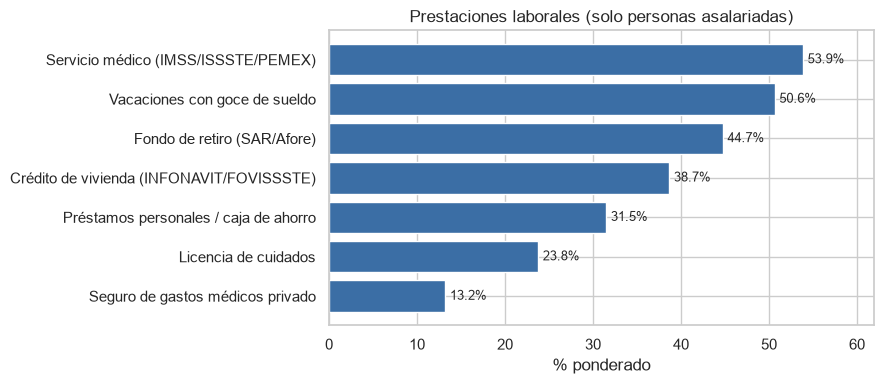

In [19]:
lab = {1: "Empleada(o) u obrera(o)", 2: "Jornalera(o) o peón", 3: "Ayudante con pago", 4: "Patrón(a)", 5: "Por su cuenta", 6: "Trabajador(a) sin pago"}
barras(pct_ponderado(m["P5_17"], m[w], lab, list(lab.values())), "Situación en la ocupación (quienes trabajaron; P5_17)",
       archivo="15_situacion_ocupacion.png", figsize=(8.5, 3.6))

asal = m["P5_17"].isin([1, 2, 3])
prest = bloque(m, [f"P5_18_{i}" for i in range(1, 8)],
               ["Servicio médico (IMSS/ISSSTE/PEMEX)", "Seguro de gastos médicos privado", "Crédito de vivienda (INFONAVIT/FOVISSSTE)",
                "Fondo de retiro (SAR/Afore)", "Vacaciones con goce de sueldo", "Préstamos personales / caja de ahorro", "Licencia de cuidados"],
               w, universo=asal)
bloque_barras(prest, "Prestaciones laborales (solo personas asalariadas)", "16_prestaciones.png")

### 6.3 Ahorro formal e informal

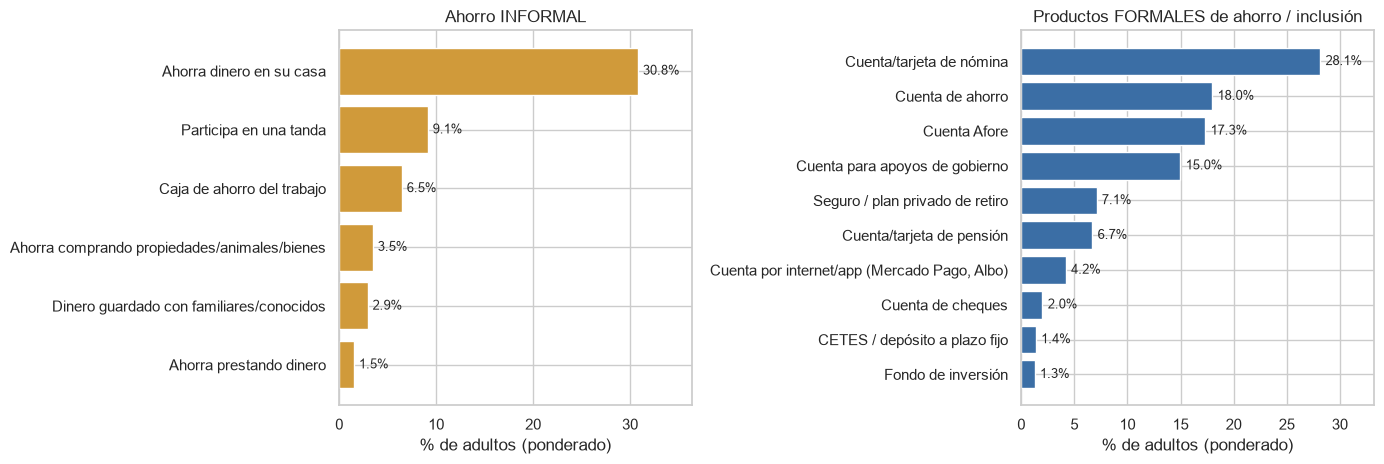

Tiene al menos un instrumento formal de ahorro/inversión (cuenta de ahorro, cheques, CETES, fondos, app): 20.6%
Tiene algún ahorro actual (P6_3 = 1): 42.7%
Cuánto equivale lo ahorrado a sus ingresos (P6_4; solo quienes ahorran):


,≤ 1 quincena,≤ 1 mes,≤ 2 meses,≤ 3 meses,> 3 meses,No sabe
%,47.10,16.30,6.80,3.60,8.40,17.90


In [20]:
informal = bloque(m, [f"P6_1_{i}" for i in range(1, 7)],
                  ["Ahorra prestando dinero", "Ahorra comprando propiedades/animales/bienes", "Caja de ahorro del trabajo",
                   "Dinero guardado con familiares/conocidos", "Participa en una tanda", "Ahorra dinero en su casa"], w)
formal = bloque(m, [f"P6_2_{i:02d}" for i in range(1, 11)],
                ["Cuenta/tarjeta de nómina", "Cuenta/tarjeta de pensión", "Cuenta para apoyos de gobierno", "Cuenta de ahorro", "Cuenta de cheques",
                 "CETES / depósito a plazo fijo", "Fondo de inversión", "Cuenta por internet/app (Mercado Pago, Albo)", "Seguro / plan privado de retiro",
                 "Cuenta Afore"], w)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, d, tit, c in [(axes[0], informal, "Ahorro INFORMAL", "#d09a3a"), (axes[1], formal, "Productos FORMALES de ahorro / inclusión", AZUL)]:
    ax.barh(d["reactivo"], d["% sí"], color=c)
    ax.invert_yaxis()
    for i, v in enumerate(d["% sí"]):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.set(title=tit, xlabel="% de adultos (ponderado)", xlim=(0, d["% sí"].max() * 1.18))
plt.tight_layout()
fig.savefig(SALIDAS / "17_ahorro.png", dpi=130, bbox_inches="tight")
plt.show()

m["ahorro_formal_basico"] = ((m[["P6_2_04", "P6_2_05", "P6_2_06", "P6_2_07", "P6_2_08"]] == 1).any(axis=1)).astype(float)
print(f"Tiene al menos un instrumento formal de ahorro/inversión (cuenta de ahorro, cheques, CETES, fondos, app): {media_pond(m['ahorro_formal_basico'], m[w])*100:.1f}%")
print(f"Tiene algún ahorro actual (P6_3 = 1): {pct_ponderado(m['P6_3'], m[w]).get(1, 0):.1f}%")
print("Cuánto equivale lo ahorrado a sus ingresos (P6_4; solo quienes ahorran):")
display(pct_ponderado(m["P6_4"], m[w], {1: "≤ 1 quincena", 2: "≤ 1 mes", 3: "≤ 2 meses", 4: "≤ 3 meses", 5: "> 3 meses", 9: "No sabe"},
                      ["≤ 1 quincena", "≤ 1 mes", "≤ 2 meses", "≤ 3 meses", "> 3 meses", "No sabe"]).round(1).to_frame("%").T)

### 6.4 Deuda

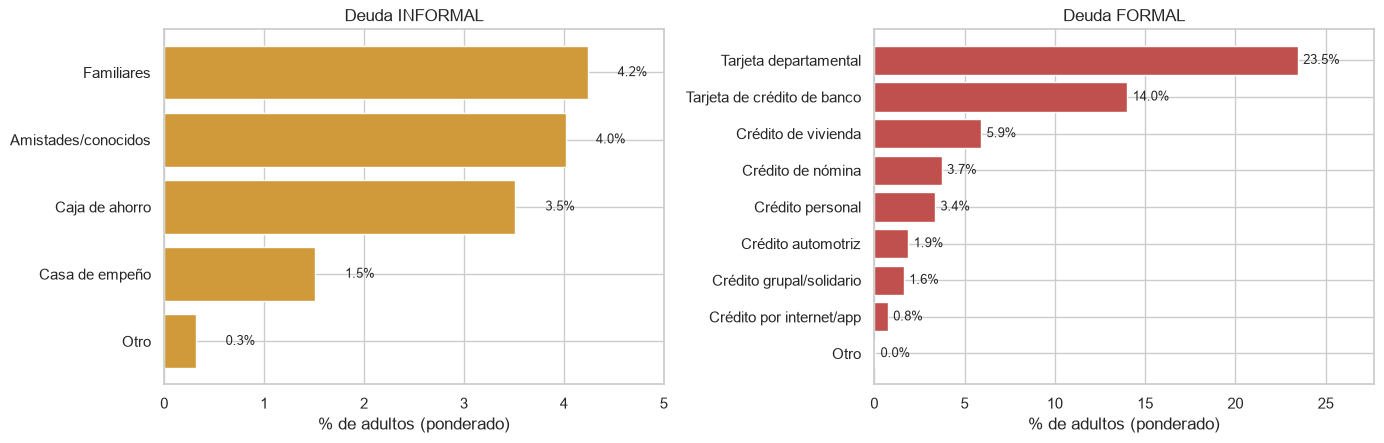

Tiene al menos una deuda (FILTRO 2): 41.9%
Entre quienes tienen deuda, % que se atrasó (P6_7): 23.8%

Percepción del nivel de endeudamiento (P6_8; personas con alguna deuda según FILTRO 2):


,Excesivo,Alto,Moderado,Bajo,Dice no tener deudas,No sabe
%,4.40,9.60,42.30,30.20,13.30,0.30


Ojo: 13.3% de quienes declararon alguna deuda en 6.5/6.6 responden 'no tiene deudas' en 6.8: hay una brecha entre deuda declarada y deuda percibida.


In [21]:
inf = bloque(m, [f"P6_5_{i}" for i in range(1, 6)], ["Caja de ahorro", "Casa de empeño", "Amistades/conocidos", "Familiares", "Otro"], w)
fm = bloque(m, [f"P6_6_{i}" for i in range(1, 10)],
            ["Tarjeta departamental", "Tarjeta de crédito de banco", "Crédito de nómina", "Crédito personal", "Crédito automotriz",
             "Crédito de vivienda", "Crédito grupal/solidario", "Crédito por internet/app", "Otro"], w)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, d, tit, c in [(axes[0], inf, "Deuda INFORMAL", "#d09a3a"), (axes[1], fm, "Deuda FORMAL", ROJO)]:
    ax.barh(d["reactivo"], d["% sí"], color=c)
    ax.invert_yaxis()
    for i, v in enumerate(d["% sí"]):
        ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.set(title=tit, xlabel="% de adultos (ponderado)", xlim=(0, d["% sí"].max() * 1.18))
plt.tight_layout()
fig.savefig(SALIDAS / "18_deuda.png", dpi=130, bbox_inches="tight")
plt.show()

deuda = m["FILTRO_S6_2"] == 1
print(f"Tiene al menos una deuda (FILTRO 2): {media_pond(deuda.astype(float), m[w])*100:.1f}%")
print(f"Entre quienes tienen deuda, % que se atrasó (P6_7): {pct_ponderado(m.loc[deuda, 'P6_7'], m.loc[deuda, w])[1]:.1f}%")
percep = {1: "Excesivo", 2: "Alto", 3: "Moderado", 4: "Bajo", 5: "Dice no tener deudas", 9: "No sabe"}
print("\nPercepción del nivel de endeudamiento (P6_8; personas con alguna deuda según FILTRO 2):")
display(pct_ponderado(m.loc[deuda, "P6_8"], m.loc[deuda, w], percep, list(percep.values())).round(1).to_frame("%").T)
inc = pct_ponderado(m.loc[deuda, "P6_8"], m.loc[deuda, w]).get(5, 0)
print(f"Ojo: {inc:.1f}% de quienes declararon alguna deuda en 6.5/6.6 responden 'no tiene deudas' en 6.8: hay una brecha entre deuda declarada y deuda percibida.")

### 6.5 Suficiencia de ingresos y cómo cubren los gastos
`P6_9` pregunta si lo que ganó alcanzó **sin endeudarse**. Quien respondió *No* contesta `P6_10` (estrategias); quien respondió *Sí* contesta `P6_11`.

El ingreso del último mes SÍ alcanzó sin endeudarse: 69.5%


,reactivo,% sí,n válido,% no sabe
0,Redujo gastos,68.30,6224,0.00
1,Pidió prestado a familiares/amistades,41.60,6224,0.00
2,Usó sus ahorros,32.00,6224,0.00
3,Adelanto salarial / horas extra / trabajo temp...,10.40,6224,0.00
4,Usó tarjeta o pidió crédito,10.30,6224,0.00
5,Se atrasó en un pago,10.10,6224,0.00
6,Vendió o empeñó un bien,9.70,6224,0.00
7,Pidió a cajas de ahorro / prestamistas,2.10,6224,0.00


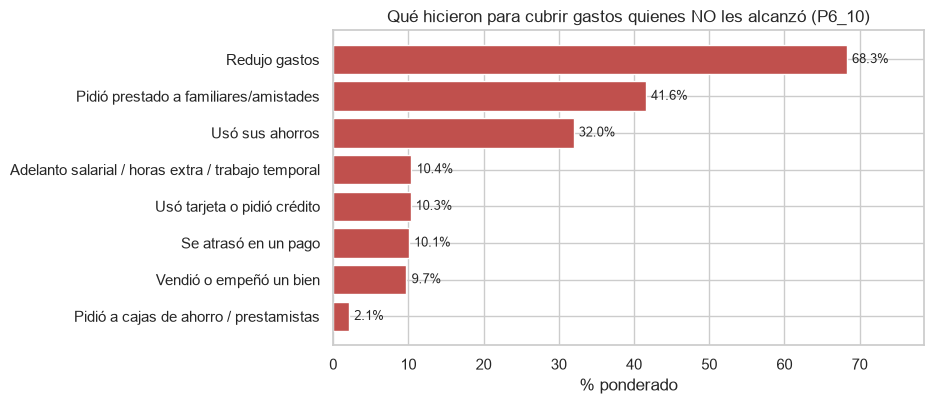

In [22]:
print(f"El ingreso del último mes SÍ alcanzó sin endeudarse: {pct_ponderado(m['P6_9'], m[w])[1]:.1f}%")
no = m["P6_9"] == 2
est = bloque(m, [f"P6_10_{i}" for i in range(1, 9)],
             ["Pidió prestado a familiares/amistades", "Usó sus ahorros", "Redujo gastos", "Vendió o empeñó un bien", "Adelanto salarial / horas extra / trabajo temporal",
              "Usó tarjeta o pidió crédito", "Se atrasó en un pago", "Pidió a cajas de ahorro / prestamistas"], w, universo=no)
bloque_barras(est, "Qué hicieron para cubrir gastos quienes NO les alcanzó (P6_10)", "19_estrategias_no_alcanzo.png", color=ROJO, figsize=(9.5, 4.2))

## 7. Comportamiento, bienestar y estrés financiero

### 7.1 Control del dinero y capacidad de reacción ante imprevistos

Lleva registro de ingresos y gastos (P7_1): 21.7%


,reactivo,% sí,n válido,% no sabe
0,Separa dinero de pagos/deudas del gasto diario,45.00,20448,0.00
1,Registra recibos o deudas pendientes,28.70,20448,0.00
2,Anota los gastos,24.80,20448,0.00
3,Usa app o herramienta digital,8.50,20448,0.00


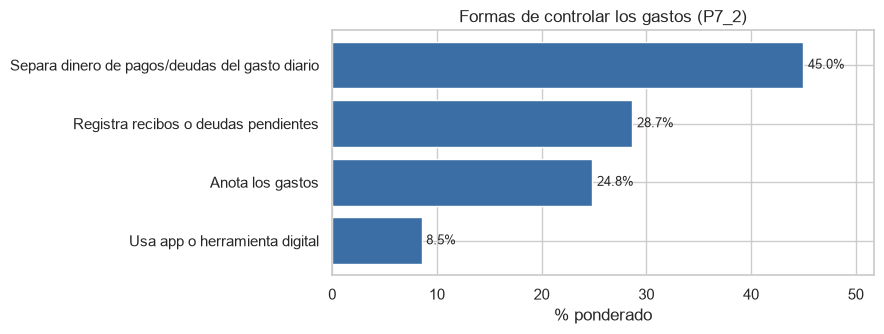

,reactivo,% sí,n válido,% no sabe
0,Préstamo de familiares/amistades,63.20,20448,0.00
1,Venta o empeño de un bien,40.60,20448,0.00
2,Trabajo temporal / venta de productos,38.50,20448,0.00
3,Sus ahorros,35.90,20448,0.00
4,Adelanto de sueldo,30.10,20448,0.00
5,Tarjeta o crédito financiero,18.70,20448,0.00
6,Agiotistas o prestamistas,10.40,20448,0.00


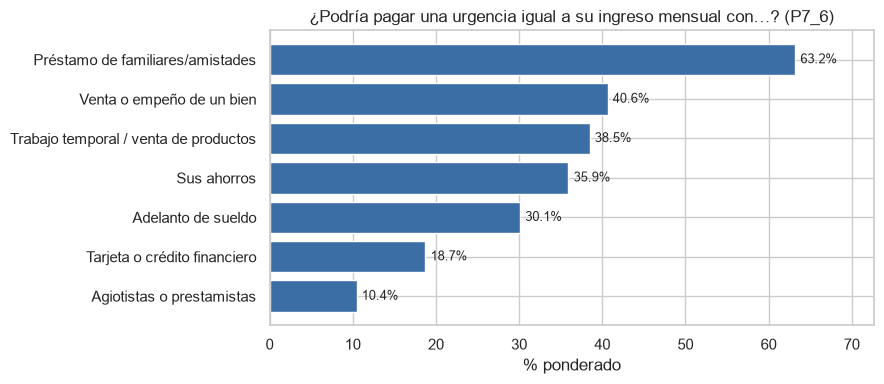

In [23]:
print(f"Lleva registro de ingresos y gastos (P7_1): {pct_ponderado(m['P7_1'], m[w])[1]:.1f}%")
ctrl = bloque(m, [f"P7_2_{i}" for i in range(1, 5)], ["Anota los gastos", "Separa dinero de pagos/deudas del gasto diario", "Registra recibos o deudas pendientes",
                                                       "Usa app o herramienta digital"], w)
bloque_barras(ctrl, "Formas de controlar los gastos (P7_2)", "20_control_gastos.png", figsize=(9, 3.5))

urg = bloque(m, [f"P7_6_{i}" for i in range(1, 8)],
             ["Sus ahorros", "Adelanto de sueldo", "Venta o empeño de un bien", "Préstamo de familiares/amistades", "Tarjeta o crédito financiero",
              "Trabajo temporal / venta de productos", "Agiotistas o prestamistas"], w)
bloque_barras(urg, "¿Podría pagar una urgencia igual a su ingreso mensual con…? (P7_6)", "21_urgencia.png", figsize=(9, 4))

### 7.2 Frecuencia de conductas financieras (P7_7) y autopercepción (P7_8)
Escalas Likert de 5 puntos. En P7_7, los reactivos 5 y 6 están redactados en **negativo**; se grafican tal cual (sin invertir).

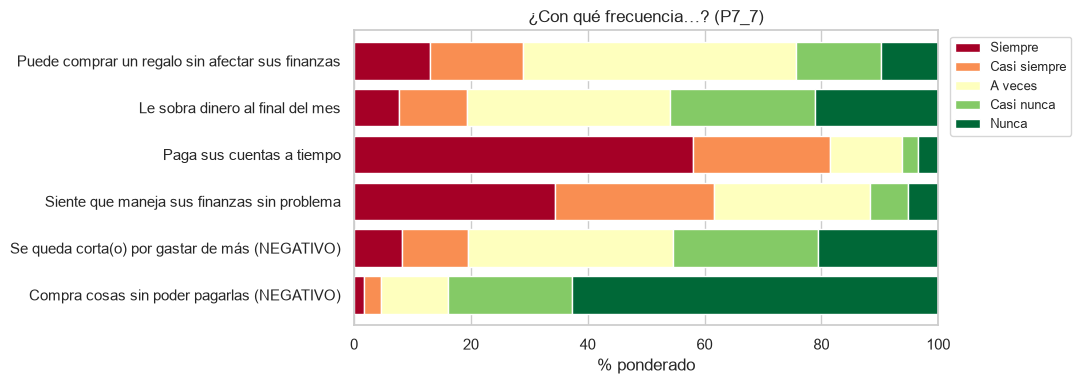

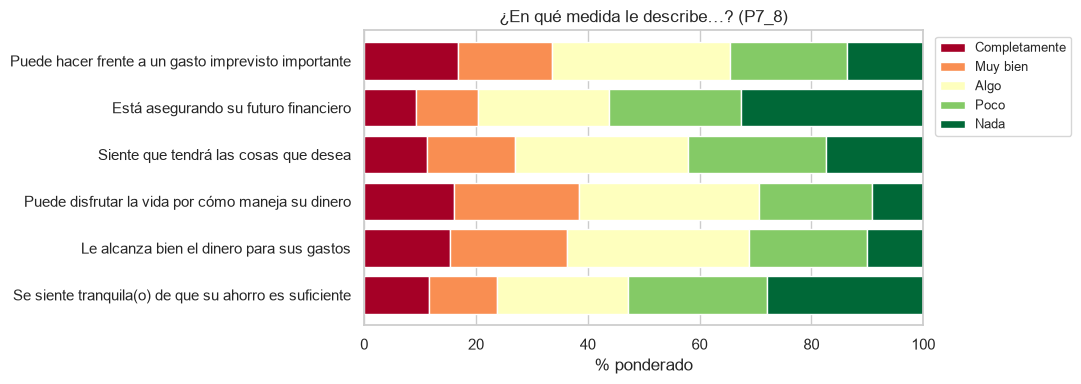

,Siempre,Casi siempre,A veces,Casi nunca,Nunca
Puede comprar un regalo sin afectar sus finanzas,12.90,16.00,46.70,14.50,9.80
Le sobra dinero al final del mes,7.70,11.70,34.70,24.90,21.00
Paga sus cuentas a tiempo,58.00,23.40,12.40,2.80,3.40
Siente que maneja sus finanzas sin problema,34.40,27.10,26.70,6.60,5.10
Se queda corta(o) por gastar de más (NEGATIVO),8.30,11.30,35.00,25.00,20.50
Compra cosas sin poder pagarlas (NEGATIVO),1.70,2.90,11.40,21.30,62.70


In [24]:
etq77 = ["Puede comprar un regalo sin afectar sus finanzas", "Le sobra dinero al final del mes", "Paga sus cuentas a tiempo",
         "Siente que maneja sus finanzas sin problema", "Se queda corta(o) por gastar de más (NEGATIVO)", "Compra cosas sin poder pagarlas (NEGATIVO)"]
etq78 = ["Puede hacer frente a un gasto imprevisto importante", "Está asegurando su futuro financiero", "Siente que tendrá las cosas que desea",
         "Puede disfrutar la vida por cómo maneja su dinero", "Le alcanza bien el dinero para sus gastos", "Se siente tranquila(o) de que su ahorro es suficiente"]


def likert(df, cols, etq, w, escala, titulo, archivo, cmap="RdYlGn"):
    d = pd.DataFrame({e: pct_ponderado(df[c], df[w]) for c, e in zip(cols, etq)}).T.reindex(columns=list(escala.keys())).fillna(0)
    d.columns = list(escala.values())
    ax = d.plot(kind="barh", stacked=True, figsize=(11, 4), colormap=cmap, width=0.8)
    ax.invert_yaxis()
    ax.set(xlabel="% ponderado", title=titulo, xlim=(0, 100))
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
    plt.tight_layout()
    ax.figure.savefig(SALIDAS / archivo, dpi=130, bbox_inches="tight")
    plt.show()
    return d


d77 = likert(m, [f"P7_7_{i}" for i in range(1, 7)], etq77, w, {1: "Siempre", 2: "Casi siempre", 3: "A veces", 4: "Casi nunca", 5: "Nunca"},
             "¿Con qué frecuencia…? (P7_7)", "22_p7_7.png")
d78 = likert(m, [f"P7_8_{i}" for i in range(1, 7)], etq78, w, {1: "Completamente", 2: "Muy bien", 3: "Algo", 4: "Poco", 5: "Nada"},
             "¿En qué medida le describe…? (P7_8)", "23_p7_8.png")
display(d77.round(1))

### 7.3 Estrés financiero: preocupación, emociones y consecuencias
`P8_4`: escala 0-10 de preocupación. `NIV_ESTRES` (derivada por INEGI, 1 = mayor estrés ... 3 = menor) lo confirma abajo.

Preocupación media por NIV_ESTRES (valida la dirección de la variable):


,mean,count
NIV_ESTRES,,
1 (más estrés),6.20,7304
2,4.98,6914
3 (menos estrés),2.90,6230


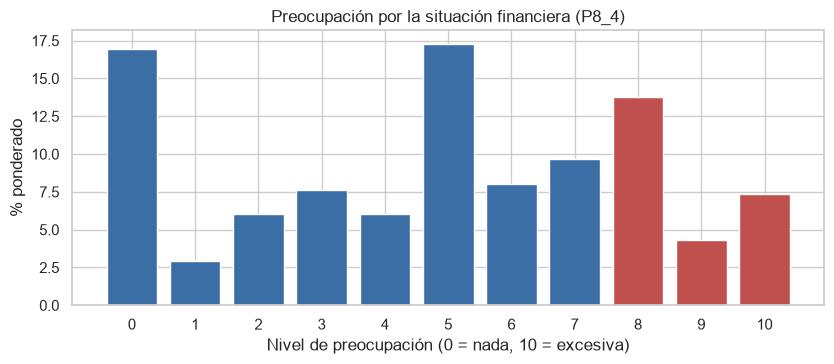

Media ponderada: 4.86 | alta (≥8): 25.4% | nula (0): 17.0%


In [25]:
print("Preocupación media por NIV_ESTRES (valida la dirección de la variable):")
display(m.groupby("NIV_ESTRES")["P8_4"].agg(["mean", "count"]).rename(index={1: "1 (más estrés)", 2: "2", 3: "3 (menos estrés)"}).round(2))

prec = m["P8_4"].value_counts(normalize=False).sort_index()
pp = pct_ponderado(m["P8_4"], m[w])
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.bar(pp.index.astype(int), pp.values, color=[ROJO if i >= 8 else AZUL for i in pp.index])
ax.set(xticks=range(0, 11), xlabel="Nivel de preocupación (0 = nada, 10 = excesiva)", ylabel="% ponderado",
       title="Preocupación por la situación financiera (P8_4)")
plt.tight_layout()
fig.savefig(SALIDAS / "24_preocupacion.png", dpi=130, bbox_inches="tight")
plt.show()
print(f"Media ponderada: {media_pond(m['P8_4'].astype(float), m[w]):.2f} | alta (≥8): {pp[pp.index >= 8].sum():.1f}% | nula (0): {pp[0]:.1f}%")

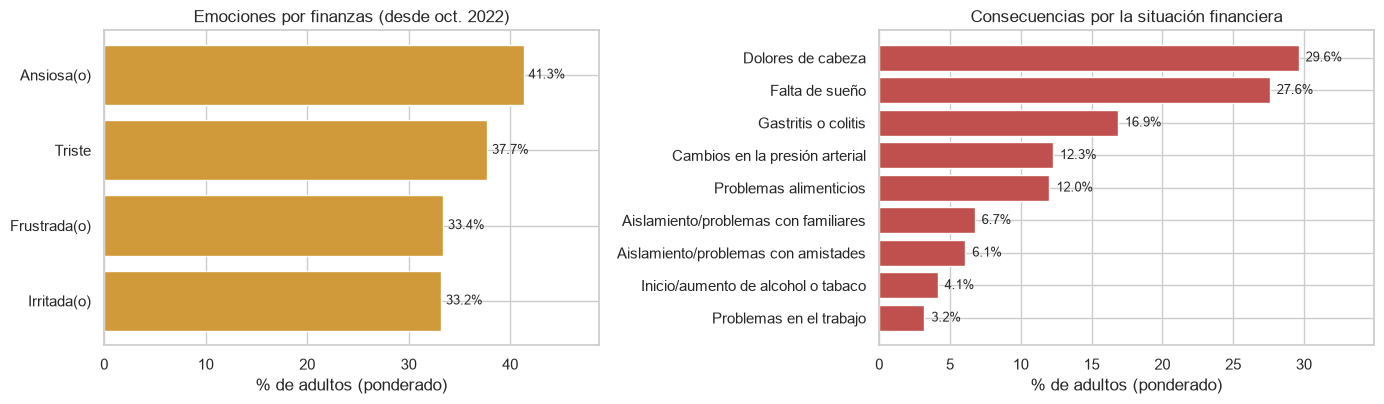

In [26]:
emo = bloque(m, [f"P8_2_{i}" for i in range(1, 5)], ["Ansiosa(o)", "Triste", "Irritada(o)", "Frustrada(o)"], w)
con_ = bloque(m, [f"P8_3_{i:02d}" for i in range(1, 10)],
              ["Dolores de cabeza", "Gastritis o colitis", "Cambios en la presión arterial", "Falta de sueño", "Problemas alimenticios",
               "Inicio/aumento de alcohol o tabaco", "Aislamiento/problemas con amistades", "Aislamiento/problemas con familiares", "Problemas en el trabajo"], w)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, d, tit, c in [(axes[0], emo, "Emociones por finanzas (desde oct. 2022)", "#d09a3a"), (axes[1], con_, "Consecuencias por la situación financiera", ROJO)]:
    ax.barh(d["reactivo"], d["% sí"], color=c)
    ax.invert_yaxis()
    for i, v in enumerate(d["% sí"]):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.set(title=tit, xlabel="% de adultos (ponderado)", xlim=(0, d["% sí"].max() * 1.18))
plt.tight_layout()
fig.savefig(SALIDAS / "25_emociones_consecuencias.png", dpi=130, bbox_inches="tight")
plt.show()

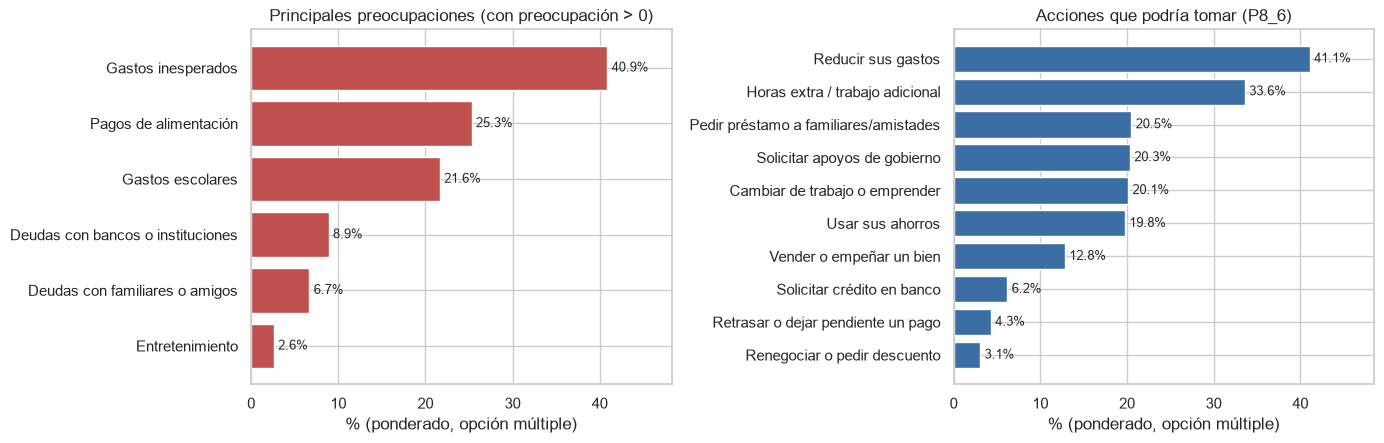

Universo P8_5: 16,572 personas con preocupación > 0 | universo P8_6: 14,004
Nota: 'P8_5_9' no tiene etiqueta en el cuestionario consultado y no se grafica; 'P8_5_7/8' (otra / sin preocupación) tampoco.


In [27]:
# Preocupaciones principales (8.5) y acciones posibles (8.6): opción múltiple 1/0; universo = quienes tienen preocupación > 0
pre = m["P8_4"] > 0
prin = bloque(m, ["P8_5_1", "P8_5_2", "P8_5_3", "P8_5_4", "P8_5_5", "P8_5_6"],
              ["Deudas con familiares o amigos", "Deudas con bancos o instituciones", "Gastos inesperados", "Gastos escolares", "Pagos de alimentación", "Entretenimiento"],
              w, si=1, validos=(0, 1), universo=pre)
acc = bloque(m, [f"P8_6_{i:02d}" for i in range(1, 11)],
             ["Pedir préstamo a familiares/amistades", "Solicitar crédito en banco", "Retrasar o dejar pendiente un pago", "Solicitar apoyos de gobierno",
              "Renegociar o pedir descuento", "Vender o empeñar un bien", "Usar sus ahorros", "Horas extra / trabajo adicional", "Cambiar de trabajo o emprender",
              "Reducir sus gastos"], w, si=1, validos=(0, 1), universo=m["P8_6_01"].notna())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, d, tit, c in [(axes[0], prin, "Principales preocupaciones (con preocupación > 0)", ROJO), (axes[1], acc, "Acciones que podría tomar (P8_6)", AZUL)]:
    ax.barh(d["reactivo"], d["% sí"], color=c)
    ax.invert_yaxis()
    for i, v in enumerate(d["% sí"]):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.set(title=tit, xlabel="% (ponderado, opción múltiple)", xlim=(0, d["% sí"].max() * 1.18))
plt.tight_layout()
fig.savefig(SALIDAS / "26_preocupaciones_acciones.png", dpi=130, bbox_inches="tight")
plt.show()
print(f"Universo P8_5: {int(pre.sum()):,} personas con preocupación > 0 | universo P8_6: {int(m['P8_6_01'].notna().sum()):,}")
print("Nota: 'P8_5_9' no tiene etiqueta en el cuestionario consultado y no se grafica; 'P8_5_7/8' (otra / sin preocupación) tampoco.")

### 7.4 Rasgos conductuales (P7_10)
Escala 1 = Mucho … 4 = Nada de acuerdo. Reactivos agrupados por rasgo: control, orientación al futuro, impulsividad, orientación a la acción y optimismo.

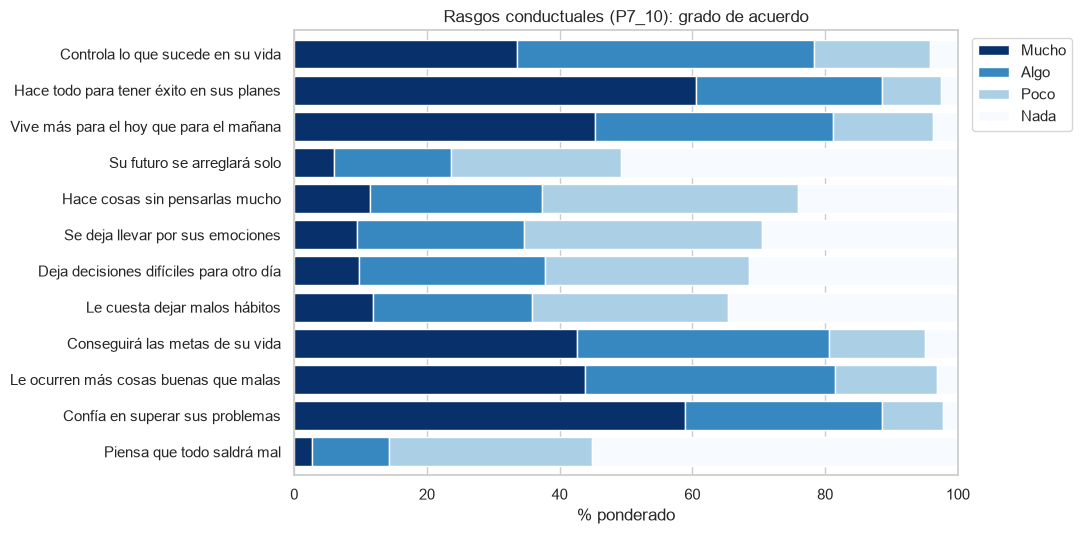

In [28]:
rasgos = {"Control": ["01", "02"], "Orient. al futuro": ["03", "04"], "Impulsividad": ["05", "06"], "Orient. a la acción": ["07", "08"], "Optimismo": ["09", "10", "11", "12"]}
etq710 = {"01": "Controla lo que sucede en su vida", "02": "Hace todo para tener éxito en sus planes", "03": "Vive más para el hoy que para el mañana",
          "04": "Su futuro se arreglará solo", "05": "Hace cosas sin pensarlas mucho", "06": "Se deja llevar por sus emociones",
          "07": "Deja decisiones difíciles para otro día", "08": "Le cuesta dejar malos hábitos", "09": "Conseguirá las metas de su vida",
          "10": "Le ocurren más cosas buenas que malas", "11": "Confía en superar sus problemas", "12": "Piensa que todo saldrá mal"}
d710 = {etq710[k]: pct_ponderado(m[f"P7_10_{k}"], m[w]) for ks in rasgos.values() for k in ks}
d710 = pd.DataFrame(d710).T.reindex(columns=[1, 2, 3, 4]).fillna(0)
d710.columns = ["Mucho", "Algo", "Poco", "Nada"]
ax = d710.plot(kind="barh", stacked=True, figsize=(11, 5.5), colormap="Blues_r", width=0.8)
ax.invert_yaxis()
ax.set(xlabel="% ponderado", title="Rasgos conductuales (P7_10): grado de acuerdo", xlim=(0, 100))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
ax.figure.savefig(SALIDAS / "27_rasgos.png", dpi=130, bbox_inches="tight")
plt.show()

## 8. Metas, vejez y CONDUSEF

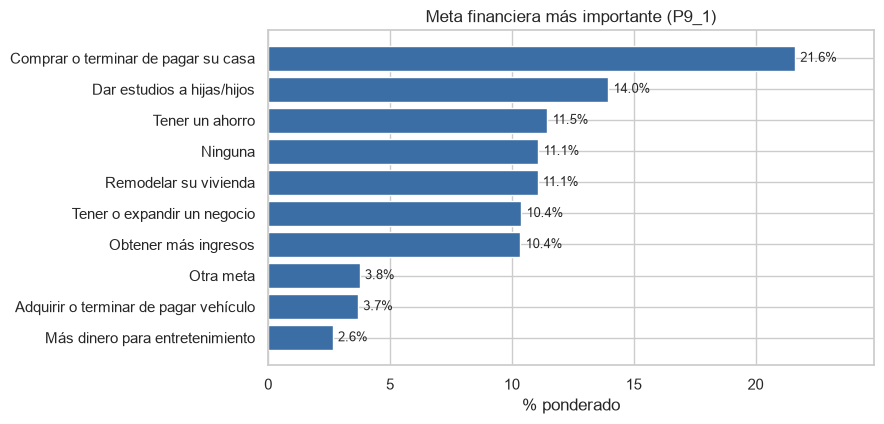

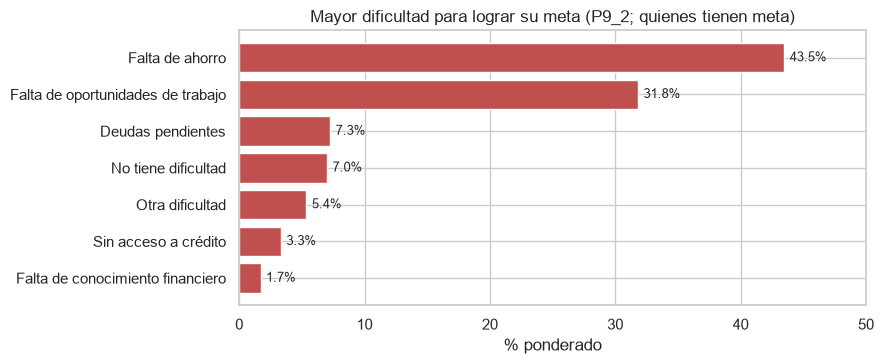

,reactivo,% sí,n válido,% no sabe
0,Apoyos del gobierno para adultos mayores,65.20,20448,0.00
1,Seguir trabajando,64.20,20448,0.00
2,"Pensión, jubilación, Afore o plan privado",47.40,20448,0.00
3,"Dinero de pareja, hijos u otros familiares",43.00,20448,0.00
4,Vender o rentar bienes,24.80,20448,0.00
5,Inversiones en bancos o instituciones,11.20,20448,0.00


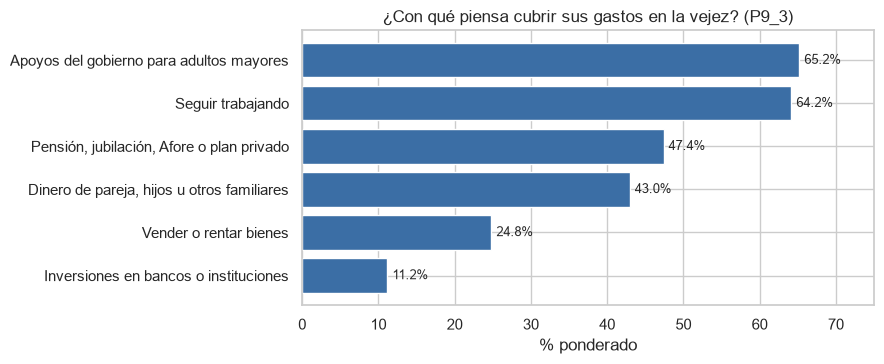

In [29]:
metas = {1: "Comprar o terminar de pagar su casa", 2: "Remodelar su vivienda", 3: "Dar estudios a hijas/hijos", 4: "Más dinero para entretenimiento",
         5: "Adquirir o terminar de pagar vehículo", 6: "Obtener más ingresos", 7: "Tener o expandir un negocio", 8: "Tener un ahorro", 9: "Otra meta", 10: "Ninguna"}
barras(pct_ponderado(m["P9_1"], m[w], metas).sort_values(ascending=False), "Meta financiera más importante (P9_1)", archivo="28_metas.png", figsize=(9, 4.4))

dif = {1: "Falta de ahorro", 2: "Deudas pendientes", 3: "Falta de oportunidades de trabajo", 4: "Falta de conocimiento financiero", 5: "Sin acceso a crédito",
       6: "Otra dificultad", 7: "No tiene dificultad"}
barras(pct_ponderado(m["P9_2"], m[w], dif).sort_values(ascending=False), "Mayor dificultad para lograr su meta (P9_2; quienes tienen meta)",
       archivo="29_dificultad_meta.png", color=ROJO, figsize=(9, 3.8))

vej = bloque(m, [f"P9_3_{i}" for i in range(1, 7)],
             ["Apoyos del gobierno para adultos mayores", "Pensión, jubilación, Afore o plan privado", "Vender o rentar bienes", "Dinero de pareja, hijos u otros familiares",
              "Seguir trabajando", "Inversiones en bancos o instituciones"], w)
bloque_barras(vej, "¿Con qué piensa cubrir sus gastos en la vejez? (P9_3)", "30_vejez.png", figsize=(9, 3.8))

Ha oído hablar de CONDUSEF (P10_1): 27.2%
Entre quienes la conocen, identifican su función principal (P10_2): 53.0%
Entre quienes la conocen, saben que imparte cursos gratuitos (P10_3): 21.0%


,reactivo,% sí,n válido,% no sabe
0,Importancia del ahorro,58.00,20448,0.00
1,Registro de ingresos y gastos,53.70,20448,0.00
2,Finanzas personales,53.40,20448,0.00
3,Gastos 'hormiga',50.30,20448,0.00
4,Manejo responsable de créditos,48.70,20448,0.00


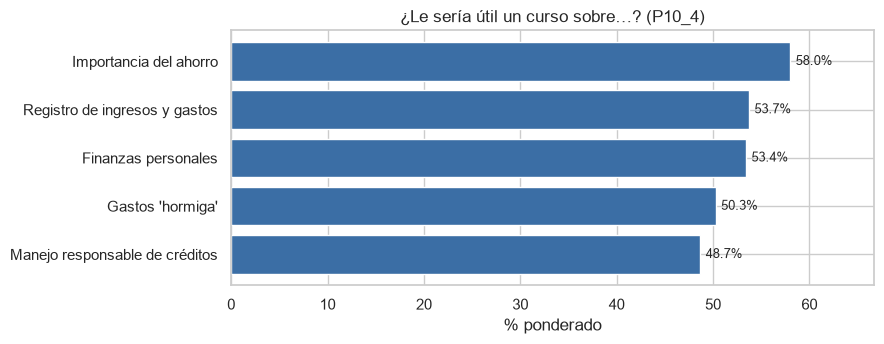

In [30]:
print(f"Ha oído hablar de CONDUSEF (P10_1): {pct_ponderado(m['P10_1'], m[w])[1]:.1f}%")
con = m["P10_1"] == 1
print(f"Entre quienes la conocen, identifican su función principal (P10_2): {pct_ponderado(m.loc[con, 'P10_2'], m.loc[con, w])[1]:.1f}%")
print(f"Entre quienes la conocen, saben que imparte cursos gratuitos (P10_3): {pct_ponderado(m.loc[con, 'P10_3'], m.loc[con, w])[1]:.1f}%")
temas = bloque(m, [f"P10_4_{i}" for i in range(1, 6)],
               ["Registro de ingresos y gastos", "Manejo responsable de créditos", "Gastos 'hormiga'", "Importancia del ahorro", "Finanzas personales"], w)
bloque_barras(temas, "¿Le sería útil un curso sobre…? (P10_4)", "31_temas_interes.png", figsize=(9, 3.6))

## 9. Geografía y segmentos
`ENT` = entidad federativa (clave INEGI 1-32). `TLOC` y `REGION` son códigos 1-4; sus etiquetas oficiales no se verificaron en el diccionario de datos, por lo que se muestran como códigos (no se les asigna significado).

Tamaño de muestra por entidad (TMODULO): mínimo 606 (Quintana Roo), máximo 676 (Nayarit)


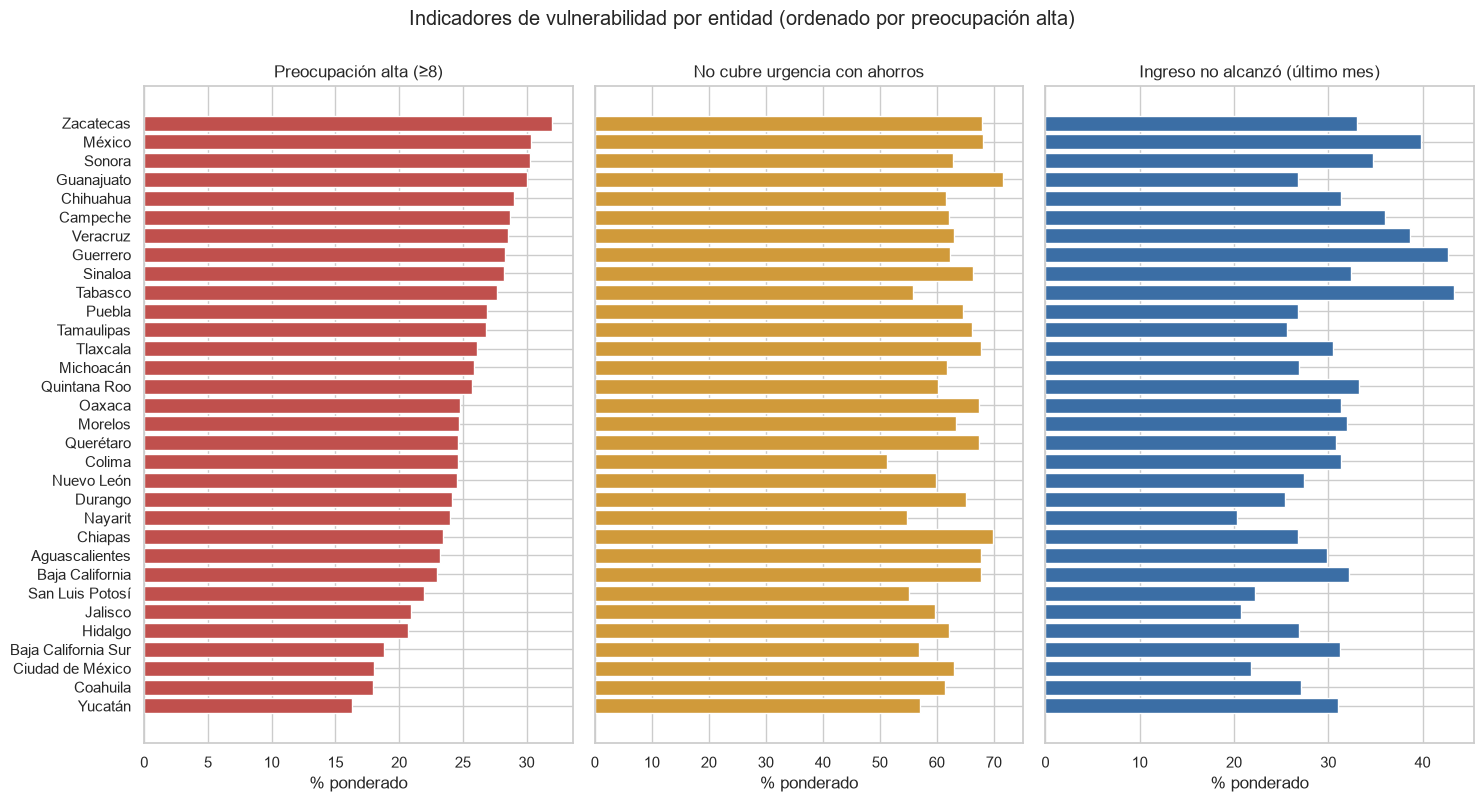

Precaución: con ~600 casos por entidad, las diferencias pequeñas entre estados están dentro del error muestral.


In [31]:
ents = {1: "Aguascalientes", 2: "Baja California", 3: "Baja California Sur", 4: "Campeche", 5: "Coahuila", 6: "Colima", 7: "Chiapas", 8: "Chihuahua",
        9: "Ciudad de México", 10: "Durango", 11: "Guanajuato", 12: "Guerrero", 13: "Hidalgo", 14: "Jalisco", 15: "México", 16: "Michoacán", 17: "Morelos",
        18: "Nayarit", 19: "Nuevo León", 20: "Oaxaca", 21: "Puebla", 22: "Querétaro", 23: "Quintana Roo", 24: "San Luis Potosí", 25: "Sinaloa", 26: "Sonora",
        27: "Tabasco", 28: "Tamaulipas", 29: "Tlaxcala", 30: "Veracruz", 31: "Yucatán", 32: "Zacatecas"}
n_ent = m["ENT"].value_counts()
print(f"Tamaño de muestra por entidad (TMODULO): mínimo {n_ent.min()} ({ents[n_ent.idxmin()]}), máximo {n_ent.max()} ({ents[n_ent.idxmax()]})")

# Indicadores clave por persona elegida (todos con su universo correcto)
m["tiene_ahorro_algun"] = m["P6_3"].map({1: 1.0, 2: 0.0})
m["tiene_deuda"] = (m["FILTRO_S6_2"] == 1).astype(float)
m["atraso_deuda"] = m["P6_7"].map({1: 1.0, 2: 0.0})                  # solo quienes tienen deuda
m["ingreso_no_alcanzo"] = m["P6_9"].map({1: 0.0, 2: 1.0})
m["sin_colchon"] = m["P7_6_1"].map({1: 0.0, 2: 1.0})                  # no podría pagar una urgencia con ahorros
m["preocup_alta"] = (m["P8_4"] >= 8).astype(float)
m["lleva_registro"] = m["P7_1"].map({1: 1.0, 2: 0.0})
INDS = {"ingreso_no_alcanzo": "Ingreso no alcanzó\n(último mes)", "sin_colchon": "No cubre urgencia\ncon ahorros", "preocup_alta": "Preocupación\nalta (≥8)",
        "tiene_deuda": "Tiene alguna\ndeuda", "atraso_deuda": "Atraso en pagos\n(entre deudores)", "tiene_ahorro_algun": "Tiene algún\nahorro",
        "lleva_registro": "Lleva registro\ningresos/gastos"}


def tabla_seg(df, por, orden=None):
    filas = {}
    for k, g in df.groupby(por, observed=True):
        filas[k] = {lab: media_pond(g[c], g[w]) * 100 for c, lab in INDS.items()}
    t_ = pd.DataFrame(filas).T
    return t_.reindex(orden) if orden else t_


ent_ind = tabla_seg(m, "ENT")
ent_ind.index = [ents[i] for i in ent_ind.index]
orden = ent_ind["Preocupación\nalta (≥8)"].sort_values(ascending=False).index
fig, axes = plt.subplots(1, 3, figsize=(15, 8), sharey=True)
for ax, col, c in zip(axes, ["Preocupación\nalta (≥8)", "No cubre urgencia\ncon ahorros", "Ingreso no alcanzó\n(último mes)"], [ROJO, "#d09a3a", AZUL]):
    ax.barh(orden, ent_ind.loc[orden, col], color=c)
    ax.set(title=col.replace("\n", " "), xlabel="% ponderado")
axes[0].invert_yaxis()
plt.suptitle("Indicadores de vulnerabilidad por entidad (ordenado por preocupación alta)", y=1.0)
plt.tight_layout()
fig.savefig(SALIDAS / "32_entidades.png", dpi=130, bbox_inches="tight")
plt.show()
print("Precaución: con ~600 casos por entidad, las diferencias pequeñas entre estados están dentro del error muestral.")

,Ingreso no alcanzó (último mes),No cubre urgencia con ahorros,Preocupación alta (≥8),Tiene alguna deuda,Atraso en pagos (entre deudores),Tiene algún ahorro,Lleva registro ingresos/gastos
Sexo: Hombre,28.00,60.00,20.70,44.70,25.00,46.40,22.10
Sexo: Mujer,32.50,67.50,29.20,39.50,22.70,38.90,21.50
Edad: 18-24,24.50,59.10,19.20,34.40,27.20,47.50,22.30
Edad: 25-34,28.80,56.10,24.10,49.50,23.40,51.40,28.50
Edad: 35-44,33.70,63.70,28.20,48.50,25.80,46.10,24.40
Edad: 45-54,34.40,69.00,30.30,47.90,24.20,46.10,22.70
Edad: 55-64,31.30,69.20,26.90,38.30,23.50,46.50,17.70
Edad: 65+,29.10,69.50,21.90,26.20,14.70,23.00,11.00
"Ingreso del hogar: Hasta $6,100",35.80,71.90,28.70,31.40,28.40,31.00,14.00
"Ingreso del hogar: $6,101-9,900",30.70,66.30,26.60,38.00,26.60,35.20,19.00


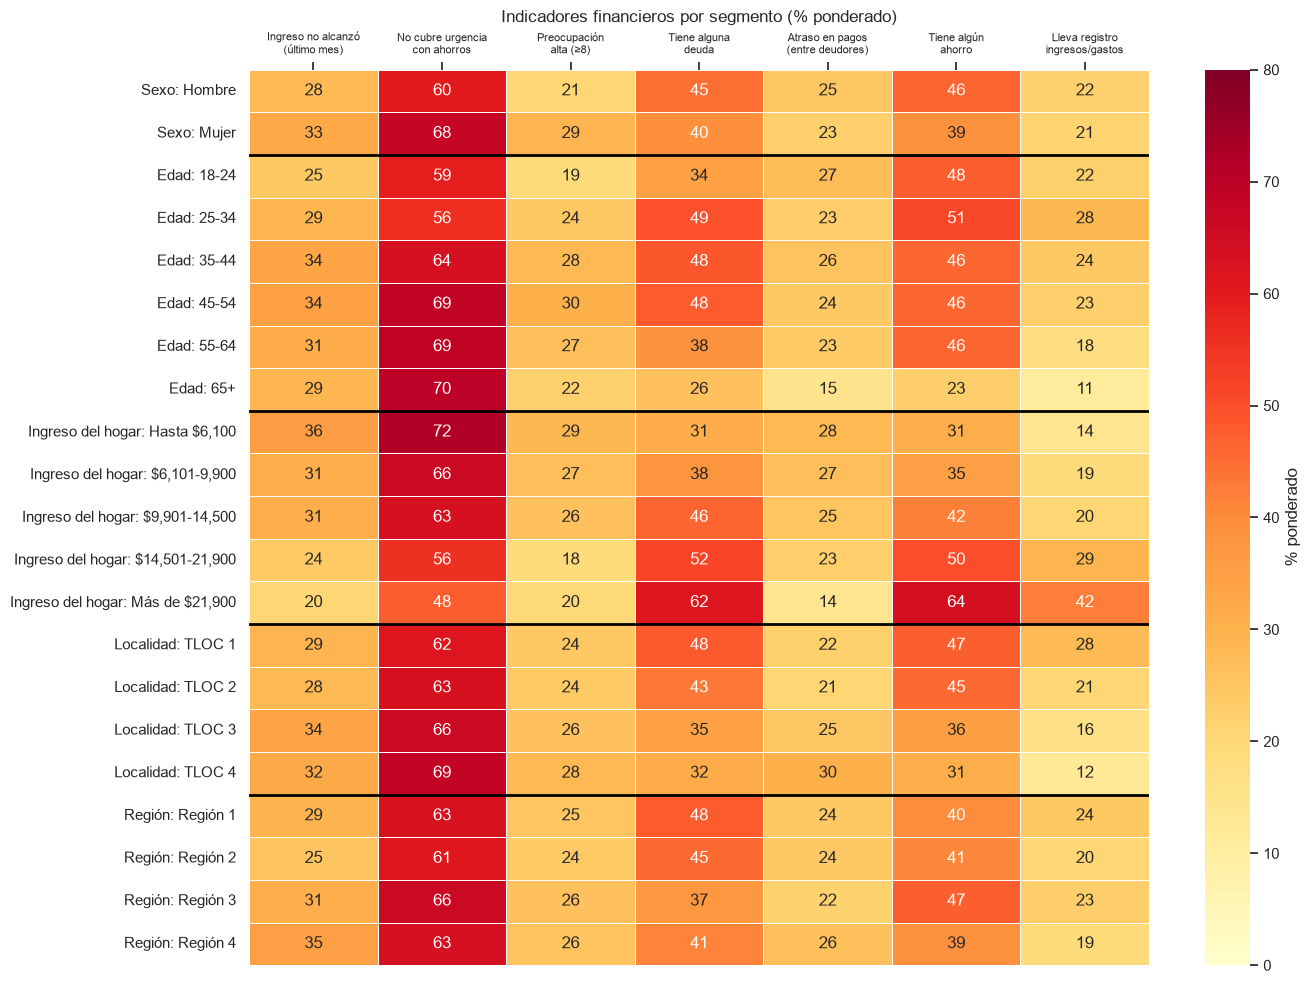

In [32]:
m["gedad"] = pd.cut(m["EDAD_V"].where(m["EDAD_V"] < 98), [18, 25, 35, 45, 55, 65, 200], right=False, labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"])
m["sexo_l"] = m["SEXO"].map({1: "Hombre", 2: "Mujer"})
m = m.merge(df_thogar[["LLAVEHOG", "P4_3"]].rename(columns={"P4_3": "rango_hogar"}), on="LLAVEHOG", how="left", validate="one_to_one")
m["ing_hogar_g"] = pd.cut(m["rango_hogar"], [0, 2, 4, 6, 8, 11], labels=["Hasta $6,100", "$6,101-9,900", "$9,901-14,500", "$14,501-21,900", "Más de $21,900"])
m["TLOC_l"] = "TLOC " + m["TLOC"].astype(str)
m["REGION_l"] = "Región " + m["REGION"].astype(str)

segs = [("sexo_l", "Sexo"), ("gedad", "Edad"), ("ing_hogar_g", "Ingreso del hogar"), ("TLOC_l", "Localidad"), ("REGION_l", "Región")]
partes = []
for col, tit in segs:
    t_ = tabla_seg(m, col)
    t_.index = [f"{tit}: {i}" for i in t_.index]
    partes.append(t_)
seg_tab = pd.concat(partes)
display(seg_tab.rename(columns=lambda c: c.replace("\n", " ")).round(1))

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(seg_tab, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "% ponderado"}, ax=ax, linewidths=0.5, vmin=0, vmax=80)
corte = 0
for p in partes[:-1]:
    corte += len(p)
    ax.axhline(corte, color="black", lw=2)
ax.xaxis.tick_top()
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=8)
ax.set(title="Indicadores financieros por segmento (% ponderado)", ylabel="")
plt.tight_layout()
fig.savefig(SALIDAS / "33_segmentos.png", dpi=130, bbox_inches="tight")
plt.show()

### 9.1 Relaciones simples entre variables (sin ponderar, solo exploratorio)

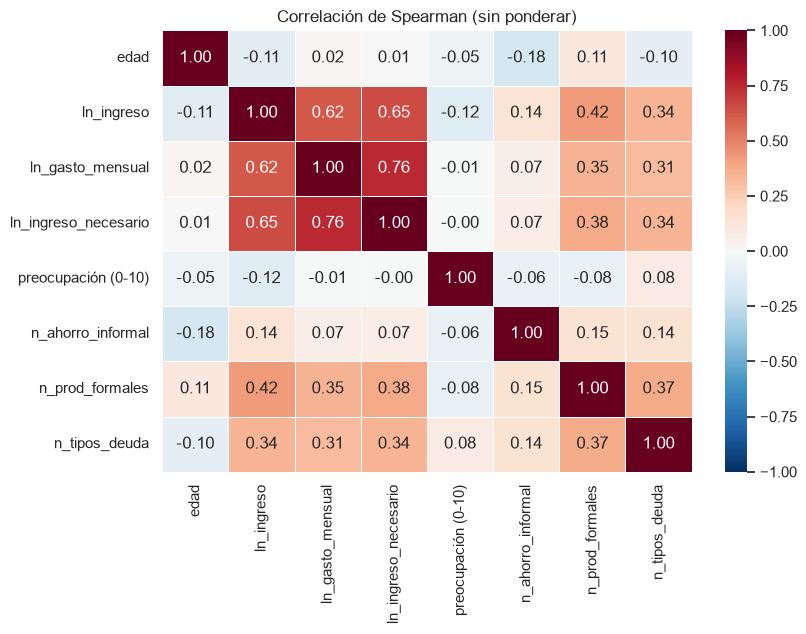

Spearman es robusto a los montos extremos. Las correlaciones con ingreso usan solo a quienes lo reportan.


In [33]:
cor = m[["EDAD_V", "INGRESO_M", "P8_4", "P6_12", "P6_13", "P5_21", "P5_22"]].copy()
cor["ln_ingreso"] = np.log1p(cor["INGRESO_M"])
for c, bad in [("P6_12", 99999888), ("P6_13", 999888), ("P5_21", 99999), ("P5_22", 999888)]:
    cor[c] = cor[c].where(cor[c] < bad)
cor["ln_gasto_mensual"] = np.log1p(cor["P5_21"])
cor["ln_ingreso_necesario"] = np.log1p(cor["P5_22"])
cor["n_ahorro_informal"] = (m[[f"P6_1_{i}" for i in range(1, 7)]] == 1).sum(axis=1)
cor["n_prod_formales"] = (m[[f"P6_2_{i:02d}" for i in range(1, 11)]] == 1).sum(axis=1)
cor["n_tipos_deuda"] = (m[[f"P6_5_{i}" for i in range(1, 5)] + [f"P6_6_{i}" for i in range(1, 9)]] == 1).sum(axis=1)
cor = cor.rename(columns={"EDAD_V": "edad", "P8_4": "preocupación (0-10)"})
cols = ["edad", "ln_ingreso", "ln_gasto_mensual", "ln_ingreso_necesario", "preocupación (0-10)", "n_ahorro_informal", "n_prod_formales", "n_tipos_deuda"]
corr = cor[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, linewidths=0.5)
ax.set(title="Correlación de Spearman (sin ponderar)")
plt.tight_layout()
fig.savefig(SALIDAS / "34_correlaciones.png", dpi=130, bbox_inches="tight")
plt.show()
print("Spearman es robusto a los montos extremos. Las correlaciones con ingreso usan solo a quienes lo reportan.")

In [34]:
# Cifras clave (se recalculan con los datos cargados)
ahorro_form = (m[["P6_2_04", "P6_2_05", "P6_2_06", "P6_2_07", "P6_2_08"]] == 1).any(axis=1).astype(float)
afore = (m["P6_2_10"] == 1).astype(float)
clave = {
    "Hogares representados (millones)": df_thogar["FAC_HOG"].sum() / 1e6,
    "Adultos representados (millones)": m[w].sum() / 1e6,
    "Viviendas propias (%)": pct_ponderado(df_tvivienda["P1_5"], df_tvivienda["FAC_VIV"])[1],
    "Ingreso del mes SÍ alcanzó sin endeudarse (%)": pct_ponderado(m["P6_9"], m[w])[1],
    "Tiene alguna deuda (%)": media_pond(m["tiene_deuda"], m[w]) * 100,
    "No cubriría una urgencia con ahorros (%)": media_pond(m["sin_colchon"], m[w]) * 100,
    "Tiene instrumento formal de ahorro/inversión (%)": media_pond(ahorro_form, m[w]) * 100,
    "Tiene cuenta Afore (%)": media_pond(afore, m[w]) * 100,
    "Lleva registro de ingresos y gastos (%)": media_pond(m["lleva_registro"], m[w]) * 100,
    "Preocupación media (0-10)": media_pond(m["P8_4"].astype(float), m[w]),
    "Preocupación alta ≥ 8 (%)": media_pond(m["preocup_alta"], m[w]) * 100,
    "Conoce CONDUSEF (%)": pct_ponderado(m["P10_1"], m[w])[1],
}
display(pd.Series(clave, name="valor").to_frame().round(1))

,valor
Hogares representados (millones),38.70
Adultos representados (millones),92.80
Viviendas propias (%),67.20
Ingreso del mes SÍ alcanzó sin endeudarse (%),69.50
Tiene alguna deuda (%),41.90
No cubriría una urgencia con ahorros (%),64.10
Tiene instrumento formal de ahorro/inversión (%),20.60
Tiene cuenta Afore (%),17.30
Lleva registro de ingresos y gastos (%),21.70
Preocupación media (0-10),4.90


#Pregunta 1
## 1. Planteamiento y diseño del análisis

### 1.1 Pregunta de investigación

> **Entre las personas adultas en México que reportaron al menos un préstamo informal o la tenencia de un producto de crédito formal en 2023, ¿cómo varía la proporción de quienes reportaron atrasos en sus pagos según sus experiencias de socialización financiera, su percepción del nivel de endeudamiento, la confianza en sus habilidades financieras y su escolaridad?**

*En este estudio, a esa proporción se le denomina **prevalencia de atrasos**: el porcentaje estimado de la población adulta elegible para responder la pregunta P6_7 que reportó haberse retrasado en el pago de al menos uno de los préstamos o productos de crédito considerados por el cuestionario.*

---

### 1.2 Objetivo del análisis

Se emplean los microdatos de la **Encuesta Nacional sobre Salud Financiera (ENSAFI 2023)** del INEGI ([documentación oficial](https://www.inegi.org.mx/programas/ensafi/2023/#documentacion)) para estimar la prevalencia de atrasos en los pagos entre las personas adultas que cumplen el filtro de elegibilidad establecido por las preguntas P6_5 y P6_6. Asimismo, se examinan las diferencias descriptivas de dicha prevalencia según cuatro dimensiones:

- **Socialización y aprendizaje financiero:** experiencias declaradas en P7_12 relacionadas con conversaciones familiares sobre el dinero y el ahorro, actividades escolares, administración de recursos y formación para registrar ingresos y gastos. El indicador resume respuestas afirmativas; no mide conocimientos financieros objetivos.
- **Percepción de endeudamiento:** valoración subjetiva que realiza la persona sobre la magnitud de su deuda total, desde *bajo* hasta *excesivo*.
- **Confianza financiera:** seguridad percibida para administrar el dinero, planificar el futuro financiero y tomar decisiones sobre productos de instituciones financieras, medida mediante los tres reactivos ordinales P7_9.
- **Escolaridad y consecuencias del estrés financiero:** perfil educativo de las personas del universo elegible para responder P6_7 y número de consecuencias prácticas que los informantes declararon haber enfrentado a causa de su situación financiera.

El análisis tiene un alcance descriptivo y busca identificar diferencias entre grupos, sin atribuir relaciones causales a los patrones observados.

---

### 1.3 Los datos y la unidad de estudio

La ENSAFI 2023 se organiza en cuatro tablas principales que describen desde la vivienda física hasta las respuestas individuales:

| Tabla | Registros | Columnas | ¿Qué contiene? | Llave de unión |
| :--- | :---: | :---: | :--- | :--- |
| **`TMODULO.csv`** | 20,448 | 253 | Entrevista individual sobre salud financiera (adultos de 18 años y más) | `UPM`, `VIV_SEL`, `HOGAR`, `N_REN` |
| **`TSDEM.csv`** | 67,781 | 25 | Datos sociodemográficos de todos los integrantes del hogar | `UPM`, `VIV_SEL`, `HOGAR`, `N_REN` |
| **`THOGAR.csv`** | 20,448 | 55 | Composición y características del hogar | `UPM`, `VIV_SEL`, `HOGAR` |
| **`TVIVIENDA.csv`** | 20,201 | 36 | Características físicas de la vivienda | `UPM`, `VIV_SEL` |

La unidad de análisis es la **persona adulta seleccionada en cada hogar**. Aunque la encuesta distingue entre vivienda física y hogar, el estudio trabaja exclusivamente con `TMODULO.csv` y `TSDEM.csv`, cruzándolas mediante la clave única de cada persona (`UPM`, `VIV_SEL`, `HOGAR`, `N_REN`).

---

### 1.4 Utilización de las variables

Para asegurar que cada indicador mida exactamente lo que representa, se mapean las preguntas del cuestionario oficial de la siguiente manera:

| Concepto en el análisis | Variables INEGI | Cómo se construye en el estudio |
| :--- | :--- | :--- |
| **Universo elegible para P6_7** | `P6_5_*`, `P6_6_*` | Identifica a quienes reportan al menos un préstamo informal o la tenencia de un producto de crédito formal (`credito_activo = 1`). No implica necesariamente que todos reconozcan un saldo pendiente. |
| **Atraso en los pagos** | `P6_7` | Indica si la persona reportó haberse atrasado en el pago de uno de esos préstamos o créditos (`atraso_credito`). Solo se analiza en el universo que cumple el filtro de P6_5/P6_6. |
| **Percepción de deuda** | `P6_8` | Escala ordenada de qué tan alto siente su endeudamiento (*Excesivo*, *Alto*, *Moderado*, *Bajo*). |
| **Socialización y aprendizaje financiero** | `P7_12_1`–`P7_12_6` | Cuenta respuestas afirmativas (de `0` a `6`) en experiencias de socialización y aprendizaje; solo se calcula con seis respuestas Sí/No completas. No es una prueba de conocimientos. |
| **Confianza financiera** | `P7_9_1`–`P7_9_3`, `CONF_FINAN` | Se resume mediante un promedio invertido de los tres reactivos ordinales (de `1.0` a `4.0`), utilizado como indicador exploratorio. También se conserva `CONF_FINAN` como clasificación oficial complementaria: código `1 = Muy característico` y código `2 = Poco característico`. Ambas medidas derivan de los mismos reactivos y no representan dimensiones independientes. |
| **Consecuencias del estrés** | `P8_3_01`–`P8_3_10` | Cuenta cuántos tipos de consecuencias reportó desde octubre de 2022 (`consecuencias_estres_n`). Cada reactivo recibe el mismo peso; el conteo no mide gravedad ni intensidad. |
| **Perfil sociodemográfico** | `NIV`, `EDAD` | Agrupa el nivel máximo de estudios alcanzado (`escolaridad_grupo`) y la edad en años cumplidos dentro del rango puntual `18–96` (`edad_exacta`), excluyendo la categoría abierta `97` (*97 años y más*) y los códigos no especificados (`98`, `99`). |
| **Variables excluidas o de referencia** | `P8_5_*` y `P6_13` | `P8_5_*` mide preocupaciones, no consecuencias; `P6_13` mide capacidad máxima declarada, no pago mensual efectivo. Por ello, no se usan como medida de carga financiera efectiva. |

La clasificación oficial `CONF_FINAN` se construye a partir de los tres reactivos P7_9: las respuestas *Mucho*, *Algo*, *Poco* y *Nada* reciben puntuaciones de 3, 2, 1 y 0, respectivamente. La suma de 5 a 9 corresponde a *Muy característico* (código 1), mientras que la suma de 0 a 4 corresponde a *Poco característico* (código 2). Esta clasificación se presenta como complemento del promedio invertido exploratorio. Véase el [Documento conceptual de la ENSAFI 2023, INEGI](https://www.inegi.org.mx/contenidos/productos/prod_serv/contenidos/espanol/bvinegi/productos/nueva_estruc/889463918196.pdf).

---

### 1.5 Estimación de la prevalencia

Para obtener estimaciones puntuales expandidas y no limitarse a la distribución de la muestra, cada respuesta válida se pondera utilizando el factor de expansión **`FAC_ELE`**. El denominador de cada proporción incluye únicamente los casos con respuesta válida en el indicador correspondiente:

$$
\hat{P}(Y = 1) =
\frac{\sum_{i \in s} w_i \, \mathbb{I}(Y_i = 1)}
{\sum_{i \in s} w_i \, \mathbb{I}(Y_i \text{ observado})},
\qquad
w_i = \text{FAC\_ELE}_i
$$

En los resultados se reporta el porcentaje poblacional estimado, el número de personas encuestadas (`n`) y la población expandida que representan (`Σ FAC_ELE`).

> **Alcance descriptivo:** Este proyecto describe diferencias observadas en 2023. No se estiman efectos causales ni se realizan pruebas de hipótesis. Las medidas de tendencia central de la Tabla 1 son no ponderadas (donde `edad_exacta` contempla únicamente edades puntuales en el rango `18–96`, con máximo observado de `95.0` en la muestra elegible, excluyendo los casos codificados como `97` *"97 años y más"* por ser categoría abierta); las proporciones comparativas se expanden con `FAC_ELE`. No se calculan errores estándar ni intervalos de confianza que incorporen el diseño muestral complejo (`EST_DIS`, `UPM_DIS`).

## 2. Integración, limpieza y construcción de indicadores

Antes de construir cualquier métrica, se verifica la unicidad de la llave primaria compuesta **`["UPM", "VIV_SEL", "HOGAR", "N_REN"]`** en ambas tablas y se ejecuta una unión izquierda estricta uno a uno (`validate="one_to_one"`). La comprobación confirma que los **$20,448$** registros de `TMODULO` encuentran correspondencia en `TSDEM` (`both = 20,448`, `left_only = 0`), sin duplicar ni perder registros de la tabla principal. Al tratarse de una unión izquierda, esta operación no contabiliza los registros adicionales de `TSDEM`, que contiene información de todos los integrantes de los hogares.

---

### 2.1 Decisiones metodológicas de limpieza y transformación

1. **Delimitación del universo elegible para P6_7 y no imputación de atrasos (`P6_5_*`, `P6_6_*`, `P6_7`)**
   - La pregunta sobre atraso en los pagos (`P6_7`) se aplica exclusivamente a quienes reportan al menos un préstamo informal (`P6_5_1`–`P6_5_5`) o la tenencia de al menos un producto de crédito formal (`P6_6_1`–`P6_6_9`) ($n = 9,049$). Los $11,399$ registros restantes no cumplen el filtro de elegibilidad para responder `P6_7` y se mantienen como `NaN` estructural en `atraso_credito`. Esta decisión evita mezclar en el denominador de la prevalencia a personas que no forman parte del universo al que se dirige la pregunta.
   - La clasificación reconstruida con `P6_5_*` y `P6_6_*` coincide exactamente con la variable de filtro oficial `FILTRO_S6_2`: se identifican $9,049$ casos elegibles y $11,399$ no elegibles, sin discrepancias. Los $9,049$ casos elegibles coinciden uno a uno con las respuestas válidas en `P6_7`.
   - En los microdatos revisados, los reactivos `P6_5_*` y `P6_6_*` presentan únicamente los códigos `1` y `2`, correspondientes a respuestas afirmativas y negativas. Por ello, la clasificación negativa se construye exclusivamente con el código `2`; no se interpreta el código `0` como respuesta negativa.

2. **Tratamiento de la socialización financiera (`P7_12_1`–`P7_12_6`)**
   - Se construye un conteo de respuestas afirmativas únicamente cuando los seis reactivos tienen respuestas definitivas Sí/No. Los registros con al menos un código `3` (*No recuerda*) no se convierten en respuestas negativas ni se incorporan al conteo completo.
   - En el total de `TMODULO` se identifican $19,585$ registros con información completa y $863$ con al menos una respuesta *No recuerda*. Dentro del universo elegible para P6_7, el indicador cuenta con $8,722$ observaciones completas.

3. **Percepción del endeudamiento (`P6_8`)**
   - Se conserva la escala ordinal de cuatro categorías: *Excesivo*, *Alto*, *Moderado* y *Bajo*. Las respuestas *No tiene deudas* y *No sabe* se presentan por separado, ya que no representan posiciones adicionales dentro de la escala ordinal.
   - Dentro del universo elegible para P6_7 se identifican $7,894$ respuestas ordinales válidas, además de $1,134$ respuestas *No tiene deudas* y $21$ respuestas *No sabe*.

4. **Construcción del indicador exploratorio de confianza financiera (`P7_9_1`–`P7_9_3`)**
   - Los tres reactivos ordinales se orientan en el mismo sentido mediante la transformación inversa `5 - respuesta`, de modo que los valores mayores representan respuestas más favorables. El promedio se calcula únicamente cuando los tres reactivos tienen respuesta válida.
   - El resultado se interpreta como un puntaje descriptivo exploratorio. No se afirma que constituya una escala psicométrica validada ni que las distancias entre categorías ordinales sean necesariamente equivalentes.
   - Adicionalmente, se conserva `CONF_FINAN`, clasificación oficial derivada de los mismos reactivos. Sus categorías son *Muy característico* (código `1`) y *Poco característico* (código `2`). Se utiliza como resumen complementario y no como una dimensión independiente del puntaje promedio.

5. **Consecuencias del estrés financiero (`P8_3_01`–`P8_3_10`)**
   - Se contabilizan los tipos de consecuencias reportadas por cada persona. El indicador toma valores entre `0` y `10`; cada reactivo tiene el mismo peso. Por tanto, el conteo representa amplitud de consecuencias declaradas y no su intensidad, gravedad o duración.
   - Se conserva el periodo de referencia del cuestionario, desde octubre de 2022 hasta la fecha de entrevista.

6. **Variables sociodemográficas (`NIV`, `EDAD`)**
   - La escolaridad se agrupa en tres categorías: *Básica o menor*, *Normal, técnica o media superior* y *Superior y posgrado*. Los códigos correspondientes a maestría y doctorado se incorporan en la última categoría.
   - En edad se distinguen las edades exactas de 18 a 96 años, la categoría abierta de 97 años y más y los códigos de edad desconocida. En los microdatos revisados aparecen 9 casos con código `97` y 18 casos con código `98`; no se observa el código `99`.

---

### 2.2 Alcance de los indicadores

Los indicadores construidos permiten comparar descriptivamente la prevalencia de atrasos entre grupos definidos por las respuestas de la encuesta. No obstante, cada uno representa una dimensión específica y tiene limitaciones:

- El conteo de socialización financiera resume experiencias declaradas, pero no mide conocimientos financieros objetivos.
- La percepción del endeudamiento refleja una valoración subjetiva y no una medición independiente del saldo pendiente.
- El promedio invertido de P7_9 es una aproximación descriptiva que supone igual ponderación de los reactivos y una interpretación numérica de sus categorías ordinales.
- `CONF_FINAN` ofrece una clasificación oficial complementaria construida a partir de los mismos tres reactivos P7_9; no constituye una dimensión independiente.
- El conteo de consecuencias de P8_3 registra el número de tipos declarados, pero no permite establecer su gravedad.

---

### 2.3 Ponderación y estimación

Las proporciones se calculan utilizando el factor de expansión `FAC_ELE`. Para cada indicador, el denominador se restringe a las observaciones que cuentan con una respuesta válida en la variable correspondiente. En el caso de P6_7, el denominador se limita además al universo elegible definido por P6_5 y P6_6.

Las estimaciones son puntuales y expandidas. No se calculan errores estándar ni intervalos de confianza que incorporen el diseño muestral complejo de la encuesta. En consecuencia, las diferencias entre grupos se interpretan descriptivamente y no como diferencias estadísticamente significativas.

In [35]:
# CONSTRUCCIÓN DE INDICADORES

tmodulo = df_tmodulo
tsdem = df_tsdem

KEYS = ["UPM", "VIV_SEL", "HOGAR", "N_REN"]

for nombre, base in [("TMODULO", tmodulo), ("TSDEM", tsdem)]:
    faltan = [c for c in KEYS if c not in base.columns]
    if faltan:
        raise KeyError(f"{nombre} no contiene las llaves requeridas: {faltan}")
    duplicados = int(base.duplicated(subset=KEYS).sum())
    if duplicados:
        raise ValueError(f"{nombre} presenta {duplicados:,} llaves duplicadas.")

vars_dem = KEYS + [c for c in ["NIV", "GRA", "EDAD", "SEXO"] if c in tsdem.columns]
n_tmodulo = len(tmodulo)

df = tmodulo.merge(
    tsdem[vars_dem],
    on=KEYS,
    how="left",
    validate="one_to_one",
    indicator="_merge_tsdem",
    suffixes=("_mod", "_dem")
)

if len(df) != n_tmodulo:
    raise AssertionError(f"La unión alteró el número de filas: {n_tmodulo} -> {len(df)}")

print("--- VALIDACIÓN DE UNIÓN (TMODULO + TSDEM) ---")
print(df["_merge_tsdem"].value_counts(dropna=False).to_string())

# Preferir variables sociodemográficas provenientes de TSDEM cuando existan
for var in ["NIV", "GRA", "EDAD", "SEXO"]:
    dem, mod = f"{var}_dem", f"{var}_mod"
    if dem in df.columns:
        df[f"{var}_analisis"] = df[dem]
    elif var in df.columns:
        df[f"{var}_analisis"] = df[var]
    elif mod in df.columns:
        df[f"{var}_analisis"] = df[mod]


def a_numerico(serie):
    return pd.to_numeric(serie, errors="coerce")


def columnas_numeradas(base, prefijo, indices):
    cols = [f"{prefijo}_{i}" for i in indices]
    faltan = [c for c in cols if c not in base.columns]
    if faltan:
        raise KeyError(f"Faltan columnas esperadas para {prefijo}: {faltan}")
    return cols


# Universo elegible para responder P6_7 (P6_5_* y P6_6_*)
cols_credito = [c for c in df.columns if re.fullmatch(r"P6_[56]_\d+", c)]
if not cols_credito:
    raise KeyError("No se encontraron columnas P6_5_* ni P6_6_* en TMODULO.")

mat_credito = df[cols_credito].apply(a_numerico)
hay_si = mat_credito.eq(1).any(axis=1)
todos_no = mat_credito.eq(2).all(axis=1)

df["credito_activo"] = np.select([hay_si, todos_no], [1.0, 0.0], default=np.nan)

# Validación del universo reconstruido contra el filtro oficial del cuestionario.
if "FILTRO_S6_2" not in df.columns:
    raise KeyError("No se encontró FILTRO_S6_2 para validar el universo elegible.")

filtro_oficial = a_numerico(df["FILTRO_S6_2"])
comparables_filtro = df["credito_activo"].notna() & filtro_oficial.isin([1, 2])
discrepancias_filtro = int(
    (df.loc[comparables_filtro, "credito_activo"].ne(
        filtro_oficial.loc[comparables_filtro].map({1: 1.0, 2: 0.0})
    )).sum()
)

print(
    f"Discrepancias frente a FILTRO_S6_2: {discrepancias_filtro:,} "
    f"(casos comparables: {int(comparables_filtro.sum()):,})"
)
if discrepancias_filtro != 0:
    raise AssertionError(
        "El universo reconstruido con P6_5/P6_6 no coincide con FILTRO_S6_2."
    )

if "P6_7" not in df.columns:
    raise KeyError("No se encontró la variable P6_7 en TMODULO.")

p6_7 = a_numerico(df["P6_7"])

df["atraso_credito"] = np.where(
    (df["credito_activo"] == 1) & p6_7.isin([1, 2]),
    (p6_7 == 1).astype(float),
    np.nan
)

print("\n AUDITORÍA DEL UNIVERSO ELEGIBLE Y FILTRO P6_7")
print(f"Total de informantes en TMODULO:                     {len(df):,}")
print(f"Cumple el filtro de elegibilidad (credito_activo = 1): {int((df['credito_activo'] == 1).sum()):,}")
print(f"No cumple el filtro (credito_activo = 0):              {int((df['credito_activo'] == 0).sum()):,}")
print(f"Con respuesta válida de atraso (P6_7 en {{1, 2}}):     {int(df['atraso_credito'].notna().sum()):,}")
print(f"P6_7 válido fuera del universo elegible:              {int(((df['credito_activo'] != 1) & p6_7.isin([1, 2])).sum()):,}")


# B. Percepción del nivel de endeudamiento (P6_8)

p6_8 = a_numerico(df["P6_8"])
mapa_deuda = {
    1: "Excesivo",
    2: "Alto",
    3: "Moderado",
    4: "Bajo",
    5: "No tiene deudas",
    9: "No sabe"
}
df["percepcion_endeudamiento"] = p6_8.map(mapa_deuda)

categorias_deuda_ordinal = ["Excesivo", "Alto", "Moderado", "Bajo"]
df["percepcion_deuda_ordinal"] = pd.Categorical(
    df["percepcion_endeudamiento"].where(
        df["percepcion_endeudamiento"].isin(categorias_deuda_ordinal)
    ),
    categories=categorias_deuda_ordinal,
    ordered=True
)

# C. Socialización financiera (P7_12_1..P7_12_6)
#    Codificación: 1=Sí, 2=No, 3=No recuerda.
#    Solo se calcula el conteo con seis respuestas Sí/No completas.

p712_cols = columnas_numeradas(df, "P7_12", range(1, 7))
p712 = df[p712_cols].apply(a_numerico)
p712_completas = p712.isin([1, 2]).all(axis=1)

df["socializacion_n_si"] = np.where(
    p712_completas,
    p712.eq(1).sum(axis=1).astype(float),
    np.nan
)

df["p712_no_recuerda_n"] = p712.eq(3).sum(axis=1)

df["socializacion_grp"] = pd.cut(
    df["socializacion_n_si"],
    bins=[-1, 1, 3, 6],
    labels=["Baja (0–1)", "Media (2–3)", "Alta (4–6)"]
)


# D. Confianza financiera: índice descriptivo invertido P7_9

p79_cols = columnas_numeradas(df, "P7_9", range(1, 4))
p79 = df[p79_cols].apply(a_numerico)
p79_validas = p79.isin([1, 2, 3, 4]).all(axis=1)

df["confianza_financiera_score"] = np.where(
    p79_validas,
    (5 - p79).mean(axis=1),
    np.nan
)

if "CONF_FINAN" in df.columns:
    conf_of = a_numerico(df["CONF_FINAN"])

    # Reconstrucción de la clasificación oficial a partir de P7_9.
    # Puntuación oficial: Mucho=3, Algo=2, Poco=1, Nada=0.
    p79_puntaje_oficial = p79.replace({1: 3, 2: 2, 3: 1, 4: 0}).sum(
        axis=1, min_count=3
    )
    conf_reconstruida = pd.Series(np.nan, index=df.index, dtype="float64")
    conf_reconstruida.loc[p79_puntaje_oficial.between(5, 9)] = 1.0
    conf_reconstruida.loc[p79_puntaje_oficial.between(0, 4)] = 2.0

    casos_comparables_conf = conf_of.notna() & conf_reconstruida.notna()
    discrepancias_conf = int(
        conf_of.loc[casos_comparables_conf].ne(
            conf_reconstruida.loc[casos_comparables_conf]
        ).sum()
    )
    print(
        "Discrepancias al reconstruir CONF_FINAN desde P7_9: "
        f"{discrepancias_conf:,} "
        f"(casos comparables: {int(casos_comparables_conf.sum()):,})"
    )
    if discrepancias_conf != 0:
        raise AssertionError(
            "CONF_FINAN no coincide con la clasificación reconstruida desde P7_9."
        )

    df["confianza_codigo"] = conf_of.map({
        1: "Muy característico",
        2: "Poco característico"
    })

# E. Consecuencias del estrés financiero (P8_3_01..P8_3_10)
#    P8_3 pregunta por consecuencias desde octubre de 2022 a la fecha.
#    Codificación: 1=Sí, 2=No.
#    No se filtra por P8_4, que es una pregunta posterior sobre preocupación.
p83_cols = columnas_numeradas(df, "P8_3", [f"{i:02d}" for i in range(1, 11)])
p83_mat = df[p83_cols].apply(a_numerico)
p83_validas = p83_mat.isin([1, 2]).all(axis=1)

df["consecuencias_estres_n"] = np.where(
    p83_validas,
    p83_mat.eq(1).sum(axis=1).astype(float),
    np.nan
)

# F. Sociodemográficas: EDAD (97 = categoría abierta) y NIV (códigos 0..11)

edad = a_numerico(df["EDAD_analisis"])
df["edad_exacta"] = edad.where(edad.between(18, 96))

# 97 es una categoría abierta válida (97 años y más), no un dato faltante.
# 98/99 son códigos de edad desconocida según el cuestionario.
df["edad_97_mas"] = np.where(
    edad.isin(range(18, 97)), 0.0,
    np.where(edad.eq(97), 1.0, np.nan)
)

df["edad_estado"] = np.select(
    [edad.between(18, 96), edad.eq(97), edad.isin([98, 99])],
    ["Edad exacta (18–96)", "97 años y más", "Edad desconocida (98/99)"],
    default="Código no clasificado"
)

niv = a_numerico(df["NIV_analisis"])

df["escolaridad_grupo"] = pd.Categorical(
    np.select(
        [niv.isin([0, 1, 2, 3]), niv.isin([4, 5, 6, 7]), niv.isin([8, 9, 10, 11])],
        ["Básica o menor", "Normal / técnica / media superior", "Superior y posgrado"],
        default=None
    ),
    categories=[
        "Básica o menor",
        "Normal / técnica / media superior",
        "Superior y posgrado"
    ],
    ordered=True
)

# G. Factor de expansión
# P6_13 se excluye del análisis principal: mide capacidad máxima declarada,
# no el pago mensual efectivo de deuda.
df["FAC_ELE"] = a_numerico(df["FAC_ELE"])

print("\n--- RESUMEN DE COBERTURA POR INDICADOR CONSTRUIDO ---")
print(
    f"Socialización financiera completa (6 reactivos Sí/No): "
    f"{int(df['socializacion_n_si'].notna().sum()):,} "
    f"(con al menos un 'No recuerda': "
    f"{int((df['p712_no_recuerda_n'] > 0).sum()):,})"
)
print(
    f"Confianza financiera completa (P7_9_1..3): "
    f"{int(df['confianza_financiera_score'].notna().sum()):,}"
)
print(
    f"Consecuencias del estrés válidas (P8_3, diez reactivos): "
    f"{int(df['consecuencias_estres_n'].notna().sum()):,}"
)
print(
    f"Edad 97 años y más (categoría abierta): "
    f"{int((df['edad_97_mas'] == 1).sum()):,}"
)
print("Distribución de estados de edad:")
print(df["edad_estado"].value_counts(dropna=False).to_string())

--- VALIDACIÓN DE UNIÓN (TMODULO + TSDEM) ---
_merge_tsdem
both          20448
left_only         0
right_only        0
Discrepancias frente a FILTRO_S6_2: 0 (casos comparables: 20,448)

 AUDITORÍA DEL UNIVERSO ELEGIBLE Y FILTRO P6_7
Total de informantes en TMODULO:                     20,448
Cumple el filtro de elegibilidad (credito_activo = 1): 9,049
No cumple el filtro (credito_activo = 0):              11,399
Con respuesta válida de atraso (P6_7 en {1, 2}):     9,049
P6_7 válido fuera del universo elegible:              0
Discrepancias al reconstruir CONF_FINAN desde P7_9: 0 (casos comparables: 20,448)

--- RESUMEN DE COBERTURA POR INDICADOR CONSTRUIDO ---
Socialización financiera completa (6 reactivos Sí/No): 19,585 (con al menos un 'No recuerda': 863)
Confianza financiera completa (P7_9_1..3): 20,448
Consecuencias del estrés válidas (P8_3, diez reactivos): 20,448
Edad 97 años y más (categoría abierta): 9
Distribución de estados de edad:
edad_estado
Edad exacta (18–96)         2042

## 3. Exploración, auditoría de calidad de datos y estadística descriptiva

Una vez integradas y limpiadas las variables, se desarrolla el análisis descriptivo en cuatro bloques de resultados:

1. **Tabla 1 — Resumen estadístico y completitud:** presenta las medidas de tendencia central, dispersión y posición (media, desviación estándar, mínimo, cuartiles $Q_1$, mediana, $Q_3$, rango intercuartílico y máximo), acompañadas del conteo y porcentaje de casos sin valor numérico analizable para cada indicador. Esta categoría puede incluir respuestas desconocidas, categorías abiertas o ausencias estructurales, por lo que no equivale necesariamente a falta de respuesta.
2. **Tabla 2 — Auditoría de disponibilidad de información (`NaN`):** clasifica sistemáticamente el origen de los casos sin valor analizable, distinguiendo entre saltos estructurales propios del diseño del cuestionario, códigos especiales de no respuesta del INEGI, categorías abiertas de edad y registros incompletos por respuestas *"No recuerda"*.
3. **Tablas 3 a 6 — Prevalencia ponderada de atrasos crediticios:** estima el porcentaje poblacional (`FAC_ELE`) de personas que reportaron atrasos en el pago de sus compromisos (`P6_7 = Sí`) dentro del universo elegible para responder `P6_7` ($n = 9,049$ encuestados, equivalentes a **$38,884,626$** personas adultas), desagregado por:
   - Experiencias de socialización financiera (`socializacion_n_si`)
   - Percepción del nivel de endeudamiento (`percepcion_endeudamiento`)
   - Confianza en habilidades financieras (`confianza_financiera_score` y `CONF_FINAN`)
   - Nivel de escolaridad (`escolaridad_grupo`)
4. **Tabla 7 — Consecuencias del estrés financiero según condición de atraso:** compara el promedio ponderado de afectaciones reportadas (`consecuencias_estres_n`) entre quienes no reportaron atrasos y quienes sí reportaron atrasos en sus pagos.

In [36]:
# CELDA 3. ESTADÍSTICA DESCRIPTIVA, AUDITORÍA DE NULOS Y TABLAS PONDERADAS
PESO = "FAC_ELE"


def resumen_descriptivo(data, variables):
    filas = []
    for col in variables:
        s = pd.to_numeric(data[col], errors="coerce").dropna()
        q1, med, q3 = s.quantile([0.25, 0.50, 0.75])
        filas.append({
            "Variable": col,
            "n válido": int(len(s)),
            "n sin valor numérico analizable": int(data[col].isna().sum()),
            "% sin valor numérico analizable": round(data[col].isna().mean() * 100, 2),
            "Media": round(s.mean(), 2),
            "DE": round(s.std(), 2),
            "Mínimo": round(s.min(), 2),
            "Q1": round(q1, 2),
            "Mediana": round(med, 2),
            "Q3": round(q3, 2),
            "RIC (Q3-Q1)": round(q3 - q1, 2),
            "Máximo": round(s.max(), 2),
        })
    return pd.DataFrame(filas)


vars_desc = [
    "edad_exacta",
    "socializacion_n_si",
    "confianza_financiera_score",
    "consecuencias_estres_n",
]

print("TABLA 1. ESTADÍSTICOS DESCRIPTIVOS NO PONDERADOS DE LA MUESTRA")
tabla_desc = resumen_descriptivo(df, vars_desc)
display(tabla_desc)

# Tabla 2: auditoría de disponibilidad. Se distingue entre faltante real,
# categoría abierta y ausencia estructural por el diseño del cuestionario.
criterios_auditoria = [
    (
        "confianza_financiera_score",
        "Respuestas no válidas o incompletas en P7_9_1..P7_9_3"
    ),
    (
        "escolaridad_grupo",
        "Código no especificado o no clasificable en NIV de TSDEM"
    ),
    (
        "socializacion_n_si",
        "Al menos un código 3 = No recuerda en P7_12_1..P7_12_6; "
        "se excluye del conteo completo"
    ),
    (
        "consecuencias_estres_n",
        "P8_3: se requiere respuesta Sí/No en los diez reactivos; "
        "si falta alguno, el conteo completo no se calcula"
    ),
    (
        "atraso_credito",
        "Ausencia estructural de P6_7 para quienes no cumplen el filtro "
        "de elegibilidad definido por P6_5/P6_6"
    ),
]

filas_aud = []

for v, motivo in criterios_auditoria:
    filas_aud.append({
        "Variable": v,
        "Casos utilizables (n)": int(df[v].notna().sum()),
        "Casos no utilizables (n)": int(df[v].isna().sum()),
        "% no utilizables": round(df[v].isna().mean() * 100, 2),
        "Mecanismo / justificación": motivo,
    })

# La edad requiere una desagregación especial: 97+ es categoría válida abierta,
# mientras 98/99 son respuestas desconocidas.
filas_aud.append({
    "Variable": "edad_exacta",
    "Casos utilizables (n)": int(df["edad_exacta"].notna().sum()),
    "Casos no utilizables (n)": int(df["edad_exacta"].isna().sum()),
    "% no utilizables": round(df["edad_exacta"].isna().mean() * 100, 2),
    "Mecanismo / justificación": (
        f"{int(df['edad_97_mas'].eq(1).sum())} casos 97+ "
        "(categoría abierta válida, no faltante) y "
        f"{int(df['edad_estado'].eq('Edad desconocida (98/99)').sum())} casos 98/99 "
        "(edad desconocida). Se excluyen de estadísticos que requieren edad exacta."
    ),
})

tabla_auditoria = pd.DataFrame(filas_aud)

print("\n=== TABLA 2. AUDITORÍA DE DISPONIBILIDAD Y MECANISMOS DE AUSENCIA ===")
display(tabla_auditoria)

print("\nDesglose de edad:")
display(
    df["edad_estado"]
    .value_counts(dropna=False)
    .rename_axis("Estado de edad")
    .to_frame("n muestra")
)

print(
    "\nNota: la Tabla 1 presenta estadísticos no ponderados; "
    "las tablas de prevalencia utilizan FAC_ELE."
)


def proporcion_ponderada(data, variable, peso=PESO):
    sub = data[[variable, peso]].copy()
    sub[variable] = pd.to_numeric(sub[variable], errors="coerce")
    sub[peso] = pd.to_numeric(sub[peso], errors="coerce")

    sub = sub[
        sub[variable].isin([0, 1])
        & sub[peso].gt(0)
        & np.isfinite(sub[peso])
    ]

    if sub.empty or sub[peso].sum() <= 0:
        return {
            "n": 0,
            "atrasos_n": 0,
            "pob_expandida": 0.0,
            "atrasos_expandidos": 0.0,
            "porcentaje": np.nan
        }

    w_tot = sub[peso].sum()
    w_si = (sub[variable] * sub[peso]).sum()

    return {
        "n": int(len(sub)),
        "atrasos_n": int(sub[variable].sum()),
        "pob_expandida": float(w_tot),
        "atrasos_expandidos": float(w_si),
        "porcentaje": float(100.0 * w_si / w_tot),
    }


def tabla_prevalencia_grupo(data, col_grupo, resultado="atraso_credito"):
    filas = []
    sub = data[data["credito_activo"].eq(1)].copy()

    for cat, bloque in sub.groupby(col_grupo, observed=True, dropna=True):
        r = proporcion_ponderada(bloque, resultado)

        # Redondeo de presentación para categorías numéricas.
        if isinstance(cat, (int, float, np.integer, np.floating)):
            categoria = f"{float(cat):.2f}"
        else:
            categoria = str(cat)

        filas.append({
            "Categoría": categoria,
            "n válido (muestra)": r["n"],
            "Atrasos (n muestra)": r["atrasos_n"],
            "Población expandida": round(r["pob_expandida"], 0),
            "Atrasos expandidos": round(r["atrasos_expandidos"], 0),
            "Prevalencia ponderada (%)": (
                round(r["porcentaje"], 2)
                if pd.notna(r["porcentaje"]) else np.nan
            ),
        })

    return pd.DataFrame(filas)


base_credito = df[df["credito_activo"].eq(1)].copy()
tasa_global = proporcion_ponderada(base_credito, "atraso_credito")

print(
    "\n=== PREVALENCIA GLOBAL PONDERADA DE ATRASOS "
    "(UNIVERSO ELEGIBLE PARA P6_7) ==="
)

display(pd.DataFrame([{
    "n válido (muestra)": tasa_global["n"],
    "Atrasos (n muestra)": tasa_global["atrasos_n"],
    "Población expandida (FAC_ELE)": round(tasa_global["pob_expandida"], 0),
    "Atrasos expandidos": round(tasa_global["atrasos_expandidos"], 0),
    "Prevalencia ponderada (%)": round(tasa_global["porcentaje"], 2),
}]))

tabla_soc_exacta = tabla_prevalencia_grupo(base_credito, "socializacion_n_si")
tabla_soc_grp = tabla_prevalencia_grupo(base_credito, "socializacion_grp")
tabla_percepcion = tabla_prevalencia_grupo(base_credito, "percepcion_deuda_ordinal")
tabla_confianza = tabla_prevalencia_grupo(base_credito, "confianza_financiera_score")
tabla_conf_codigo = tabla_prevalencia_grupo(base_credito, "confianza_codigo")
tabla_escolaridad = tabla_prevalencia_grupo(base_credito, "escolaridad_grupo")

print(
    "\n=== TABLA 3A. PREVALENCIA DE ATRASOS POR EXPERIENCIAS "
    "DE SOCIALIZACIÓN (P7_12: 0 A 6) ==="
)
display(tabla_soc_exacta)

print("\n=== TABLA 3B. PREVALENCIA DE ATRASOS POR NIVEL DE SOCIALIZACIÓN FINANCIERA ===")
display(tabla_soc_grp)

print("\n=== TABLA 4. PREVALENCIA DE ATRASOS POR PERCEPCIÓN DEL ENDEUDAMIENTO (P6_8) ===")
display(tabla_percepcion)

print(
    "Categorías P6_8 fuera de la escala ordinal: se muestran por separado, "
    "sin mezclarlas con Excesivo–Bajo."
)

tabla_percepcion_no_ordinal = tabla_prevalencia_grupo(
    base_credito[
        base_credito["percepcion_endeudamiento"].isin(
            ["No tiene deudas", "No sabe"]
        )
    ],
    "percepcion_endeudamiento"
)

display(tabla_percepcion_no_ordinal)

print(
    "\n=== TABLA 5A. PREVALENCIA DE ATRASOS POR ÍNDICE "
    "EXPLORATORIO DE CONFIANZA (P7_9) ==="
)
display(tabla_confianza)

print(
    "\n=== TABLA 5B. PREVALENCIA SEGÚN LA CLASIFICACIÓN OFICIAL "
    "DE CONFIANZA FINANCIERA (CONF_FINAN) ==="
)
display(tabla_conf_codigo)

print(
    "Nota: la clasificación oficial es 1 = Muy característico y "
    "2 = Poco característico. Se deriva de los mismos tres reactivos P7_9 "
    "y se presenta como complemento del puntaje exploratorio."
)

print("\n=== TABLA 6. PREVALENCIA DE ATRASOS POR ESCOLARIDAD (NIV EN TSDEM) ===")
display(tabla_escolaridad)


# Tabla 7. Número promedio ponderado de consecuencias (P8_3) según atraso
def promedio_ponderado_conteo(data, variable, peso=PESO):
    sub = data[[variable, peso]].copy()
    sub[variable] = pd.to_numeric(sub[variable], errors="coerce")
    sub[peso] = pd.to_numeric(sub[peso], errors="coerce")

    sub = sub[
        sub[variable].notna()
        & sub[peso].gt(0)
        & np.isfinite(sub[peso])
    ]

    if sub.empty:
        return np.nan

    return float(np.average(sub[variable], weights=sub[peso]))


filas_consecuencias = []

for atraso, etiqueta in [
    (0, "Sin atraso reportado"),
    (1, "Con atraso reportado")
]:
    sub = base_credito[
        base_credito["atraso_credito"].eq(atraso)
    ].dropna(
        subset=["consecuencias_estres_n", "FAC_ELE"]
    )

    filas_consecuencias.append({
        "Condición": etiqueta,
        "n válido (muestra)": len(sub),
        "Promedio no ponderado": sub["consecuencias_estres_n"].mean(),
        "Mediana": sub["consecuencias_estres_n"].median(),
        "Promedio ponderado (FAC_ELE)": promedio_ponderado_conteo(
            sub, "consecuencias_estres_n"
        ),
    })

tabla_consecuencias = pd.DataFrame(filas_consecuencias)

print("\nTABLA 7. CONSECUENCIAS DEL ESTRÉS (P8_3) SEGÚN ATRASO")
display(tabla_consecuencias.round(2))

TABLA 1. ESTADÍSTICOS DESCRIPTIVOS NO PONDERADOS DE LA MUESTRA


,Variable,n válido,n sin valor numérico analizable,% sin valor numérico analizable,Media,DE,Mínimo,Q1,Mediana,Q3,RIC (Q3-Q1),Máximo
0,edad_exacta,20421,27,0.13,45.19,17.17,18.00,31.00,43.00,58.00,27.00,95.00
1,socializacion_n_si,19585,863,4.22,2.43,1.92,0.00,1.00,2.00,4.00,3.00,6.00
2,confianza_financiera_score,20448,0,0.00,2.78,0.78,1.00,2.33,3.00,3.33,1.00,4.00
3,consecuencias_estres_n,20448,0,0.00,1.25,1.86,0.00,0.00,0.00,2.00,2.00,10.00



=== TABLA 2. AUDITORÍA DE DISPONIBILIDAD Y MECANISMOS DE AUSENCIA ===


,Variable,Casos utilizables (n),Casos no utilizables (n),% no utilizables,Mecanismo / justificación
0,confianza_financiera_score,20448,0,0.00,Respuestas no válidas o incompletas en P7_9_1....
1,escolaridad_grupo,20361,87,0.43,Código no especificado o no clasificable en NI...
2,socializacion_n_si,19585,863,4.22,Al menos un código 3 = No recuerda en P7_12_1....
3,consecuencias_estres_n,20448,0,0.00,P8_3: se requiere respuesta Sí/No en los diez ...
4,atraso_credito,9049,11399,55.75,Ausencia estructural de P6_7 para quienes no c...
5,edad_exacta,20421,27,0.13,"9 casos 97+ (categoría abierta válida, no falt..."



Desglose de edad:


,n muestra
Estado de edad,
Edad exacta (18–96),20421
Edad desconocida (98/99),18
97 años y más,9


... (14 outputs left out)

Nota: la clasificación oficial es 1 = Muy característico y 2 = Poco característico. Se deriva de los mismos tres reactivos P7_9 y se presenta como complemento del puntaje exploratorio.

=== TABLA 6. PREVALENCIA DE ATRASOS POR ESCOLARIDAD (NIV EN TSDEM) ===


,Categoría,n válido (muestra),Atrasos (n muestra),Población expandida,Atrasos expandidos,Prevalencia ponderada (%)
0,Básica o menor,3704,1092,"15,304,036.00","4,312,570.00",28.18
1,Normal / técnica / media superior,2489,623,"11,374,308.00","2,491,696.00",21.91
2,Superior y posgrado,2825,599,"12,046,733.00","2,397,163.00",19.90



TABLA 7. CONSECUENCIAS DEL ESTRÉS (P8_3) SEGÚN ATRASO


,Condición,n válido (muestra),Promedio no ponderado,Mediana,Promedio ponderado (FAC_ELE)
0,Sin atraso reportado,6723,1.16,0.00,1.11
1,Con atraso reportado,2326,2.17,2.00,2.10


## 4. Visualizaciones descriptivas ponderadas

Para facilitar la lectura de los patrones encontrados, las siguientes cuatro figuras sintetizan los hallazgos principales directamente sobre el universo analítico correspondiente:

- **Figura 1 — Socialización financiera y atrasos:** muestra la prevalencia ponderada de atrasos (`P6_7 = Sí`) según el número de experiencias de socialización financiera (`0` a `6` en `P7_12`), contrastada frente a la prevalencia ponderada global del universo elegible para P6_7 (**23.81 %**).
- **Figura 2 — Percepción de endeudamiento y escolaridad:** desglosa la prevalencia ponderada de atrasos según la percepción subjetiva del nivel de deuda (`P6_8`, **Panel A**) y el nivel máximo de estudios alcanzado (`NIV`, **Panel B**).
- **Figura 3 — Confianza financiera y consecuencias del estrés:** presenta la prevalencia ponderada de atrasos según el puntaje promedio invertido y exploratorio de los reactivos de confianza (`P7_9`, restringido a categorías con al menos 30 observaciones sin ponderar, **Panel A**) y compara el promedio ponderado de consecuencias del estrés financiero (`P8_3`) según condición de atraso (**Panel B**). La clasificación oficial `CONF_FINAN` se presenta de manera complementaria en la Tabla 5B, pues deriva de los mismos reactivos.
- **Figura 4 — Disponibilidad de información:** muestra qué proporción de los $N = 20,448$ informantes cuenta con información utilizable para cada indicador. La figura no atribuye una causa única a los casos no analizables; el desglose entre categoría abierta, edad desconocida, respuestas incompletas o *No recuerda* y ausencia estructural se presenta en la Tabla 2. En particular, los $11,399$ casos no utilizables para `P6_7` están fuera del universo elegible y no representan falta de respuesta.

**Criterio de lectura:** las prevalencias se estiman utilizando el factor de expansión `FAC_ELE`. Los tamaños de muestra (`n`) que acompañan a las figuras corresponden a los registros efectivamente utilizados en cada comparación. Las figuras describen diferencias entre grupos y no deben interpretarse como evidencia de relaciones causales.

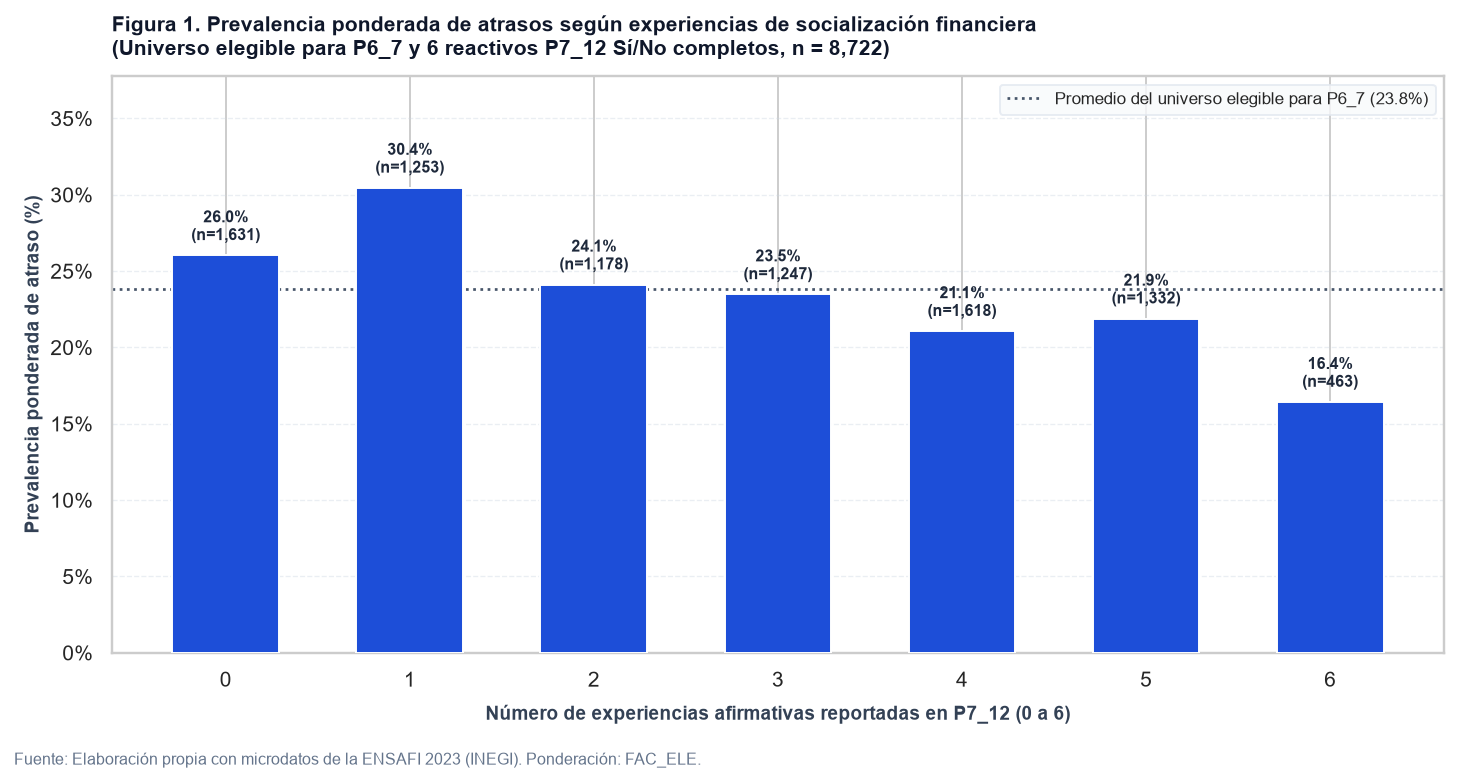

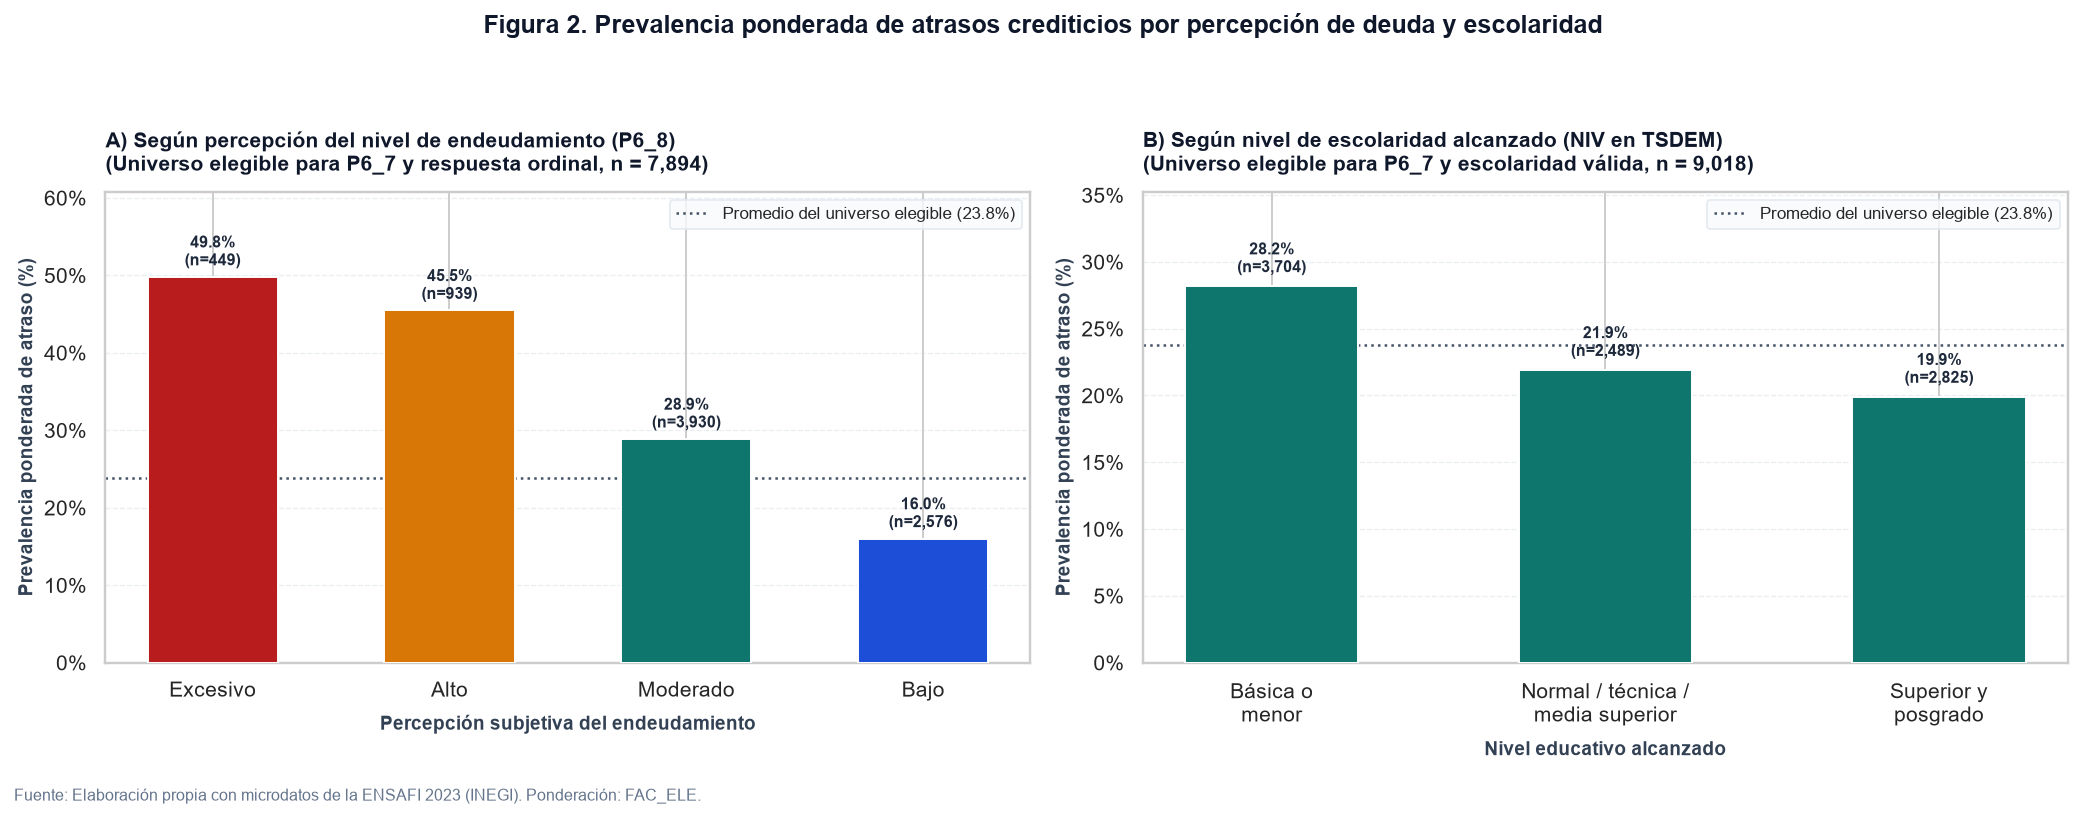

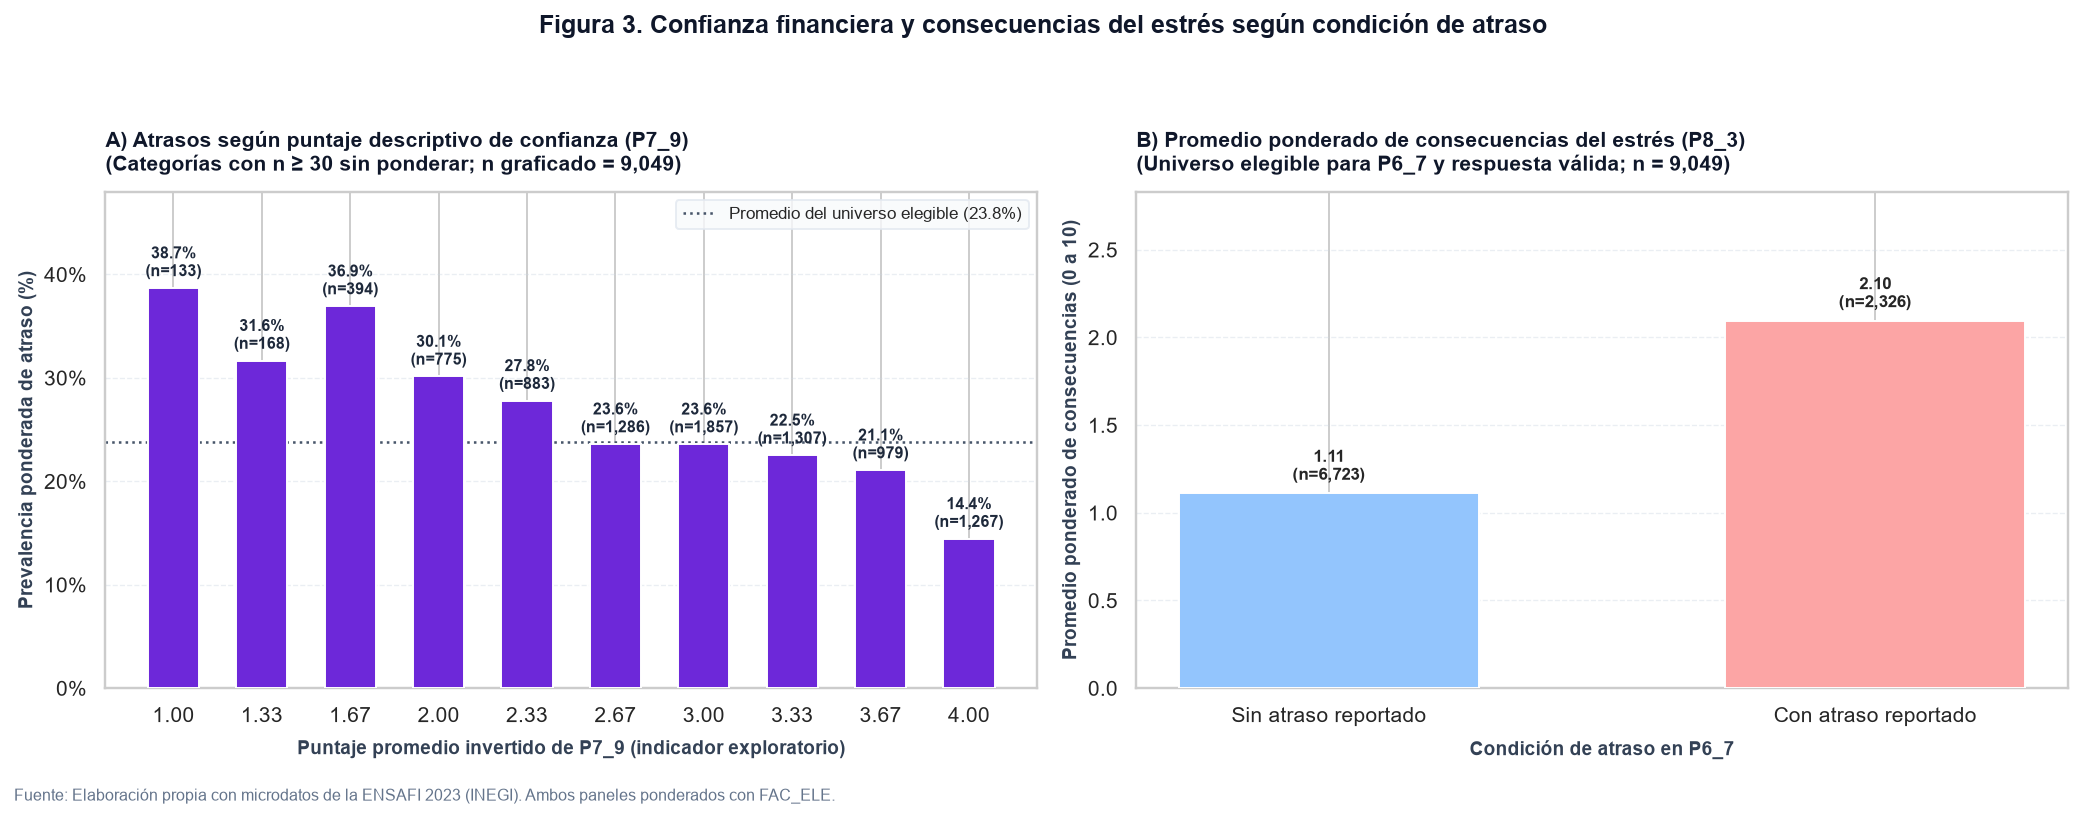

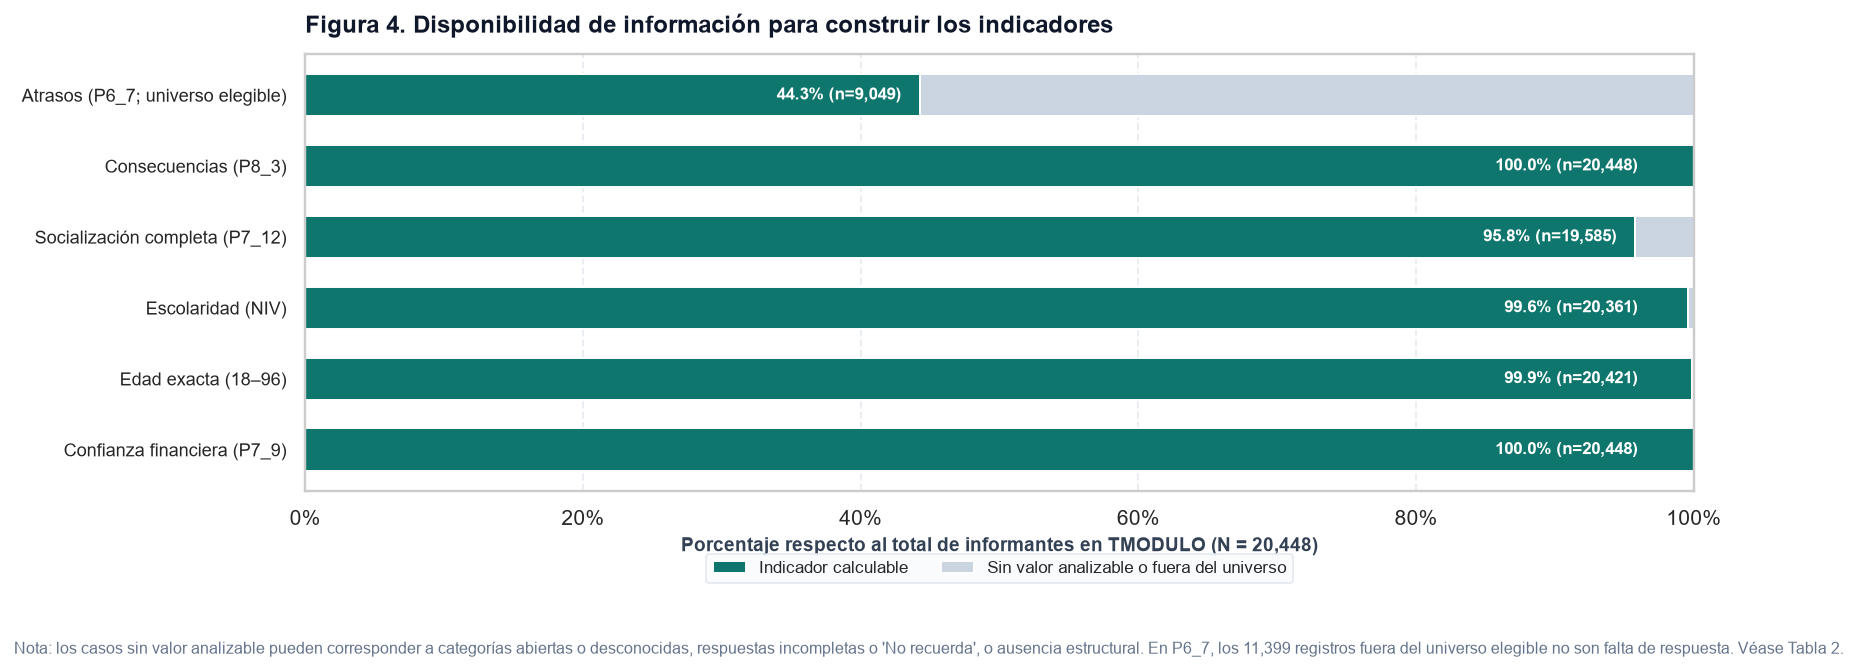

In [37]:
# CELDA 4. VISUALIZACIONES DESCRIPTIVAS PONDERADAS (FIGURAS 1 A 4)
tasa_ref = tasa_global["porcentaje"]
p1_salidas = Path("salidas") / "pregunta_1"
p1_salidas.mkdir(parents=True, exist_ok=True)


def estilar_eje(ax, titulo, ylabel, xlabel, ylim_max=None):
    ax.set_title(
        titulo,
        loc="left",
        fontsize=11,
        fontweight="bold",
        pad=11,
        color="#0F172A"
    )
    ax.set_ylabel(
        ylabel,
        fontsize=9.8,
        fontweight="bold",
        color="#334155"
    )
    ax.set_xlabel(
        xlabel,
        fontsize=9.8,
        fontweight="bold",
        color="#334155",
        labelpad=7
    )

    if ylim_max is not None:
        ax.set_ylim(0, ylim_max)

    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.yaxis.grid(
        True,
        linestyle="--",
        linewidth=0.7,
        alpha=0.4,
        color="#CBD5E1"
    )
    ax.set_axisbelow(True)


def etiquetar_barras(ax, bars, vals, ns, offset=0.7):
    for bar, val, n in zip(bars, vals, ns):
        if pd.isna(val):
            continue

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val + offset,
            f"{val:.1f}%\n(n={int(n):,})",
            ha="center",
            va="bottom",
            fontsize=8.3,
            fontweight="bold",
            color="#1E293B"
        )


# FIGURA 1. Atrasos según experiencias de socialización financiera (P7_12)
plot1 = tabla_soc_exacta.dropna(
    subset=["Prevalencia ponderada (%)"]
).copy()

plot1["x"] = pd.to_numeric(plot1["Categoría"], errors="coerce")
plot1 = plot1.sort_values("x")

fig1, ax1 = plt.subplots(figsize=(10.5, 5.6), dpi=140)

bars1 = ax1.bar(
    plot1["x"].astype(int).astype(str),
    plot1["Prevalencia ponderada (%)"],
    color="#1D4ED8",
    edgecolor="white",
    width=0.58,
    zorder=3
)

if pd.notna(tasa_ref):
    ax1.axhline(
        tasa_ref,
        color="#475569",
        linestyle=":",
        linewidth=1.4,
        zorder=2,
        label=f"Promedio del universo elegible para P6_7 ({tasa_ref:.1f}%)"
    )

    ax1.legend(
        frameon=True,
        facecolor="#F8FAFC",
        edgecolor="#E2E8F0",
        fontsize=8.8,
        loc="upper right"
    )

ylim1 = max(
    plot1["Prevalencia ponderada (%)"].max() * 1.24,
    35
)

estilar_eje(
    ax1,
    f"Figura 1. Prevalencia ponderada de atrasos según experiencias de socialización financiera\n"
    f"(Universo elegible para P6_7 y 6 reactivos P7_12 Sí/No completos, "
    f"n = {int(plot1['n válido (muestra)'].sum()):,})",
    "Prevalencia ponderada de atraso (%)",
    "Número de experiencias afirmativas reportadas en P7_12 (0 a 6)",
    ylim_max=ylim1
)

etiquetar_barras(
    ax1,
    bars1,
    plot1["Prevalencia ponderada (%)"],
    plot1["n válido (muestra)"]
)

fig1.text(
    0.01,
    0.01,
    "Fuente: Elaboración propia con microdatos de la ENSAFI 2023 (INEGI). Ponderación: FAC_ELE.",
    fontsize=8.2,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.03, 1, 1])
fig1.savefig(p1_salidas / "p1_01_socializacion_atrasos.png", dpi=150, bbox_inches="tight")
plt.show()


# FIGURA 2. Atrasos según percepción del endeudamiento (P6_8) y escolaridad
fig2, axes2 = plt.subplots(1, 2, figsize=(15, 5.8), dpi=140)


# Panel A: Percepción del nivel de endeudamiento (P6_8)
plot2a = tabla_percepcion.dropna(
    subset=["Prevalencia ponderada (%)"]
).copy()

ylim2a = (
    max(plot2a["Prevalencia ponderada (%)"].max() * 1.22, 40)
    if not plot2a.empty else 50
)

bars2a = axes2[0].bar(
    plot2a["Categoría"],
    plot2a["Prevalencia ponderada (%)"],
    color=["#B91C1C", "#D97706", "#0F766E", "#1D4ED8"][:len(plot2a)],
    edgecolor="white",
    width=0.55,
    zorder=3
)

if pd.notna(tasa_ref):
    axes2[0].axhline(
        tasa_ref,
        color="#475569",
        linestyle=":",
        linewidth=1.3,
        zorder=2,
        label=f"Promedio del universo elegible ({tasa_ref:.1f}%)"
    )

    axes2[0].legend(
        frameon=True,
        facecolor="#F8FAFC",
        edgecolor="#E2E8F0",
        fontsize=8.5,
        loc="upper right"
    )

estilar_eje(
    axes2[0],
    f"A) Según percepción del nivel de endeudamiento (P6_8)\n"
    f"(Universo elegible para P6_7 y respuesta ordinal, "
    f"n = {int(plot2a['n válido (muestra)'].sum()):,})",
    "Prevalencia ponderada de atraso (%)",
    "Percepción subjetiva del endeudamiento",
    ylim_max=ylim2a
)

etiquetar_barras(
    axes2[0],
    bars2a,
    plot2a["Prevalencia ponderada (%)"],
    plot2a["n válido (muestra)"],
    offset=0.9
)


# Panel B: Nivel de escolaridad (NIV)
plot2b = tabla_escolaridad.dropna(
    subset=["Prevalencia ponderada (%)"]
).copy()

etiquetas_edu = [
    "Básica o\nmenor",
    "Normal / técnica /\nmedia superior",
    "Superior y\nposgrado"
]

ylim2b = (
    max(plot2b["Prevalencia ponderada (%)"].max() * 1.25, 35)
    if not plot2b.empty else 40
)

bars2b = axes2[1].bar(
    etiquetas_edu[:len(plot2b)],
    plot2b["Prevalencia ponderada (%)"],
    color="#0F766E",
    edgecolor="white",
    width=0.52,
    zorder=3
)

if pd.notna(tasa_ref):
    axes2[1].axhline(
        tasa_ref,
        color="#475569",
        linestyle=":",
        linewidth=1.3,
        zorder=2,
        label=f"Promedio del universo elegible ({tasa_ref:.1f}%)"
    )

    axes2[1].legend(
        frameon=True,
        facecolor="#F8FAFC",
        edgecolor="#E2E8F0",
        fontsize=8.5,
        loc="upper right"
    )

estilar_eje(
    axes2[1],
    f"B) Según nivel de escolaridad alcanzado (NIV en TSDEM)\n"
    f"(Universo elegible para P6_7 y escolaridad válida, "
    f"n = {int(plot2b['n válido (muestra)'].sum()):,})",
    "Prevalencia ponderada de atraso (%)",
    "Nivel educativo alcanzado",
    ylim_max=ylim2b
)

etiquetar_barras(
    axes2[1],
    bars2b,
    plot2b["Prevalencia ponderada (%)"],
    plot2b["n válido (muestra)"]
)

fig2.suptitle(
    "Figura 2. Prevalencia ponderada de atrasos crediticios por percepción de deuda y escolaridad",
    fontsize=13,
    fontweight="bold",
    y=0.98,
    color="#0F172A"
)

fig2.text(
    0.01,
    0.01,
    "Fuente: Elaboración propia con microdatos de la ENSAFI 2023 (INEGI). Ponderación: FAC_ELE.",
    fontsize=8.2,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.03, 1, 0.93])
fig2.savefig(p1_salidas / "p1_02_percepcion_escolaridad.png", dpi=150, bbox_inches="tight")
plt.show()


# FIGURA 3. Confianza financiera (P7_9) y consecuencias del estrés (P8_3)
fig3, axes3 = plt.subplots(1, 2, figsize=(15, 5.8), dpi=140)


# Panel A: Confianza financiera (P7_9 invertido, categorías con n >= 30)
plot3a = tabla_confianza[
    tabla_confianza["n válido (muestra)"] >= 30
].copy()

plot3a["x"] = pd.to_numeric(
    plot3a["Categoría"],
    errors="coerce"
)

plot3a = plot3a.sort_values("x")

if not plot3a.empty:
    ylim3a = max(
        plot3a["Prevalencia ponderada (%)"].max() * 1.24,
        35
    )

    bars3a = axes3[0].bar(
        [f"{v:.2f}" for v in plot3a["x"]],
        plot3a["Prevalencia ponderada (%)"],
        color="#6D28D9",
        edgecolor="white",
        width=0.58,
        zorder=3
    )

    if pd.notna(tasa_ref):
        axes3[0].axhline(
            tasa_ref,
            color="#475569",
            linestyle=":",
            linewidth=1.3,
            zorder=2,
            label=f"Promedio del universo elegible ({tasa_ref:.1f}%)"
        )

        axes3[0].legend(
            frameon=True,
            facecolor="#F8FAFC",
            edgecolor="#E2E8F0",
            fontsize=8.5,
            loc="upper right"
        )

    estilar_eje(
        axes3[0],
        f"A) Atrasos según puntaje descriptivo de confianza (P7_9)\n"
        f"(Categorías con n ≥ 30 sin ponderar; "
        f"n graficado = {int(plot3a['n válido (muestra)'].sum()):,})",
        "Prevalencia ponderada de atraso (%)",
        "Puntaje promedio invertido de P7_9 (indicador exploratorio)",
        ylim_max=ylim3a
    )

    etiquetar_barras(
        axes3[0],
        bars3a,
        plot3a["Prevalencia ponderada (%)"],
        plot3a["n válido (muestra)"]
    )


# Panel B: Promedio ponderado de consecuencias del estrés financiero (P8_3)
sub_estres = base_credito.dropna(
    subset=["consecuencias_estres_n", "atraso_credito", "FAC_ELE"]
).copy()

if not sub_estres.empty:
    grupos = [
        sub_estres[sub_estres["atraso_credito"].eq(0)],
        sub_estres[sub_estres["atraso_credito"].eq(1)]
    ]

    medias = [
        promedio_ponderado_conteo(g, "consecuencias_estres_n")
        for g in grupos
    ]

    ns = [len(g) for g in grupos]

    barras = axes3[1].bar(
        ["Sin atraso reportado", "Con atraso reportado"],
        medias,
        color=["#93C5FD", "#FCA5A5"],
        edgecolor="white",
        width=0.55,
        zorder=3
    )

    for bar, media, n in zip(barras, medias, ns):
        axes3[1].text(
            bar.get_x() + bar.get_width() / 2,
            media + 0.05,
            f"{media:.2f}\n(n={n:,})",
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold"
        )

    axes3[1].set_ylim(0, max(medias) * 1.35)

    axes3[1].set_title(
        f"B) Promedio ponderado de consecuencias del estrés (P8_3)\n"
        f"(Universo elegible para P6_7 y respuesta válida; n = {sum(ns):,})",
        loc="left",
        fontsize=11,
        fontweight="bold",
        pad=11,
        color="#0F172A"
    )

    axes3[1].set_ylabel(
        "Promedio ponderado de consecuencias (0 a 10)",
        fontsize=9.8,
        fontweight="bold",
        color="#334155"
    )

    axes3[1].set_xlabel(
        "Condición de atraso en P6_7",
        fontsize=9.8,
        fontweight="bold",
        color="#334155",
        labelpad=7
    )

    axes3[1].yaxis.grid(
        True,
        linestyle="--",
        linewidth=0.7,
        alpha=0.4,
        color="#CBD5E1"
    )

    axes3[1].set_axisbelow(True)


fig3.suptitle(
    "Figura 3. Confianza financiera y consecuencias del estrés según condición de atraso",
    fontsize=13,
    fontweight="bold",
    y=0.98,
    color="#0F172A"
)

fig3.text(
    0.01,
    0.01,
    "Fuente: Elaboración propia con microdatos de la ENSAFI 2023 (INEGI). Ambos paneles ponderados con FAC_ELE.",
    fontsize=8.2,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.03, 1, 0.93])
fig3.savefig(p1_salidas / "p1_03_confianza_consecuencias.png", dpi=150, bbox_inches="tight")
plt.show()


# FIGURA 4. Disponibilidad de información para los indicadores
n_tot = len(df)

auditoria_plot = [
    (
        "Confianza financiera (P7_9)",
        int(df["confianza_financiera_score"].notna().sum()),
        int(df["confianza_financiera_score"].isna().sum())
    ),
    (
        "Edad exacta (18–96)",
        int(df["edad_exacta"].notna().sum()),
        int(df["edad_exacta"].isna().sum())
    ),
    (
        "Escolaridad (NIV)",
        int(df["escolaridad_grupo"].notna().sum()),
        int(df["escolaridad_grupo"].isna().sum())
    ),
    (
        "Socialización completa (P7_12)",
        int(df["socializacion_n_si"].notna().sum()),
        int(df["socializacion_n_si"].isna().sum())
    ),
    (
        "Consecuencias (P8_3)",
        int(df["consecuencias_estres_n"].notna().sum()),
        int(df["consecuencias_estres_n"].isna().sum())
    ),
    (
        "Atrasos (P6_7; universo elegible)",
        int(df["atraso_credito"].notna().sum()),
        int(df["atraso_credito"].isna().sum())
    ),
]

# La figura muestra únicamente si el indicador puede calcularse en cada registro.
# La causa de no disponibilidad varía por variable y se detalla en la Tabla 2.
labels_aud = [x[0] for x in auditoria_plot]
p_val = np.array([x[1] / n_tot * 100 for x in auditoria_plot])
p_no = np.array([x[2] / n_tot * 100 for x in auditoria_plot])
y_pos = np.arange(len(labels_aud))

fig4, ax4 = plt.subplots(figsize=(12.5, 4.8), dpi=140)

ax4.barh(
    y_pos,
    p_val,
    color="#0F766E",
    edgecolor="white",
    height=0.60,
    label="Indicador calculable"
)

ax4.barh(
    y_pos,
    p_no,
    left=p_val,
    color="#CBD5E1",
    edgecolor="white",
    height=0.60,
    label="Sin valor analizable o fuera del universo"
)

for i, (row, pv) in enumerate(zip(auditoria_plot, p_val)):
    ax4.text(
        min(pv - 1.3, 96) if pv > 18 else pv + 1.3,
        i,
        f"{pv:.1f}% (n={row[1]:,})",
        va="center",
        ha="right" if pv > 18 else "left",
        fontsize=8.5,
        fontweight="bold",
        color="white" if pv > 18 else "#1E293B"
    )

ax4.set_yticks(y_pos)
ax4.set_yticklabels(labels_aud, fontsize=9.3)
ax4.set_xlim(0, 100)

ax4.xaxis.set_major_formatter(
    mtick.PercentFormatter(decimals=0)
)

ax4.set_xlabel(
    f"Porcentaje respecto al total de informantes en TMODULO (N = {n_tot:,})",
    fontsize=9.6,
    fontweight="bold",
    color="#334155"
)

ax4.set_title(
    "Figura 4. Disponibilidad de información para construir los indicadores",
    fontsize=12.2,
    fontweight="bold",
    loc="left",
    pad=11,
    color="#0F172A"
)

ax4.grid(
    axis="x",
    linestyle="--",
    alpha=0.4,
    color="#CBD5E1"
)

ax4.set_axisbelow(True)

ax4.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, -0.23),
    ncol=2,
    frameon=True,
    facecolor="#F8FAFC",
    edgecolor="#E2E8F0",
    fontsize=8.5
)

fig4.text(
    0.01,
    0.01,
    "Nota: los casos sin valor analizable pueden corresponder a categorías abiertas o desconocidas, "
    "respuestas incompletas o 'No recuerda', o ausencia estructural. En P6_7, los 11,399 registros "
    "fuera del universo elegible no son falta de respuesta. Véase Tabla 2.",
    fontsize=8.0,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
fig4.savefig(p1_salidas / "p1_04_disponibilidad_indicadores.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Interpretación de resultados

### 5.1 Panorama general: población elegible para la pregunta de atrasos y prevalencia observada

Dentro del universo de personas que reportaron al menos un préstamo informal (`P6_5_*`) o la tenencia de un producto de crédito formal (`P6_6_*`), se identificaron **9,049 informantes** con respuestas válidas en `P6_7`, equivalentes a aproximadamente **38,884,626 personas adultas** en el país, de acuerdo con el factor de expansión `FAC_ELE`.

De este universo:

- **Con atrasos (`P6_7 = 1`):** 2,326 personas en muestra, equivalentes a una prevalencia ponderada de **23.81 %** (aproximadamente **9,258,377 adultos**).
- **Sin atrasos (`P6_7 = 2`):** 6,723 personas en muestra, equivalentes a una proporción ponderada de **76.19 %**.

Estas estimaciones se calcularon utilizando el factor de expansión `FAC_ELE`. El denominador corresponde exclusivamente a las personas con respuestas válidas en P6_7 dentro del universo que cumple el filtro de elegibilidad establecido por el cuestionario.

> **Nota sobre temporalidad del reactivo:** La pregunta `P6_7` no especifica explícitamente un horizonte de 12 meses. Por ello, el indicador se interpreta estrictamente como el reporte de atraso captado por el cuestionario, sin atribuirle un periodo de referencia adicional ni afirmar que el atraso continúe vigente al momento de la entrevista.

### 5.2 Socialización y aprendizaje financiero (`P7_12`)

La socialización financiera presenta diferencias descriptivas en la prevalencia de atrasos. Al agrupar el número de experiencias afirmativas declaradas en tres niveles, se observa el siguiente comportamiento:

| Nivel de socialización financiera | Prevalencia ponderada de atrasos |
| :--- | :---: |
| **Bajo** | **27.93 %** |
| **Medio** | **23.79 %** |
| **Alto** | **20.71 %** |

Los resultados muestran una menor prevalencia de atrasos en el grupo con un mayor número de experiencias de socialización y aprendizaje financiero. La diferencia entre los grupos bajo y alto es de **7.22 puntos porcentuales**.

Este patrón es compatible con la posibilidad de que las experiencias de aprendizaje y conversación sobre asuntos financieros estén relacionadas con distintas formas de administrar los recursos. Sin embargo, el indicador utilizado registra la presencia de experiencias declaradas y no evalúa directamente los conocimientos, las habilidades ni la calidad de dichas experiencias. Por tanto, no puede concluirse que una mayor socialización financiera produzca necesariamente una reducción de los atrasos.

También debe considerarse que el indicador se calculó únicamente para quienes contaban con seis respuestas completas de Sí/No en `P7_12`. Los casos con respuestas de *No recuerda* no se incorporaron al conteo, por lo que la comparación corresponde a la población con información completa para este indicador.

### 5.3 Percepción del nivel de endeudamiento (`P6_8`)

Esta dimensión presenta uno de los contrastes descriptivos más marcados del análisis, con una brecha de **33.80 puntos porcentuales** entre los extremos de la escala de percepción del endeudamiento:

| Percepción declarada del endeudamiento | Prevalencia ponderada de atrasos |
| :--- | :---: |
| **Excesivo** | **49.79 %** |
| **Alto** | **45.45 %** |
| **Moderado** | **28.85 %** |
| **Bajo** | **15.99 %** |

En los datos, una percepción más desfavorable del peso de la deuda coincide con mayores proporciones de personas que reportaron atrasos en sus pagos. La diferencia entre quienes consideran su endeudamiento excesivo y quienes lo perciben como bajo es de 33.80 puntos porcentuales.

Este patrón constituye una asociación descriptiva relevante. Sin embargo, al tratarse de información transversal, no es posible determinar si la percepción de sobreendeudamiento antecede al atraso, si se modifica como consecuencia de este o si ambos fenómenos responden a otros factores económicos.

**Nota de interpretación:** Las categorías *No tiene deudas* (1.60 %) y *No sabe* (12.21 %) corresponden a respuestas declaradas por los informantes sobre su percepción del endeudamiento. No representan una verificación independiente de la existencia o inexistencia de un saldo pendiente. Esto es relevante porque la elegibilidad para responder P6_7 se determina a partir del reporte de préstamos informales o de la tenencia de productos de crédito, mientras que P6_8 recoge la percepción subjetiva de la persona sobre su nivel de endeudamiento. Por ello, ambas dimensiones deben interpretarse por separado.

### 5.4 Confianza financiera (`P7_9`)

La confianza financiera se aproximó mediante el promedio invertido de tres reactivos ordinales (`P7_9_1` a `P7_9_3`), con valores comprendidos entre 1.0 y 4.0. En la construcción utilizada, los valores mayores representan niveles más altos del indicador descriptivo de confianza.

La comparación de la prevalencia de atrasos entre las categorías observadas muestra una tendencia general descendente hacia los valores más altos del indicador. En los extremos, la prevalencia ponderada pasa de **38.67 %** en la categoría de 1.00 a **14.43 %** en la categoría de 4.00.

No obstante, el comportamiento entre las categorías intermedias no es estrictamente monotónico. Por ejemplo, se observan variaciones entre los primeros valores del indicador. Por ello, el resultado debe interpretarse como un patrón exploratorio general y no como evidencia de una relación lineal o de un efecto de la confianza sobre los atrasos.

Para evitar comparaciones basadas en grupos con pocos registros, la Figura 3A presenta únicamente las categorías con al menos 30 observaciones sin ponderar. Este criterio funciona como una restricción descriptiva de presentación y no sustituye un cálculo de precisión estadística.

Asimismo, el promedio de los tres reactivos no constituye una escala psicométrica validada. En consecuencia, los resultados describen diferencias entre categorías del indicador construido, pero no permiten afirmar que se haya medido exhaustivamente la confianza financiera de las personas.

Como análisis complementario, se examinó la clasificación oficial `CONF_FINAN`, derivada de los mismos tres reactivos P7_9. La comparación dentro del universo elegible para P6_7 presenta los siguientes resultados:

| Clasificación oficial `CONF_FINAN` | n válido (muestra) | Atrasos (n muestra) | Prevalencia ponderada de atrasos |
| :--- | :---: | :---: | :---: |
| **Muy característico (código 1)** | 6,696 | 1,536 | **21.36 %** |
| **Poco característico (código 2)** | 2,353 | 790 | **30.96 %** |

La diferencia descriptiva entre ambas categorías es de **9.60 puntos porcentuales**. Esta clasificación no debe interpretarse como una dimensión independiente del puntaje promedio invertido presentado previamente: ambas medidas resumen los mismos tres reactivos, aunque utilizan reglas de agregación distintas. Los resultados no permiten establecer una relación causal entre la confianza financiera y el reporte de atrasos.

### 5.5 Escolaridad y atrasos en los pagos (`NIV`)

La escolaridad también presenta diferencias descriptivas en la prevalencia ponderada de atrasos:

| Grupo de escolaridad | Prevalencia ponderada de atrasos |
| :--- | :---: |
| **Básica o menor** | **28.18 %** |
| **Normal, técnica o media superior** | **21.91 %** |
| **Superior y posgrado** | **19.90 %** |

Se observa una menor prevalencia de atrasos en los grupos con niveles educativos más altos. La diferencia entre el grupo de escolaridad básica o menor y el grupo de educación superior o posgrado es de **8.28 puntos porcentuales**.

Este resultado permite identificar una diferencia entre grupos educativos, pero no demuestra que la escolaridad determine directamente el comportamiento de pago. Las diferencias podrían estar relacionadas con otras características económicas y sociodemográficas que no se controlan en este análisis descriptivo.

Por otra parte, la comparación se realiza únicamente con los registros que cuentan con una clasificación educativa utilizable. Los casos sin especificación de escolaridad no se incorporan a las categorías comparadas.

### 5.6 Consecuencias del estrés financiero (`P8_3`)

El indicador `consecuencias_estres_n` contabiliza el número de tipos de consecuencias que las personas declararon haber experimentado a causa de su situación financiera desde octubre de 2022. Su rango va de 0 a 10 y cada reactivo tiene el mismo peso en el conteo.

Al comparar el promedio ponderado de este indicador según la condición de atraso reportada en `P6_7`, se obtiene lo siguiente:

| Condición de atraso reportada | Promedio ponderado de consecuencias |
| :--- | :---: |
| **Sin atraso reportado** | **1.11** |
| **Con atraso reportado** | **2.10** |

En términos descriptivos, las personas que reportaron atrasos presentan un mayor número promedio ponderado de consecuencias asociadas con su situación financiera que quienes no reportaron atrasos. La diferencia se interpreta a partir de los promedios mostrados, sin restar valores redondeados.

Este contraste muestra que el reporte de atrasos coincide con una mayor presencia de consecuencias financieras, personales o familiares contempladas en el cuestionario. Sin embargo, el conteo no mide la intensidad, gravedad ni duración de cada consecuencia; únicamente registra cuántos tipos fueron declarados.

Además, debido a que la información es transversal y las respuestas corresponden a experiencias reportadas por los informantes, no puede establecerse que los atrasos sean la causa directa de las consecuencias observadas. Tampoco puede descartarse que existan factores económicos compartidos que estén relacionados con ambos fenómenos.

### 5.7 Conclusión general y limitaciones del análisis

Con base en los microdatos de la ENSAFI 2023, se estima que la prevalencia ponderada de atrasos en los pagos es de **23.81 %** entre las personas adultas que cumplen el filtro de elegibilidad establecido por las preguntas P6_5 y P6_6 y que cuentan con una respuesta válida en P6_7. Esta proporción representa aproximadamente 9.26 millones de personas adultas, de acuerdo con el factor de expansión `FAC_ELE`.

La prevalencia no es homogénea entre los grupos examinados. Se identifican diferencias descriptivas relevantes según la percepción del endeudamiento, la socialización financiera, la confianza financiera y la escolaridad. En particular, la percepción de endeudamiento excesivo presenta una prevalencia de atrasos considerablemente mayor que la percepción de endeudamiento bajo. Asimismo, los grupos con más experiencias de socialización financiera y mayor escolaridad muestran proporciones menores de atrasos en las comparaciones realizadas.

En cuanto a la confianza financiera, el indicador exploratorio construido a partir de P7_9 presenta una tendencia general descendente de la prevalencia hacia sus valores más altos, aunque con variaciones entre categorías intermedias. La clasificación oficial complementaria `CONF_FINAN` también muestra una prevalencia menor en la categoría *Muy característico* (21.36 %) que en *Poco característico* (30.96 %); ambas medidas se derivan de los mismos reactivos y no deben considerarse dimensiones independientes. Por su parte, el número promedio de consecuencias del estrés financiero es mayor entre quienes reportaron atrasos que entre quienes no los reportaron.

En conjunto, los resultados muestran que los atrasos en los pagos se presentan junto con diferencias en las experiencias de socialización financiera, la percepción subjetiva del endeudamiento, la confianza financiera, la escolaridad y las consecuencias del estrés. Estas diferencias permiten caracterizar distintos perfiles dentro de la población analizada y ofrecen elementos para orientar investigaciones posteriores sobre salud financiera.

**Alcances y limitaciones.** Las estimaciones presentadas son descriptivas y corresponden a la información reportada en la ENSAFI 2023. El uso de `FAC_ELE` permite obtener estimaciones puntuales expandidas, pero no se calcularon errores estándar ni intervalos de confianza que incorporen el diseño muestral complejo. Por ello, las diferencias entre grupos deben interpretarse como contrastes descriptivos y no como diferencias estadísticamente significativas demostradas.

Asimismo, la naturaleza transversal de los datos no permite establecer temporalidad causal ni identificar efectos de una dimensión sobre otra. Algunos indicadores son aproximaciones construidas para este estudio: el conteo de experiencias de socialización no mide conocimientos objetivos, el promedio de P7_9 no constituye una escala psicométrica validada y el conteo de P8_3 no representa la intensidad de las consecuencias.

Finalmente, la elegibilidad para responder P6_7 no equivale necesariamente a la existencia de un saldo pendiente al momento de la entrevista. En consecuencia, los resultados deben entenderse como la prevalencia de atrasos reportados dentro del universo definido por el cuestionario y no como una medición directa de la morosidad vigente de toda la población adulta mexicana.

# Pregunta 2. Hábitos financieros, experiencias educativas y ahorro
## 1. Planteamiento y diseño del análisis

### 1.1 Pregunta de investigación

> **¿Cómo se relacionan los hábitos de administración del dinero y las experiencias declaradas de educación financiera con la disponibilidad de ahorros y la capacidad reportada para afrontar una emergencia económica en México durante 2023?**

Se examinan dos preguntas complementarias: **(a)** si quienes registran sus ingresos y gastos declaran una mayor equivalencia de ahorros en meses de ingreso y **(b)** cómo varía la capacidad para afrontar emergencias entre quienes utilizan mecanismos de ahorro exclusivamente formales, exclusivamente informales, ambos o ninguno.

### 1.2 Objetivo y alcance

Utilizamos los microdatos individuales de la **ENSAFI 2023** para describir prevalencias ponderadas y contrastar diferencias entre grupos. Las variables `P7_1`, `P7_12_2` y `P7_12_3` capturan, respectivamente, el registro de ingresos y gastos, la orientación familiar sobre el ahorro y las actividades escolares relacionadas con dinero. **No constituyen una prueba objetiva de conocimientos financieros**.

La encuesta es observacional y transversal. Las diferencias que se estiman son **asociaciones, no efectos causales**. Distinguimos entre **tener algún ahorro**, **equivalencia del ahorro en ingresos**, **disponer de dinero sobrante**, **ahorrar durante el último mes** y **poder afrontar una emergencia con ahorros**: no son medidas intercambiables.

### 1.3 Datos y unidad de estudio

La unidad es la **persona adulta seleccionada para `TMODULO`**. Esta pregunta reutiliza el DataFrame `df_tmodulo` ya cargado en la sección de datos de `ENSAFI_EDA`, sin importar ni leer otro CSV ni fusionarlo de nuevo con `TSDEM`. La base se trabaja en una **copia independiente** `p2_datos`, de modo que los indicadores y resultados de la pregunta 1 permanecen intactos.

Se conservan `FAC_ELE` (factor de expansión), `EST_DIS` (estrato) y `UPM_DIS` (conglomerado), junto con las variables del cuestionario. Las proporciones descriptivas se calculan sobre respuestas válidas, ponderadas por `FAC_ELE`; las inferencias usan una aproximación de varianza por linealización de Taylor para estratos y conglomerados.

### 1.4 Mapa de indicadores

| Concepto | Variables | Criterio |
|---|---|---|
| Ahorro informal | `P6_1_1`–`P6_1_6` | Al menos una opción «Sí»; ausencia solo si todas son «No» |
| Ahorro formal | `P6_2_01`–`P6_2_10`, `P6_3` | Ahorro declarado en productos formales; **tener un producto no basta** |
| Algún ahorro | Indicadores anteriores | Al menos una modalidad afirmativa |
| Equivalencia del ahorro | `P6_4` | Cinco categorías entre quienes ahorran y responden válidamente |
| Afrontar emergencia con ahorros | `P7_6_1` | Respuesta «Sí» o «No» a la posibilidad de cubrir una urgencia de un mes de ingresos |
| Registro de ingresos y gastos | `P7_1` | «Sí»/«No» |
| Orientación familiar y actividades escolares | `P7_12_2`, `P7_12_3` | «No recuerda» no se convierte en «No» |
| Dinero sobrante y ahorro reciente | `P7_7_2`, `P6_9`, `P6_11_2` | Se respetan la escala y los filtros del cuestionario |

**Ubicación:** agrega todas las celdas de esta pregunta **después de la última celda de la pregunta 1** de `ENSAFI_EDA`. Ejecuta primero la celda de carga de datos de `ENSAFI_EDA` y utiliza los CSV originales de ENSAFI 2023. Este bloque no necesita volver a cargar las bases.

## 2. Integración, auditoría y construcción de indicadores

### 2.1 Reutilización de `TMODULO` y validación de las columnas

No se repiten las importaciones de `pandas`, `numpy`, `matplotlib` ni `Path`, ni la lectura de archivos del notebook principal. Se importa únicamente `scipy.stats`, necesario para la inferencia, y se crea una carpeta exclusiva para salidas de la pregunta 2.

In [38]:
# Dependencia nueva: los demás paquetes ya se importaron en ENSAFI_EDA.
from scipy import stats

if 'df_tmodulo' not in globals():
    raise RuntimeError('Ejecuta antes la sección «1. Carga de datos» de ENSAFI_EDA.')

p2_p6_1 = [f'P6_1_{i}' for i in range(1, 7)]
p2_p6_2 = [f'P6_2_{i:02d}' for i in range(1, 11)]
p2_claves = ['UPM', 'VIV_SEL', 'HOGAR', 'N_REN']
p2_columnas = [
    *p2_claves, 'FAC_ELE', 'EST_DIS', 'UPM_DIS',
    *p2_p6_1, *p2_p6_2,
    'P6_3', 'P6_4', 'P6_9', 'P6_11_2',
    'P7_1', 'P7_6_1', 'P7_7_2', 'P7_12_2', 'P7_12_3'
]
p2_faltantes = sorted(set(p2_columnas) - set(df_tmodulo.columns))
if p2_faltantes:
    raise KeyError(f'Faltan variables de TMODULO: {p2_faltantes}')

# Copia para no alterar df_tmodulo, df ni los demás resultados de la pregunta 1.
p2_datos = df_tmodulo.loc[:, p2_columnas].copy()
p2_variables_numericas = [c for c in p2_columnas if c not in p2_claves]
p2_datos[p2_variables_numericas] = p2_datos[p2_variables_numericas].apply(
    pd.to_numeric, errors='coerce'
)

if p2_datos.duplicated(subset=p2_claves).any():
    raise ValueError('Se encontraron personas duplicadas en la llave compuesta.')
if p2_datos[['FAC_ELE', 'EST_DIS', 'UPM_DIS']].isna().any().any():
    raise ValueError('Existen valores faltantes en las variables del diseño muestral.')
if (p2_datos['FAC_ELE'] <= 0).any():
    raise ValueError('El factor de expansión debe ser positivo.')

p2_salidas = Path('salidas') / 'pregunta_2'
p2_salidas.mkdir(parents=True, exist_ok=True)
print(f'Personas conservadas: {len(p2_datos):,} | columnas utilizadas: {len(p2_columnas)}')
print(f'Llaves duplicadas: {p2_datos.duplicated(subset=p2_claves).sum()}')
print(f'UPM distintas por estrato: {p2_datos[["EST_DIS", "UPM_DIS"]].drop_duplicates().shape[0]:,}')
print(f'Salidas: {p2_salidas.resolve()}')

Personas conservadas: 20,448 | columnas utilizadas: 32
Llaves duplicadas: 0
UPM distintas por estrato: 2,915
Salidas: C:\Users\52443\Downloads\ensafi-repo\notebooks\salidas\pregunta_2


**Interpretación — Revisión de la base de trabajo.**

Se conserva la unidad de análisis individual y la llave compuesta sin duplicados. El conjunto de trabajo incluye **20,448 registros de personas** y es una copia de `TMODULO`; por ello no altera los datos del EDA ni los indicadores de la pregunta 1.

### 2.2 Auditoría de valores especiales y filtros

Se comprueban los códigos esperados antes de crear indicadores. En esta pregunta, `P6_3` se aplica si se declaró al menos un producto formal en `P6_2`; `P6_4` se aplica si existe ahorro informal o formal declarado; y `P6_11_2` se aplica si se pudieron cubrir los gastos sin endeudarse (`P6_9 = 1`). Por tanto, **un `NaN` por salto del cuestionario no equivale a una respuesta negativa**.

Los códigos `9` de `P6_4` («No sabe») y `3` de `P7_12_2` y `P7_12_3` («No recuerda») se preservan primero para la auditoría y después se recodifican como faltantes **solo en la copia de análisis**.

In [39]:
p2_codigos = {
    **{c: {1, 2} for c in [*p2_p6_1, *p2_p6_2, 'P6_3', 'P6_9', 'P6_11_2', 'P7_1', 'P7_6_1']},
    'P6_4': {1, 2, 3, 4, 5, 9},
    'P7_7_2': {1, 2, 3, 4, 5},
    'P7_12_2': {1, 2, 3}, 'P7_12_3': {1, 2, 3}
}
p2_auditoria = pd.DataFrame([
    {
        'Variable': c,
        'Faltantes (n)': int(p2_datos[c].isna().sum()),
        'Faltantes (%)': 100 * p2_datos[c].isna().mean(),
        'Fuera de catálogo (n)': int((p2_datos[c].notna() & ~p2_datos[c].isin(v)).sum())
    }
    for c, v in p2_codigos.items()
])
if p2_auditoria['Fuera de catálogo (n)'].sum():
    display(p2_auditoria[p2_auditoria['Fuera de catálogo (n)'] > 0])
    raise ValueError('Revisar códigos fuera del catálogo antes de continuar.')

p2_filtro_p63 = p2_datos[p2_p6_2].eq(1).any(axis=1)
p2_filtro_p64 = p2_datos[p2_p6_1].eq(1).any(axis=1) | p2_datos['P6_3'].eq(1)
p2_filtro_p6112 = p2_datos['P6_9'].eq(1)
p2_filtros = {
    'P6_3': p2_filtro_p63, 'P6_4': p2_filtro_p64, 'P6_11_2': p2_filtro_p6112
}
p2_auditoria_filtros = pd.DataFrame([
    {'Variable': c, 'Debe responder (n)': int(mask.sum()),
     'Respuesta presente (n)': int(p2_datos[c].notna().sum()),
     'Diferencias entre filtro y respuesta (n)': int((mask != p2_datos[c].notna()).sum())}
    for c, mask in p2_filtros.items()
])

print('Códigos fuera de catálogo:', p2_auditoria['Fuera de catálogo (n)'].sum())
display(p2_auditoria.round(2))
print('Auditoría de saltos del cuestionario:')
display(p2_auditoria_filtros)

Códigos fuera de catálogo: 0


,Variable,Faltantes (n),Faltantes (%),Fuera de catálogo (n)
0,P6_1_1,0,0.00,0
1,P6_1_2,0,0.00,0
2,P6_1_3,0,0.00,0
3,P6_1_4,0,0.00,0
4,P6_1_5,0,0.00,0
5,P6_1_6,0,0.00,0
6,P6_2_01,0,0.00,0
7,P6_2_02,0,0.00,0
8,P6_2_03,0,0.00,0
9,P6_2_04,0,0.00,0


Auditoría de saltos del cuestionario:


,Variable,Debe responder (n),Respuesta presente (n),Diferencias entre filtro y respuesta (n)
0,P6_3,12454,12454,0
1,P6_4,10732,10732,0
2,P6_11_2,14224,14224,0


**Interpretación — Valores faltantes y saltos del cuestionario.**

En las variables revisadas no se identificaron códigos inválidos. Se observaron valores faltantes en:
- P6_3 (39.09%),
- P6_4 (47.52%), y
- P6_11_2 (30.44%)

La auditoría posterior de los filtros permite distinguir los saltos esperados del cuestionario de las respuestas desconocidas, para no confundirlos con respuestas negativas.

### 2.3 Transformación y alcance de los indicadores

Se mantienen todas las personas de `TMODULO`. Un valor faltante en un indicador solo excluye a esa persona de la estimación que requiere ese indicador. Para definir ausencia de ahorro informal exigimos seis negativas; para definir ausencia de ahorro formal aceptamos ausencia de todos los productos o una negativa explícita en `P6_3`, según corresponda.

El indicador `tiene_ahorro` mide presencia, **no suficiencia**. Los mecanismos formal e informal no son excluyentes; por eso se construye posteriormente una clasificación con cuatro grupos mutuamente excluyentes. Las tres experiencias/hábitos investigados tienen nombres exclusivos de esta pregunta para evitar colisiones con la pregunta 1.

In [40]:
p2_datos['P6_3_aplica'] = p2_filtro_p63
p2_datos['P6_4_aplica'] = p2_filtro_p64
p2_datos['P6_11_2_aplica'] = p2_filtro_p6112
for p2_col, p2_codigo in {'P6_4': 9, 'P7_12_2': 3, 'P7_12_3': 3}.items():
    p2_datos[f'{p2_col}_desconocido'] = p2_datos[p2_col].eq(p2_codigo)
    p2_datos[p2_col] = p2_datos[p2_col].replace(p2_codigo, np.nan)

p2_datos['ahorro_informal'] = np.select(
    [p2_datos[p2_p6_1].eq(1).any(axis=1), p2_datos[p2_p6_1].eq(2).all(axis=1)],
    [1., 0.], default=np.nan
)
p2_datos['ahorro_formal'] = p2_datos['P6_3'].map({1: 1., 2: 0.})
p2_datos.loc[p2_datos[p2_p6_2].eq(2).all(axis=1), 'ahorro_formal'] = 0.
p2_modalidades = ['ahorro_informal', 'ahorro_formal']
p2_datos['tiene_ahorro'] = np.select(
    [p2_datos[p2_modalidades].eq(1).any(axis=1),
     p2_datos[p2_modalidades].eq(0).all(axis=1)],
    [1., 0.], default=np.nan
)

p2_datos['emergencia_con_ahorros'] = p2_datos['P7_6_1'].map({1: 1., 2: 0.})
p2_datos['registro_gastos'] = p2_datos['P7_1'].map({1: 1., 2: 0.})
p2_datos['orientacion_ahorro'] = p2_datos['P7_12_2'].map({1: 1., 2: 0.})
p2_datos['educacion_escolar'] = p2_datos['P7_12_3'].map({1: 1., 2: 0.})

p2_datos['mecanismo'] = np.select(
    [p2_datos['ahorro_formal'].eq(1) & p2_datos['ahorro_informal'].eq(0),
     p2_datos['ahorro_formal'].eq(0) & p2_datos['ahorro_informal'].eq(1),
     p2_datos['ahorro_formal'].eq(1) & p2_datos['ahorro_informal'].eq(1),
     p2_datos['ahorro_formal'].eq(0) & p2_datos['ahorro_informal'].eq(0)],
    ['Solo formal', 'Solo informal', 'Ambos', 'Ninguno'], default='Sin información'
)

p2_indicadores = ['ahorro_informal', 'ahorro_formal', 'tiene_ahorro',
                  'emergencia_con_ahorros', 'registro_gastos',
                  'orientacion_ahorro', 'educacion_escolar']
p2_revision = pd.DataFrame({
    'Indicador': p2_indicadores,
    'Sí (muestra)': [int(p2_datos[c].eq(1).sum()) for c in p2_indicadores],
    'No (muestra)': [int(p2_datos[c].eq(0).sum()) for c in p2_indicadores],
    'Sin respuesta válida': [int(p2_datos[c].isna().sum()) for c in p2_indicadores]
})
if not (p2_datos['tiene_ahorro'].eq(1) == p2_filtro_p64).all():
    print('Advertencia: el indicador tiene_ahorro no coincide completamente con el filtro de P6_4.')
print('Personas conservadas:', len(p2_datos))
print('Clasificación por mecanismo:')
print(p2_datos['mecanismo'].value_counts(dropna=False).to_string())
display(p2_revision)

Personas conservadas: 20448
Clasificación por mecanismo:
mecanismo
Ninguno          9716
Solo informal    5651
Ambos            3123
Solo formal      1958


,Indicador,Sí (muestra),No (muestra),Sin respuesta válida
0,ahorro_informal,8774,11674,0
1,ahorro_formal,5081,15367,0
2,tiene_ahorro,10732,9716,0
3,emergencia_con_ahorros,7568,12880,0
4,registro_gastos,4407,16041,0
5,orientacion_ahorro,10760,9485,203
6,educacion_escolar,6162,13844,442


**Interpretación — Indicadores construidos (recuentos muestrales).**

De 20,448 personas, 11,674 no utiliza mecanismos de ahorro informal y 8,774 usan al menos uno

Aquí no basta con tener una cuenta para afirmar que se tienen ahorros en ella. Por ello utilizamos P6_3 y el filtro de P6_2.

De 20,448 personas, 15,367 no tienen ahorro en cuentas formales y 5,081 sí.

De 20,448 personas, 9,716 no declaran ahorro y 10,732 sí tienen formal, informal o ambos.

NOTA: Este indicador registra la presencia de ahorro, no su suficiencia ni la capacidad de generarlo.

De 20,448 personas, 12,880 no podrían cubrir la emergencia con ahorros y 7,568 sí.

A continuación construimos indicadores de hábitos y experiencias de educación financiera.

De 20,448 personas, 16,041 no llevan registro de ingresos y gastos y 4,407 sí.

Se conserva la respuesta «No recuerda» porque no es equivalente a un "no".

De las 20,448 personas, 10,760 sí recuerdan orientación familiar, 9,485 respondieron que no y 203 no recuerdan.

La pregunta escolar registra si había actividades escolares sobre el manejo del dinero, no si se adquirieron conocimientos.

De las 20,448 personas, 6,162 sí reportaron actividades escolares sobre el manejo del dinero, 13,844 respondieron que no y 442 no recuerdan.

## 3. Exploración, auditoría y estadística descriptiva

Se informa siempre **(i)** el número de respuestas válidas y **(ii)** el porcentaje ponderado sobre ese universo. Para los indicadores no se mezclan los saltos estructurales con negativas. Las distribuciones de `P6_4` corresponden solamente a personas con ahorro declarado y respuesta válida; la distribución de `P7_7_2` corresponde a quienes proporcionaron una categoría válida.

### 3.1 Indicadores de ahorro, hábitos y capacidad de respuesta

In [41]:
def p2_porcentaje_si(datos, variable):
    valido = datos[variable].isin([0, 1]) & datos['FAC_ELE'].notna()
    peso_total = datos.loc[valido, 'FAC_ELE'].sum()
    return (100 * datos.loc[valido & datos[variable].eq(1), 'FAC_ELE'].sum() / peso_total
            if peso_total > 0 else np.nan)

p2_etiquetas = {
    'tiene_ahorro': 'Algún ahorro declarado',
    'ahorro_formal': 'Ahorro formal declarado',
    'ahorro_informal': 'Ahorro informal declarado',
    'emergencia_con_ahorros': 'Emergencia con ahorros',
    'registro_gastos': 'Registro de ingresos y gastos',
    'orientacion_ahorro': 'Orientación familiar sobre ahorro',
    'educacion_escolar': 'Actividades escolares sobre dinero'
}
p2_resumen_indicadores = p2_revision.copy()
p2_resumen_indicadores['Indicador'] = p2_resumen_indicadores['Indicador'].map(p2_etiquetas)
p2_resumen_indicadores['Porcentaje ponderado Sí (%)'] = [
    p2_porcentaje_si(p2_datos, c) for c in p2_indicadores
]
display(p2_resumen_indicadores.round(2))

,Indicador,Sí (muestra),No (muestra),Sin respuesta válida,Porcentaje ponderado Sí (%)
0,Ahorro informal declarado,8774,11674,0,41.46
1,Ahorro formal declarado,5081,15367,0,25.06
2,Algún ahorro declarado,10732,9716,0,52.00
3,Emergencia con ahorros,7568,12880,0,35.93
4,Registro de ingresos y gastos,4407,16041,0,21.75
5,Orientación familiar sobre ahorro,10760,9485,203,54.40
6,Actividades escolares sobre dinero,6162,13844,442,28.59


**Interpretación — Resumen ponderado de indicadores.**

Tener algún tipo de ahorro no equivale a disponer de una cantidad suficiente para afrontar una emergencia. Tampoco debemos sumar los porcentajes de ahorro formal e informal, pues una persona puede tener ambos. En los indicadores de educación financiera excluimos los "No recuerda" de sus respectivos denominadores.

Observemos que son más las personas que declaran algún tipo de ahorro (52.00%) que quienes consideran que podrían cubrir una emergencia equivalente a un mes de ingresos con sus ahorros (35.93%). El registro de ingresos y gastos (21.75%) es menos frecuente que la orientación familiar sobre el ahorro (54.40% entre respuestas válidas).

### 3.2 Dinero sobrante y equivalencia del ahorro

El hecho de que sobre dinero al final del mes (`P7_7_2`) no asegura que se ahorre. Del mismo modo, `P6_4` expresa la **equivalencia del monto acumulado en periodos de ingreso** y no la tasa de ahorro mensual. Se presentan las dos distribuciones sin equipararlas.

In [42]:
p2_etiquetas_sobrante = {1: 'Siempre', 2: 'Casi siempre', 3: 'A veces', 4: 'Casi nunca', 5: 'Nunca'}
p2_etiquetas_monto = {1: 'Hasta una quincena', 2: 'Hasta un mes', 3: 'Hasta dos meses',
                      4: 'Hasta tres meses', 5: 'Más de tres meses'}

def p2_distribucion(datos, variable, etiquetas):
    d = datos[datos[variable].isin(etiquetas)].copy()
    conteos = d[variable].value_counts().reindex(etiquetas, fill_value=0)
    pesos = d.groupby(variable)['FAC_ELE'].sum().reindex(etiquetas, fill_value=0)
    return pd.DataFrame({
        'Respuesta': list(etiquetas.values()), 'n muestra': conteos.to_numpy(),
        'Porcentaje ponderado (%)': (100 * pesos / pesos.sum()).to_numpy()
    })

p2_tabla_sobrante = p2_distribucion(p2_datos, 'P7_7_2', p2_etiquetas_sobrante)
p2_tabla_monto = p2_distribucion(p2_datos, 'P6_4', p2_etiquetas_monto)
print('P7_7_2 — dinero sobrante al final del mes:')
display(p2_tabla_sobrante.round(2))


P7_7_2 — dinero sobrante al final del mes:


,Respuesta,n muestra,Porcentaje ponderado (%)
0,Siempre,1664,7.67
1,Casi siempre,2351,11.72
2,A veces,7019,34.66
3,Casi nunca,4778,24.92
4,Nunca,4636,21.02


**Interpretación — Dinero sobrante al final del mes (P7_7_2).**

La frecuencia con que sobra dinero muestra la disponibilidad habitual de excedentes, pero no sabemos si éstos se ahorran o se gastan. A continuación revisaremos también el ahorro declarado durante el último mes, distinguiendo su población de referencia.


- 34.66% declara que a veces le sobra dinero al final del mes, siendo la respuesta más frecuente.
- 45.94% señala que casi nunca o nunca le sobra dinero.
- 19.39% responde que siempre o casi siempre dispone de dinero sobrante.

In [43]:
print('P6_4 — equivalencia de los ahorros (solo respuestas válidas):')
display(p2_tabla_monto.round(2))
print('P6_4: no aplica =', int((~p2_datos['P6_4_aplica']).sum()),
      '| no sabe =', int(p2_datos['P6_4_desconocido'].sum()))

P6_4 — equivalencia de los ahorros (solo respuestas válidas):


,Respuesta,n muestra,Porcentaje ponderado (%)
0,Hasta una quincena,4735,57.34
1,Hasta un mes,1743,19.80
2,Hasta dos meses,750,8.22
3,Hasta tres meses,402,4.36
4,Más de tres meses,929,10.27


P6_4: no aplica = 9716 | no sabe = 2173


**Interpretación — Equivalencia de los ahorros en ingresos (P6_4).**

La distribución anterior se refiere únicamente a las personas con ahorro declarado que pudieron estimar su equivalencia en ingresos. No debemos interpretarla como la distribución del monto ahorrado de toda la población, ni como la proporción mensual del ingreso que se destina al ahorro.

De las 8,559 personas que respondieron (el resto no le correspondía según el filtro o no saben):
- El 57.34% declaró ahorros equivalentes a hasta una quincena de ingresos.
- El 19.80% declaró ahorros equivalentes a hasta un mes.
- El 10.27% señaló disponer de ahorros equivalentes a más de tres meses de ingresos.

### 3.3 Comparaciones directamente relacionadas con las preguntas

Para cada hábito o experiencia se contrasta el porcentaje ponderado que responde que **sí podría cubrir una emergencia económica equivalente a un mes de ingreso con sus ahorros**. Se agrega una comparación descriptiva del dinero sobrante y del ahorro durante el último mes por condición de registro de gastos. Esta última está limitada a quienes respondieron `P6_9 = Sí`.

In [44]:
p2_factores = {
    'registro_gastos': 'Registro de ingresos y gastos',
    'orientacion_ahorro': 'Orientación familiar sobre el ahorro',
    'educacion_escolar': 'Actividades escolares sobre el manejo del dinero'
}

def p2_comparar_ponderado(datos, grupo, resultado):
    d = datos[datos[grupo].isin([0, 1]) & datos[resultado].isin([0, 1])]
    den = d.groupby(grupo)['FAC_ELE'].sum().reindex([0., 1.])
    num = d.loc[d[resultado].eq(1)].groupby(grupo)['FAC_ELE'].sum().reindex([0., 1.], fill_value=0.)
    pct = (100 * num / den).to_numpy()
    return {'No (%)': pct[0], 'Sí (%)': pct[1], 'Diferencia (pp)': pct[1] - pct[0],
            'n comparación': int(len(d))}

p2_resumen_relaciones = pd.DataFrame([
    {'Factor': nombre, **p2_comparar_ponderado(p2_datos, factor, 'emergencia_con_ahorros')}
    for factor, nombre in p2_factores.items()
])
print('Capacidad de afrontar una emergencia según hábito o experiencia:')
display(p2_resumen_relaciones.round(2))



Capacidad de afrontar una emergencia según hábito o experiencia:


,Factor,No (%),Sí (%),Diferencia (pp),n comparación
0,Registro de ingresos y gastos,30.68,54.81,24.13,20448
1,Orientación familiar sobre el ahorro,29.12,41.68,12.55,20245
2,Actividades escolares sobre el manejo del dinero,33.03,43.01,9.98,20006


**Interpretación — Hábitos y capacidad de afrontar emergencias.**

Concentrándonos en nuestra pregunta principal, comparamos la capacidad declarada para afrontar emergencias entre quienes presentan o no cada hábito o experiencia. La diferencia se expresa en puntos porcentuales. Enseguida revisaremos si estas diferencias son estadísticamente significativas, sin asumir una relación causal.

Entre quienes llevan un registro, el 54.81% podría afrontar la emergencia con sus ahorros, frente al 30.68% de quienes no llevan registro. En las experiencias familiares y escolares observamos diferencias de 12.55 y 9.98 puntos porcentuales, respectivamente, a favor de quienes respondieron afirmativamente.

In [45]:
p2_orden = [1, 2, 3, 4, 5]
p2_registro_sobrante = p2_datos[
    p2_datos['registro_gastos'].isin([0, 1]) & p2_datos['P7_7_2'].isin(p2_orden)
]
p2_tabla_sobrante_registro = pd.crosstab(
    p2_registro_sobrante['registro_gastos'], p2_registro_sobrante['P7_7_2'],
    values=p2_registro_sobrante['FAC_ELE'], aggfunc='sum', normalize='index'
).reindex(index=[0., 1.], columns=p2_orden, fill_value=0) * 100
p2_tabla_sobrante_registro.index = ['No lleva registro', 'Sí lleva registro']
p2_tabla_sobrante_registro.columns = list(p2_etiquetas_sobrante.values())

p2_ahorro_mes = p2_datos[
    p2_datos['P6_9'].eq(1) & p2_datos['P6_11_2'].isin([1, 2]) &
    p2_datos['registro_gastos'].isin([0, 1])
]
p2_tabla_ahorro_mes = pd.crosstab(
    p2_ahorro_mes['registro_gastos'], p2_ahorro_mes['P6_11_2'],
    values=p2_ahorro_mes['FAC_ELE'], aggfunc='sum', normalize='index'
).reindex(index=[0., 1.], columns=[1, 2], fill_value=0) * 100
p2_tabla_ahorro_mes.index = ['No lleva registro', 'Sí lleva registro']
p2_tabla_ahorro_mes.columns = ['Ahorró o aumentó sus ahorros (%)', 'No ahorró (%)']

print('Dinero sobrante según registro de gastos:')
display(p2_tabla_sobrante_registro.round(2))


Dinero sobrante según registro de gastos:


,Siempre,Casi siempre,A veces,Casi nunca,Nunca
No lleva registro,6.18,9.74,34.07,26.52,23.50
Sí lleva registro,13.05,18.86,36.80,19.19,12.11


**Interpretación — Dinero sobrante según registro de gastos.**

En la comparación descriptiva, al **31.91 %** de quienes llevan registro de ingresos y gastos le sobra dinero siempre o casi siempre, frente al **15.92 %** de quienes no llevan registro. Este indicador describe la frecuencia con que se generan excedentes; no permite afirmar que ese dinero se haya ahorrado.

In [46]:
print('Ahorro reciente según registro; solo personas elegibles para P6_11_2:')
display(p2_tabla_ahorro_mes.round(2))

Ahorro reciente según registro; solo personas elegibles para P6_11_2:


,Ahorró o aumentó sus ahorros (%),No ahorró (%)
No lleva registro,18.21,81.79
Sí lleva registro,37.12,62.88


**Interpretación — Ahorro durante el último mes.**

Entre quienes pudieron cubrir sus gastos sin endeudarse y proporcionaron una respuesta válida, el **37.12 %** de quienes llevan registro declaró haber ahorrado o aumentado sus ahorros, frente al **18.21 %** de quienes no llevan registro. Este contraste es descriptivo y corresponde únicamente a la población elegible para `P6_11_2`; no debe generalizarse a todas las personas entrevistadas.

### 3.4 Preguntas complementarias: equivalencia y mecanismo de ahorro

`P6_4` se compara **solo** entre personas que declararon ahorro y proporcionaron respuesta válida. Para la segunda comparación se contrastan grupos **excluyentes** según la combinación de ahorro formal e informal, sin confundir la simple tenencia de un producto financiero con ahorro efectivo.

In [47]:
p2_nivel_validos = p2_datos[
    p2_datos['registro_gastos'].isin([0, 1]) & p2_datos['P6_4'].isin(p2_orden)
]
p2_tabla_nivel = pd.crosstab(
    p2_nivel_validos['registro_gastos'], p2_nivel_validos['P6_4'],
    values=p2_nivel_validos['FAC_ELE'], aggfunc='sum', normalize='index'
).reindex(index=[0., 1.], columns=p2_orden, fill_value=0) * 100
p2_tabla_nivel.index = ['No lleva registro', 'Sí lleva registro']
p2_tabla_nivel.columns = list(p2_etiquetas_monto.values())

p2_mecanismos_validos = p2_datos[
    p2_datos['mecanismo'].ne('Sin información') &
    p2_datos['emergencia_con_ahorros'].isin([0, 1])
]
p2_orden_mecanismos = ['Ninguno', 'Solo informal', 'Solo formal', 'Ambos']
p2_tabla_mecanismos = pd.crosstab(
    p2_mecanismos_validos['mecanismo'], p2_mecanismos_validos['emergencia_con_ahorros'],
    values=p2_mecanismos_validos['FAC_ELE'], aggfunc='sum', normalize='index'
).reindex(index=p2_orden_mecanismos, columns=[0., 1.]) * 100
p2_tabla_mecanismos.columns = ['No puede cubrirla (%)', 'Sí puede cubrirla (%)']
p2_tabla_mecanismos['n muestra'] = p2_mecanismos_validos['mecanismo'].value_counts().reindex(
    p2_orden_mecanismos, fill_value=0
)

print('Equivalencia del ahorro según registro:')
display(p2_tabla_nivel.round(2))


Equivalencia del ahorro según registro:


,Hasta una quincena,Hasta un mes,Hasta dos meses,Hasta tres meses,Más de tres meses
No lleva registro,61.26,18.86,7.36,3.91,8.60
Sí lleva registro,48.61,21.90,10.13,5.36,13.99


**Interpretación — Nivel de ahorro y registro de gastos.**

Entre las personas que declararon ahorros y proporcionaron una respuesta válida sobre su equivalencia en ingresos, el **13.99 %** de quienes llevan registro dispone de ahorros superiores a tres meses de ingresos, frente al **8.60 %** de quienes no llevan registro. La diferencia descriptiva es de **5.39 puntos porcentuales**. Esta comparación no representa una tasa mensual de ahorro y no incluye a quienes respondieron «No sabe».

In [48]:
print('Capacidad declarada de afrontar emergencias según mecanismo:')
display(p2_tabla_mecanismos.round(2))

Capacidad declarada de afrontar emergencias según mecanismo:


,No puede cubrirla (%),Sí puede cubrirla (%),n muestra
mecanismo,,,
Ninguno,83.03,16.97,9716
Solo informal,54.15,45.85,5651
Solo formal,45.81,54.19,1958
Ambos,33.07,66.93,3123


**Interpretación — Mecanismos de ahorro y emergencias.**

Para esta comparación se distinguen cuatro grupos mutuamente excluyentes: solo formal, solo informal, ambos y ninguno. Entre quienes utilizan **ambos mecanismos**, el **66.93 %** declaró que podría afrontar una emergencia con ahorros, proporción superior a la observada entre quienes usan únicamente mecanismos formales (**54.19 %**) o únicamente informales (**45.85 %**). Los grupos no representan tratamientos comparables ni demuestran causalidad.

Como explicabas en tu versión original, las preguntas sobre ahorro y sobre emergencias no son equivalentes: alguien puede no declarar los mecanismos de ahorro preguntados y aun así señalar que podría atender una emergencia con sus ahorros. Esa respuesta no se corrige por inferencia propia.

## 4. Visualizaciones descriptivas ponderadas

Las figuras se concentran en las comparaciones de la pregunta 2 y se guardan bajo `salidas/pregunta_2/`. No se repiten las gráficas generales sobre productos financieros ni la exploración demográfica del EDA inicial. Se utiliza una misma función de presentación para evitar títulos, escalas o archivos duplicados.

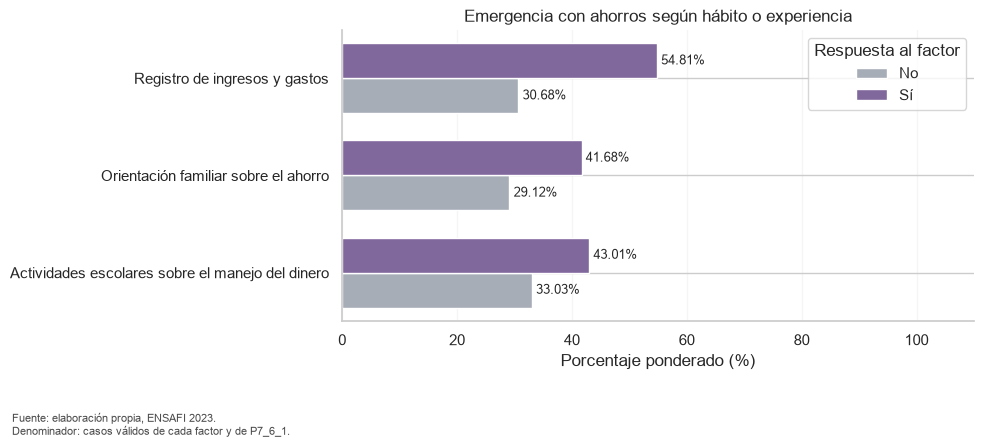

In [49]:
p2_morado, p2_verde, p2_gris = '#80679C', '#4F827B', '#A7ADB7'
p2_colores_ordinales = ['#517C79', '#87A9A0', '#C4C2C9', '#B397C0', '#795E91']

def p2_finalizar(fig, ax, nombre_archivo, nota, margen=0.12):
    ax.set_axisbelow(True)
    ax.grid(axis='x', alpha=0.18)
    for lado in ('top', 'right'):
        ax.spines[lado].set_visible(False)
    fig.text(0.02, 0.015, 'Fuente: elaboración propia, ENSAFI 2023.\n' + nota,
             fontsize=8, color='#4A4A4A')
    fig.tight_layout(rect=[0, margen, 1, 1])
    fig.savefig(p2_salidas / f'{nombre_archivo}.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def p2_barras(tabla, columna, valor, titulo, archivo, nota, color=None):
    fig, ax = plt.subplots(figsize=(9, max(3.4, .5 * len(tabla) + 1.8)))
    cont = ax.barh(tabla[columna], tabla[valor], color=color if color is not None else p2_morado)
    ax.invert_yaxis()
    ax.set_xlim(0, 110)
    ax.set_xlabel('Porcentaje ponderado (%)')
    ax.set_title(titulo)
    ax.bar_label(cont, fmt='%.2f%%', padding=4, fontsize=9)
    p2_finalizar(fig, ax, archivo, nota)

# Figura 1. Relación principal: emergencia con ahorros.
fig, ax = plt.subplots(figsize=(10, 4.5))
p2_pos = np.arange(len(p2_resumen_relaciones))
p2_ancho = 0.36
for delta, col, texto, color in [
    (p2_ancho / 2, 'No (%)', 'No', p2_gris),
    (-p2_ancho / 2, 'Sí (%)', 'Sí', p2_morado)
]:
    cont = ax.barh(p2_pos + delta, p2_resumen_relaciones[col], p2_ancho,
                   label=texto, color=color)
    ax.bar_label(cont, fmt='%.2f%%', padding=3, fontsize=9)
ax.set_yticks(p2_pos, p2_resumen_relaciones['Factor'])
ax.invert_yaxis()
ax.set_xlim(0, 110)
ax.set_xlabel('Porcentaje ponderado (%)')
ax.set_title('Emergencia con ahorros según hábito o experiencia')
ax.legend(title='Respuesta al factor')
p2_finalizar(fig, ax, 'p2_01_emergencia_habitos', 'Denominador: casos válidos de cada factor y de P7_6_1.')

**Interpretación — Figura 1. Emergencias según hábito o experiencia.**

La gráfica facilita comparar la magnitud de las asociaciones descritas en la tabla anterior: el registro de ingresos y gastos presenta la mayor distancia entre quienes respondieron «Sí» y «No», seguido de la orientación familiar y de las actividades escolares. Las barras muestran **porcentajes ponderados entre respuestas válidas**, no relaciones causales.

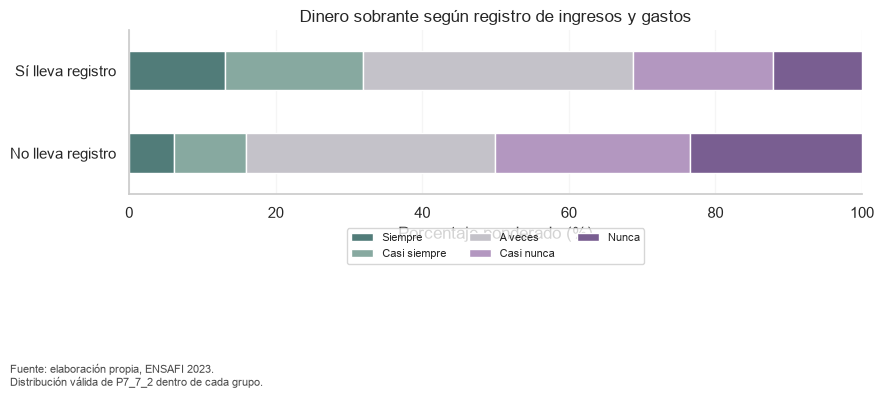

In [50]:
# Figuras 2 y 3. Excedentes habituales y ahorro efectivo del último mes.
fig, ax = plt.subplots(figsize=(9, 4))
p2_tabla_sobrante_registro.plot.barh(stacked=True, color=p2_colores_ordinales,
                                    ax=ax, width=0.48)
ax.set_xlim(0, 100)
ax.set_xlabel('Porcentaje ponderado (%)')
ax.set_title('Dinero sobrante según registro de ingresos y gastos')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8)
p2_finalizar(fig, ax, 'p2_02_sobrante_registro', 'Distribución válida de P7_7_2 dentro de cada grupo.', margen=0.21)



**Interpretación — Figura 2. Dinero sobrante y registro de ingresos y gastos.**

La distribución permite apreciar que la frecuencia de dinero sobrante es mayor entre quienes llevan registro. Sin embargo, que sobre dinero al final del mes **no implica que se haya ahorrado**. La figura describe un comportamiento declarado y no permite identificar a qué se destinó el excedente.

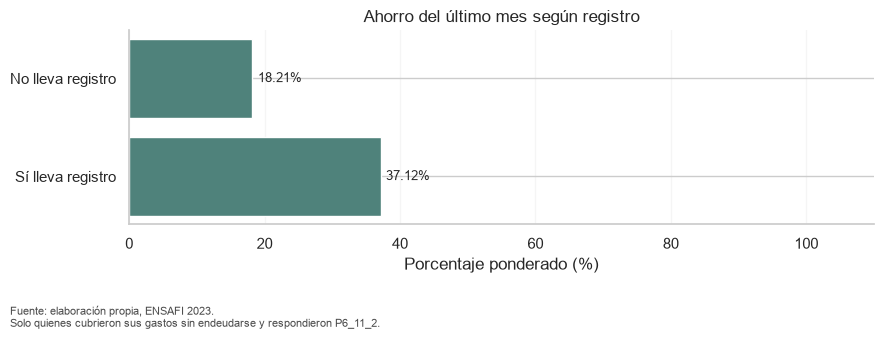

In [51]:
p2_barras(p2_tabla_ahorro_mes.reset_index(), 'index', 'Ahorró o aumentó sus ahorros (%)',
          'Ahorro del último mes según registro', 'p2_03_ahorro_mes',
          'Solo quienes cubrieron sus gastos sin endeudarse y respondieron P6_11_2.', p2_verde)

**Interpretación — Figura 3. Ahorro en el último mes.**

La proporción de personas que declaró haber ahorrado o aumentado sus ahorros es mayor entre quienes llevan registro. A diferencia de la figura anterior, aquí la variable se refiere al **ahorro reciente declarado**, pero solo entre quienes pudieron cubrir sus gastos sin endeudarse y respondieron la pregunta correspondiente.

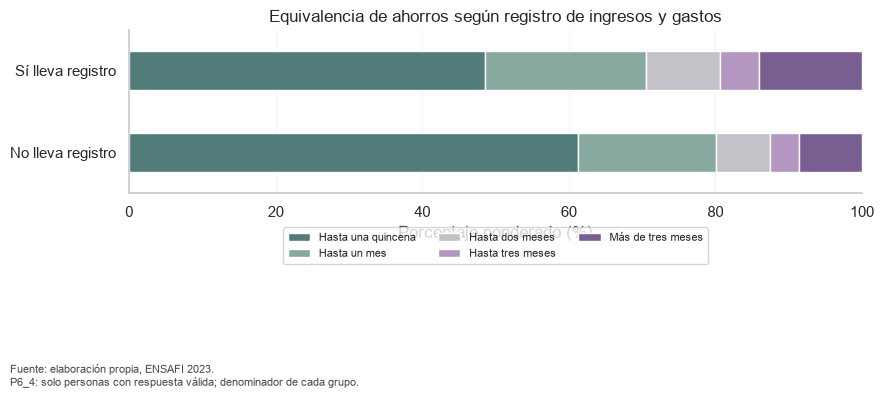

In [52]:
# Figuras 4 y 5. Preguntas complementarias.
fig, ax = plt.subplots(figsize=(9, 4))
p2_tabla_nivel.plot.barh(stacked=True, color=p2_colores_ordinales, ax=ax, width=0.48)
ax.set_xlim(0, 100)
ax.set_xlabel('Porcentaje ponderado (%)')
ax.set_title('Equivalencia de ahorros según registro de ingresos y gastos')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, fontsize=8)
p2_finalizar(fig, ax, 'p2_04_equivalencia_ahorro',
             'P6_4: solo personas con respuesta válida; denominador de cada grupo.', margen=0.21)



**Interpretación — Figura 4. Equivalencia del ahorro según registro.**

La gráfica presenta la distribución de la equivalencia de los ahorros en ingresos entre quienes llevan y no llevan registro. La mayor proporción de ahorros superiores a tres meses para el grupo con registro es una comparación **entre respuestas válidas**: más adelante se evalúa su sensibilidad a quienes contestaron «No sabe».

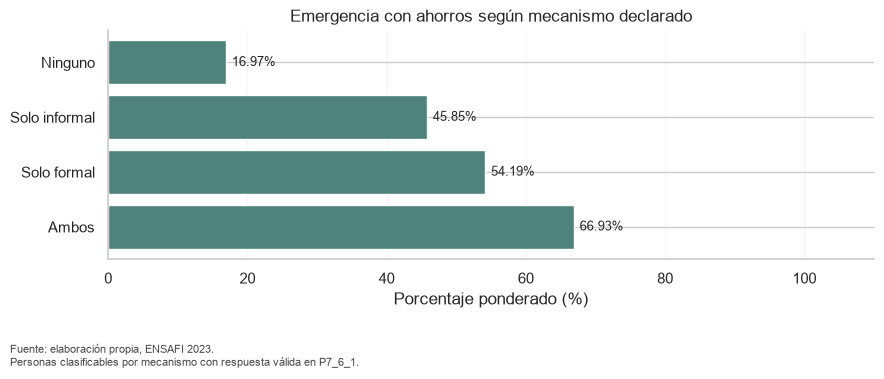

In [53]:
p2_barras(p2_tabla_mecanismos.reset_index(), 'mecanismo', 'Sí puede cubrirla (%)',
          'Emergencia con ahorros según mecanismo declarado', 'p2_05_mecanismos_ahorro',
          'Personas clasificables por mecanismo con respuesta válida en P7_6_1.', p2_verde)

**Interpretación — Figura 5. Emergencias según mecanismos de ahorro.**

La figura muestra un gradiente descriptivo: las personas que utilizan ambos mecanismos presentan el porcentaje más elevado de capacidad declarada para afrontar emergencias, seguidas por quienes usan solo mecanismos formales y solo informales. No permite concluir que utilizar alguno de esos mecanismos produzca directamente una mejor capacidad de ahorro.

## 5. Inferencia estadística y análisis de sensibilidad

### 5.1 Diferencias de proporciones con diseño complejo

La ENSAFI utiliza estratos y conglomerados; por eso **no** se aplican pruebas de dos proporciones para muestreo aleatorio simple. Estimamos la diferencia entre proporciones ponderadas con **linealización de Taylor** (conglomerados últimos), utilizando `FAC_ELE`, `EST_DIS` y `UPM_DIS`.

La función trabaja sobre **toda la base**, asignando contribución cero a las observaciones fuera de cada dominio; así no se eliminan UPM o estratos al formar subgrupos. El intervalo de confianza es individual al 95% y emplea grados de libertad del diseño (número de UPM menos número de estratos). La aproximación no incluye corrección por población finita ni sustituye una reproducción exacta del procedimiento oficial.

Se planifican **siete contrastes**: tres asociaciones principales, uno sobre ahorros superiores a tres meses y tres diferencias de mecanismos respecto a «Solo informal». Para controlar la multiplicidad se usa **Holm** sobre los siete valores p; los intervalos mostrados **no son simultáneos**.

In [54]:
def p2_comparar_diseno(datos, grupo_referencia, grupo_comparacion, resultado, nombre):
    w = pd.to_numeric(datos['FAC_ELE'], errors='coerce').astype(float)
    y = pd.to_numeric(resultado, errors='coerce').astype(float)
    g0 = grupo_referencia.fillna(False).astype(bool) & y.isin([0, 1])
    g1 = grupo_comparacion.fillna(False).astype(bool) & y.isin([0, 1])
    if (g0 & g1).any():
        raise ValueError(f'{nombre}: los grupos no son excluyentes.')
    w0, w1 = w[g0].sum(), w[g1].sum()
    if min(w0, w1) <= 0:
        raise ValueError(f'{nombre}: existe un grupo sin respuestas válidas.')
    p0 = (w[g0] * y[g0]).sum() / w0
    p1 = (w[g1] * y[g1]).sum() / w1
    dif = p1 - p0

    # Todas las unidades del diseño se conservan; fuera del dominio contribuyen cero.
    lineal = datos[['EST_DIS', 'UPM_DIS']].copy()
    lineal['valor'] = (
        np.where(g1, w * (y - p1) / w1, 0.) -
        np.where(g0, w * (y - p0) / w0, 0.)
    )
    psu = lineal.groupby(['EST_DIS', 'UPM_DIS'], observed=True)['valor'].sum().reset_index()
    n = psu.groupby('EST_DIS')['UPM_DIS'].transform('size')
    if (n < 2).any():
        raise ValueError('Hay estratos con una sola UPM: revisar el diseño muestral.')
    medias = psu.groupby('EST_DIS')['valor'].transform('mean')
    varianza = (n / (n - 1) * (psu['valor'] - medias) ** 2).sum()
    ee = np.sqrt(varianza)
    gl = len(psu) - psu['EST_DIS'].nunique()
    if gl <= 0:
        raise ValueError('Los grados de libertad del diseño deben ser positivos.')
    t_critico = stats.t.ppf(0.975, gl)
    p = 2 * stats.t.sf(abs(dif / ee), gl) if ee > 0 else np.nan
    return {
        'Comparación': nombre,
        'n referencia': int(g0.sum()), 'n comparación': int(g1.sum()),
        'Referencia (%)': 100 * p0, 'Comparación (%)': 100 * p1,
        'Diferencia (pp)': 100 * dif, 'Error estándar (pp)': 100 * ee,
        'IC inferior': 100 * (dif - t_critico * ee),
        'IC superior': 100 * (dif + t_critico * ee),
        'Valor p': p, 'gl': int(gl)
    }

p2_resultados_principales = pd.DataFrame([
    p2_comparar_diseno(
        p2_datos, p2_datos[c].eq(0), p2_datos[c].eq(1),
        p2_datos['emergencia_con_ahorros'], etiqueta
    ) for c, etiqueta in p2_factores.items()
])

p2_nivel_valido = p2_datos['P6_4'].isin([1, 2, 3, 4, 5])
p2_contrastes_extra = [p2_comparar_diseno(
    p2_datos,
    p2_nivel_valido & p2_datos['registro_gastos'].eq(0),
    p2_nivel_valido & p2_datos['registro_gastos'].eq(1),
    p2_datos['P6_4'].eq(5).astype(float),
    'Registro: ahorros mayores a tres meses'
)]
for p2_otro in ['Solo formal', 'Ambos', 'Ninguno']:
    p2_contrastes_extra.append(p2_comparar_diseno(
        p2_datos,
        p2_datos['mecanismo'].eq('Solo informal'),
        p2_datos['mecanismo'].eq(p2_otro),
        p2_datos['emergencia_con_ahorros'],
        f'{p2_otro} vs. Solo informal'
    ))
p2_resultados_complementarios = pd.DataFrame(p2_contrastes_extra)
p2_resultados_totales = pd.concat([
    p2_resultados_principales.assign(Análisis='Principal'),
    p2_resultados_complementarios.assign(Análisis='Complementario')
], ignore_index=True)

# Holm para la familia predefinida de siete pruebas.
p2_p = p2_resultados_totales['Valor p'].to_numpy(dtype=float)
p2_validos_p = np.flatnonzero(np.isfinite(p2_p))
p2_orden_p = p2_validos_p[np.argsort(p2_p[p2_validos_p])]
p2_ajustados = np.full(len(p2_p), np.nan)
if len(p2_orden_p):
    p2_ajustados[p2_orden_p] = np.minimum(
        1., np.maximum.accumulate((len(p2_p) - np.arange(len(p2_orden_p))) * p2_p[p2_orden_p])
    )
p2_resultados_totales['Valor p Holm'] = p2_ajustados
p2_resultados_totales['Significativa (5%, Holm)'] = np.where(
    np.isnan(p2_ajustados), 'No evaluable', np.where(p2_ajustados < 0.05, 'Sí', 'No')
)
print('Siete contrastes con corrección de Holm:')
display(p2_resultados_totales.round(4))
p2_resultados_totales.to_csv(p2_salidas / 'p2_inferencia.csv', index=False, encoding='utf-8-sig')

Siete contrastes con corrección de Holm:


,Comparación,n referencia,n comparación,Referencia (%),Comparación (%),Diferencia (pp),Error estándar (pp),IC inferior,IC superior,Valor p,gl,Análisis,Valor p Holm,"Significativa (5%, Holm)"
0,Registro de ingresos y gastos,16041,4407,30.68,54.81,24.13,1.46,21.26,27.00,0.00,2638,Principal,0.00,Sí
1,Orientación familiar sobre el ahorro,9485,10760,29.12,41.68,12.55,1.03,10.53,14.58,0.00,2638,Principal,0.00,Sí
2,Actividades escolares sobre el manejo del dinero,13844,6162,33.03,43.01,9.98,1.18,7.67,12.29,0.00,2638,Principal,0.00,Sí
3,Registro: ahorros mayores a tres meses,5978,2581,8.60,13.99,5.39,1.18,3.07,7.71,0.00,2638,Complementario,0.00,Sí
4,Solo formal vs. Solo informal,5651,1958,45.85,54.19,8.35,2.42,3.60,13.10,0.00,2638,Complementario,0.00,Sí
5,Ambos vs. Solo informal,5651,3123,45.85,66.93,21.08,1.76,17.63,24.54,0.00,2638,Complementario,0.00,Sí
6,Ninguno vs. Solo informal,5651,9716,45.85,16.97,-28.87,1.22,-31.26,-26.48,0.00,2638,Complementario,0.00,Sí


**Interpretación — Tabla de inferencia y ajuste de Holm.**

Los intervalos individuales permiten valorar la dirección y precisión de cada diferencia. Más adelante revisaremos la significancia ajustada por pruebas múltiples de las comparaciones principales y complementarias en conjunto.

La significancia se determina a partir del valor p ajustado por Holm; los intervalos individuales muestran la precisión de las estimaciones y no necesariamente coinciden con esa decisión.

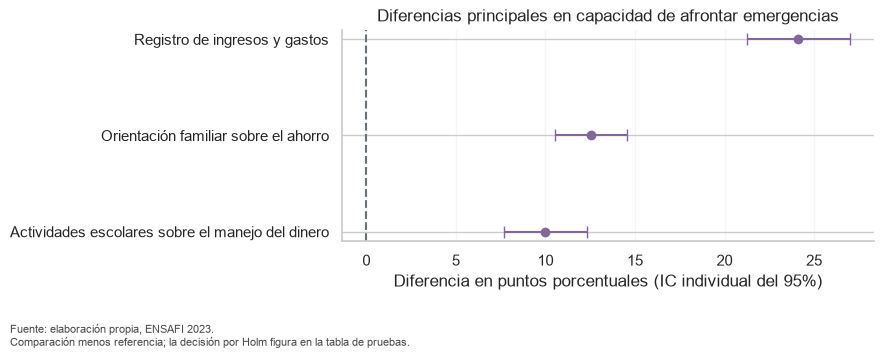

In [55]:
# Figura 6. Intervalos individuales del 95% (se indica que Holm se evalúa en la tabla).
def p2_grafica_ic(tabla, titulo, nombre):
    fig, ax = plt.subplots(figsize=(9, max(3.4, 0.7 * len(tabla) + 1.5)))
    centro = tabla['Diferencia (pp)'].to_numpy()
    inferior = tabla['IC inferior'].to_numpy()
    superior = tabla['IC superior'].to_numpy()
    ax.errorbar(centro, tabla['Comparación'],
                xerr=[centro - inferior, superior - centro],
                fmt='o', color=p2_morado, ecolor=p2_morado, capsize=4, markersize=6)
    ax.axvline(0, color='#69717A', linestyle='--')
    ax.invert_yaxis()
    ax.set_xlabel('Diferencia en puntos porcentuales (IC individual del 95%)')
    ax.set_title(titulo)
    p2_finalizar(fig, ax, nombre,
                'Comparación menos referencia; la decisión por Holm figura en la tabla de pruebas.')

p2_grafica_ic(p2_resultados_principales, 'Diferencias principales en capacidad de afrontar emergencias',
              'p2_06_ic_principales')


**Interpretación — Figura 6. Diferencias e intervalos de confianza de las asociaciones principales.**

La línea vertical en cero representa ausencia de diferencia. La distancia a cero permite comparar magnitudes, mientras que la longitud del intervalo refleja la incertidumbre muestral.

Las diferencias favorecen, en los tres casos, a quienes reportaron el hábito o la experiencia. Los intervalos representados son **individuales**: para establecer la significancia estadística de las siete pruebas en conjunto, se consulta la columna de valores **p ajustados por Holm** de la tabla anterior.

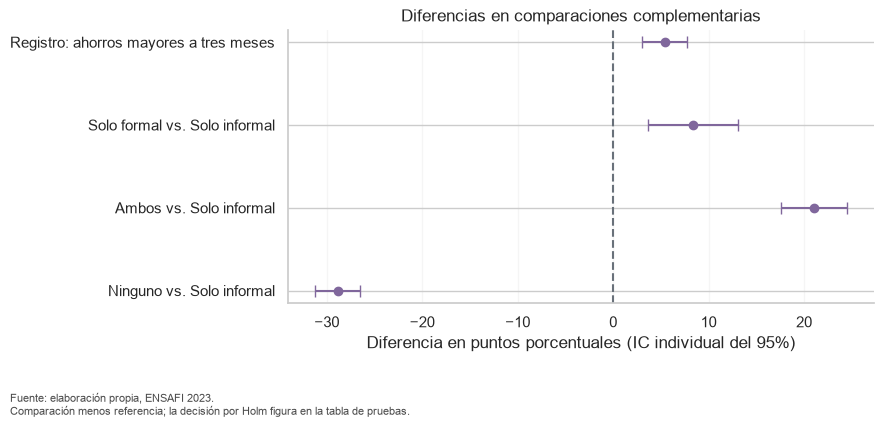

In [56]:
p2_grafica_ic(p2_resultados_complementarios, 'Diferencias en comparaciones complementarias',
              'p2_07_ic_complementarias')

**Interpretación — Figura 7. Contrastes complementarios.**

Las diferencias se calculan en puntos porcentuales respecto al grupo de referencia de cada contraste. Los intervalos reflejan incertidumbre muestral, pero **no son simultáneos** ni representan escenarios de no respuesta. La comparación del ahorro superior a tres meses, aunque significativa entre respuestas válidas, requiere especial cautela por el porcentaje de respuestas «No sabe».

### 5.2 Sensibilidad a respuestas «No sabe» y «No recuerda»

Para `P6_4` se calculan **límites extremos**: suponemos alternativamente que todas las respuestas desconocidas de cada grupo están por debajo o por encima de tres meses de ahorro. También examinamos las respuestas «No recuerda» en las variables familiares y escolares mediante asignaciones extremas de categoría. Estos límites **no son intervalos de confianza** ni suponen que las asignaciones sean realistas; sirven para evaluar cuánto podría variar la dirección de una comparación sin información adicional sobre quienes no respondieron.

In [57]:
p2_filas_sens_monto = []
for p2_g in (0, 1):
    p2_sub = p2_datos[
        p2_datos['P6_4_aplica'] & p2_datos['registro_gastos'].eq(p2_g)
    ]
    p2_w = p2_sub['FAC_ELE']
    p2_total = p2_w.sum()
    p2_desconocido = p2_sub['P6_4'].isna()
    p2_exito = p2_sub['P6_4'].eq(5)
    p2_filas_sens_monto.append({
        'Registro': 'Sí' if p2_g else 'No', 'n aplica': len(p2_sub),
        'n desconocidas': int(p2_desconocido.sum()),
        'Desconocidas ponderadas (%)': 100 * p2_w[p2_desconocido].sum() / p2_total,
        'Casos válidos (%)': 100 * p2_w[p2_exito].sum() / p2_w[~p2_desconocido].sum(),
        'Mínimo (%)': 100 * p2_w[p2_exito].sum() / p2_total,
        'Máximo (%)': 100 * p2_w[p2_exito | p2_desconocido].sum() / p2_total
    })
p2_sensibilidad_monto = pd.DataFrame(p2_filas_sens_monto)
p2_a, p2_b = p2_sensibilidad_monto.iloc[0], p2_sensibilidad_monto.iloc[1]
p2_limite_inferior = p2_b['Mínimo (%)'] - p2_a['Máximo (%)']
p2_limite_superior = p2_b['Máximo (%)'] - p2_a['Mínimo (%)']
print('Sensibilidad de P6_4 según registro:')
display(p2_sensibilidad_monto.round(2))
print(f'Diferencia entre respuestas válidas: {p2_b["Casos válidos (%)"] - p2_a["Casos válidos (%)"]:.2f} pp')
print(f'Límites extremos de la diferencia: {p2_limite_inferior:.2f} a {p2_limite_superior:.2f} pp')



Sensibilidad de P6_4 según registro:


,Registro,n aplica,n desconocidas,Desconocidas ponderadas (%),Casos válidos (%),Mínimo (%),Máximo (%)
0,No,7634,1656,19.12,8.60,6.96,26.08
1,Sí,3098,517,14.94,13.99,11.90,26.84


Diferencia entre respuestas válidas: 5.39 pp
Límites extremos de la diferencia: -14.18 a 19.89 pp


**Interpretación — Sensibilidad de `P6_4` a las respuestas desconocidas.**

Fragilidad en P6_4 (Monto de ahorro según registro): Con los casos válidos, llevar registro muestra una ventaja de +5.39 puntos porcentuales (13.99% vs. 8.60%). Sin embargo, como la no respuesta es alta (19.12% y 14.94%), al considerar escenarios extremos esa diferencia puede ir desde -14.18 pp hasta +19.89 pp. Como el rango cruza el cero, no se puede asegurar que quienes llevan registro tengan mayor nivel de ahorro en P6_4 sin asumir cómo habrían respondido quienes no pudieron proporcionar una respuesta válida.

In [58]:
p2_filas_recuerdo = []
p2_y = p2_datos['emergencia_con_ahorros']
p2_peso = p2_datos['FAC_ELE']

def p2_diferencia_faltantes(x):
    validos = p2_y.isin([0, 1])
    g0, g1 = x.eq(0) & validos, x.eq(1) & validos
    return 100 * ((p2_peso[g1] * p2_y[g1]).sum() / p2_peso[g1].sum() -
                  (p2_peso[g0] * p2_y[g0]).sum() / p2_peso[g0].sum())

for p2_factor in ('orientacion_ahorro', 'educacion_escolar'):
    p2_x = p2_datos[p2_factor]
    p2_mascara = p2_x.isna() & p2_y.isin([0, 1])
    p2_minimo = p2_x.copy()
    p2_maximo = p2_x.copy()
    p2_minimo.loc[p2_mascara] = 1 - p2_y[p2_mascara]
    p2_maximo.loc[p2_mascara] = p2_y[p2_mascara]
    p2_filas_recuerdo.append({
        'Factor': p2_etiquetas[p2_factor],
        'Casos válidos (pp)': p2_diferencia_faltantes(p2_x),
        'Mínimo (pp)': p2_diferencia_faltantes(p2_minimo),
        'Máximo (pp)': p2_diferencia_faltantes(p2_maximo)
    })
p2_sensibilidad_recuerdo = pd.DataFrame(p2_filas_recuerdo)
print('Sensibilidad de las experiencias educativas/familiares:')
display(p2_sensibilidad_recuerdo.round(2))
p2_sensibilidad_monto.to_csv(p2_salidas / 'p2_sensibilidad_monto.csv', index=False, encoding='utf-8-sig')
p2_sensibilidad_recuerdo.to_csv(p2_salidas / 'p2_sensibilidad_recuerdo.csv', index=False, encoding='utf-8-sig')

Sensibilidad de las experiencias educativas/familiares:


,Factor,Casos válidos (pp),Mínimo (pp),Máximo (pp)
0,Orientación familiar sobre ahorro,12.55,11.73,13.18
1,Actividades escolares sobre dinero,9.98,7.48,12.03


**Interpretación — Sensibilidad de las experiencias familiares y escolares.**

Solidez en los factores formativos (P7_12_2 y P7_12_3): En cambio, la diferencia asociada con la orientación familiar (+12.55 pp, rango de 11.73 a 13.18 pp) y las actividades escolares (+9.98 pp, rango de 7.48 a 12.03 pp) conserva la dirección bajo estos escenarios extremos: incluso bajo los peores escenarios de no respuesta, la diferencia sigue siendo positiva y nunca cruza el cero.

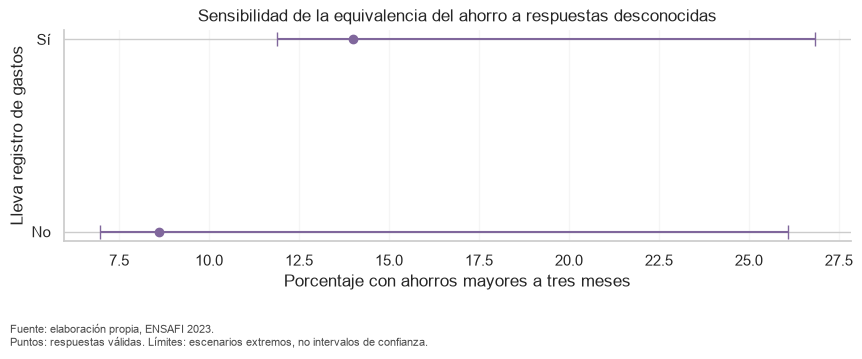

In [59]:
# Figura 8. Los segmentos representan escenarios extremos, NO IC del 95%.
fig, ax = plt.subplots(figsize=(8.8, 3.6))
p2_centro = p2_sensibilidad_monto['Casos válidos (%)'].to_numpy()
p2_min = p2_sensibilidad_monto['Mínimo (%)'].to_numpy()
p2_max = p2_sensibilidad_monto['Máximo (%)'].to_numpy()
ax.errorbar(p2_centro, p2_sensibilidad_monto['Registro'],
            xerr=[p2_centro - p2_min, p2_max - p2_centro],
            fmt='o', color=p2_morado, capsize=5)
ax.set_xlabel('Porcentaje con ahorros mayores a tres meses')
ax.set_ylabel('Lleva registro de gastos')
ax.set_title('Sensibilidad de la equivalencia del ahorro a respuestas desconocidas')
p2_finalizar(fig, ax, 'p2_08_sensibilidad_monto',
             'Puntos: respuestas válidas. Límites: escenarios extremos, no intervalos de confianza.')

**Interpretación — Figura 8. Escenarios extremos de respuestas «No sabe».**

El punto identifica la proporción observada entre respuestas válidas y cada segmento representa los valores mínimo y máximo que resultarían de asignaciones extremas a respuestas desconocidas. **No son intervalos de confianza.** El hecho de que los límites de la diferencia entre grupos incluyan cero indica que la ventaja observada no conserva necesariamente su dirección ante todos los escenarios de no respuesta.

## 6. Interpretación de resultados y conclusiones

### 6.1 Relación entre hábitos, experiencias educativas y capacidad de ahorro

Con los microdatos de **20 448 personas entrevistadas** en `TMODULO` se observan asociaciones positivas entre determinadas prácticas y experiencias de educación financiera y la capacidad **declarada** para afrontar una emergencia económica mediante ahorros. Todos los porcentajes siguientes están ponderados por `FAC_ELE` y se calculan entre las personas con respuestas válidas para cada comparación.

Quienes llevan un **registro de ingresos y gastos** declararon poder enfrentar la emergencia en un **54.81 %**, frente al **30.68 %** de quienes no llevan registro: una diferencia de **24.13 puntos porcentuales**. Entre quienes recibieron **orientación familiar sobre el ahorro**, la proporción fue **41.68 %**, frente al **29.12 %** de quienes no la reportaron (**12.55 puntos** de diferencia). Para quienes participaron en **actividades escolares sobre manejo del dinero**, las cifras fueron **43.01 %** y **33.03 %**, respectivamente (**9.98 puntos** de diferencia).

Las tres comparaciones presentan evidencia estadística de diferencia una vez aplicado el ajuste de Holm a la familia de siete contrastes analizados. No obstante, la significancia estadística **no demuestra causalidad**: estos grupos pueden diferir también en ingresos, edad, escolaridad y otras características no controladas.

### 6.2 Equivalencia de los ahorros y mecanismos utilizados

Entre las personas que **declararon algún ahorro** y proporcionaron una respuesta válida sobre su equivalencia en ingresos, el **13.99 %** de quienes registran sus ingresos y gastos declararon ahorros superiores a tres meses de ingresos, frente al **8.60 %** de quienes no llevan registro. La diferencia es **5.39 puntos porcentuales** y también supera el criterio de significancia basado en los valores p ajustados por Holm.

Sin embargo, el análisis de sensibilidad merece especial atención: el **19.12 %** del peso del grupo sin registro y el **14.94 %** del grupo con registro corresponde a respuestas desconocidas en `P6_4`. Bajo escenarios extremos compatibles con esos faltantes, la diferencia podría variar entre **−14.18 y 19.89 puntos porcentuales**. Por tanto, **la dirección observada de este resultado no es robusta a todas las asignaciones posibles de «No sabe»**.

En la comparación de mecanismos de ahorro, el **54.19 %** de quienes utilizan **solo mecanismos formales** declararon poder afrontar la emergencia, frente al **45.85 %** de quienes utilizan **solo mecanismos informales**: una diferencia de **8.35 puntos porcentuales**. Entre quienes usan ambos mecanismos, la proporción fue **66.93 %**; entre quienes no declararon ahorro formal ni informal, fue **16.97 %**. Estas cifras describen grupos diferentes y no prueban que cambiar de mecanismo, por sí mismo, produzca esas diferencias.

### 6.3 Alcances y limitaciones

- La ENSAFI 2023 es una encuesta transversal y de respuestas declaradas; **no permite establecer relaciones causales**.
- El análisis no ajusta por ingreso, edad, escolaridad u otras covariables potencialmente asociadas con los hábitos y los resultados.
- `P7_6_1` mide una **capacidad declarada** para enfrentar una emergencia, no la comprobación de saldos de ahorro.
- `P6_4` solo se pregunta a personas con ahorro declarado; `P6_11_2` solo a personas que pudieron cubrir sus gastos sin endeudarse. Por ello, no deben extenderse sus porcentajes al total de informantes.
- Los códigos «No sabe» y «No recuerda» no se transformaron en negativas. Los escenarios extremos muestran sensibilidad a la ausencia de respuesta, pero no sustituyen una modelación de datos faltantes.
- Las desviaciones estándar se estiman mediante una **aproximación de linealización de Taylor** para estratos y conglomerados. Los intervalos del 95 % que se muestran son **individuales** y la decisión de significancia múltiple depende de los **valores p ajustados por Holm**.

### 6.4 Resumen reproducible

La siguiente celda vuelve a imprimir los porcentajes, contrastes y escenarios de sensibilidad desde las **tablas calculadas**, para que sea posible verificarlos al ejecutar el notebook con los microdatos originales.


In [60]:
print('ASOCIACIONES PRINCIPALES')
for _, p2_fila in p2_resumen_relaciones.iterrows():
    print(f'- {p2_fila["Factor"]}: {p2_fila["Sí (%)"]:.2f}% frente a '
          f'{p2_fila["No (%)"]:.2f}%; diferencia = {p2_fila["Diferencia (pp)"]:+.2f} pp.')

print('\nCONTRASTES CON AJUSTE DE HOLM')
for _, p2_fila in p2_resultados_totales.iterrows():
    print(f'- {p2_fila["Comparación"]}: {p2_fila["Diferencia (pp)"]:+.2f} pp; '
          f'IC individual 95% [{p2_fila["IC inferior"]:.2f}, {p2_fila["IC superior"]:.2f}]; '
          f'p Holm = {p2_fila["Valor p Holm"]:.4g}; '
          f'significativa = {p2_fila["Significativa (5%, Holm)"]}.')

print('\nSENSIBILIDAD')
print(f'- Equivalencia del ahorro según registro: límites extremos de la diferencia '
      f'[{p2_limite_inferior:.2f}, {p2_limite_superior:.2f}] pp.')
for _, p2_fila in p2_sensibilidad_recuerdo.iterrows():
    print(f'- {p2_fila["Factor"]}: estimación con respuestas válidas '
          f'{p2_fila["Casos válidos (pp)"]:+.2f} pp; '
          f'límites extremos [{p2_fila["Mínimo (pp)"]:.2f}, {p2_fila["Máximo (pp)"]:.2f}] pp.')
print('\nInterpretación: asociaciones estadísticas; no constituyen evidencia causal.')

ASOCIACIONES PRINCIPALES
- Registro de ingresos y gastos: 54.81% frente a 30.68%; diferencia = +24.13 pp.
- Orientación familiar sobre el ahorro: 41.68% frente a 29.12%; diferencia = +12.55 pp.
- Actividades escolares sobre el manejo del dinero: 43.01% frente a 33.03%; diferencia = +9.98 pp.

CONTRASTES CON AJUSTE DE HOLM
- Registro de ingresos y gastos: +24.13 pp; IC individual 95% [21.26, 27.00]; p Holm = 2.02e-57; significativa = Sí.
- Orientación familiar sobre el ahorro: +12.55 pp; IC individual 95% [10.53, 14.58]; p Holm = 1.741e-32; significativa = Sí.
- Actividades escolares sobre el manejo del dinero: +9.98 pp; IC individual 95% [7.67, 12.29]; p Holm = 1.271e-16; significativa = Sí.
- Registro: ahorros mayores a tres meses: +5.39 pp; IC individual 95% [3.07, 7.71]; p Holm = 1.08e-05; significativa = Sí.
- Solo formal vs. Solo informal: +8.35 pp; IC individual 95% [3.60, 13.10]; p Holm = 0.0005797; significativa = Sí.
- Ambos vs. Solo informal: +21.08 pp; IC individual 95% [17.

# **Pregunta 3. Bienestar Financiero y Tenencia de Vivienda**
## 1. Planteamiento y diseño del análisis

### 1.1 Pregunta de investigación

> **Entre la población adulta en México en 2023 determinar: ¿impacta el estatus de tenencia de la vivienda (propia pagada, hipotecada, rentada o prestada) en el índice global de bienestar financiero del hogar?.**

*En este estudio, el **bienestar financiero** se analiza mediante el indicador ordinal `NIV_BIENES` (escala de `1` a `4`, donde `1` representa el nivel más bajo y `4` el más alto), construido oficialmente por el INEGI a partir de la escala de salud y seguridad financiera percibida por las personas adultas.*

---

### 1.2 Objetivo del análisis

Se emplean los datos de la **Encuesta Nacional sobre Salud Financiera (ENSAFI 2023)** del INEGI ([documentación oficial](https://www.inegi.org.mx/programas/ensafi/2023/#documentacion)) para evaluar la distribución y tendencia del bienestar financiero (`NIV_BIENES`) entre los distintos esquemas de tenencia habitacional, incorporando el factor de expansión individual (`FAC_ELE`) en todo el análisis. En particular, se comparan cuatro categorías principales definidas a partir de las preguntas `P1_5` y `P1_9`:

- **Propia pagada:** viviendas cuyo propietario reside en ellas y declaró haber liquidado totalmente su compra o financiamiento (`P1_5 = 1` y `P1_9 = 1`).
- **Propia hipotecada:** viviendas propias que actualmente se encuentran en proceso de pago mediante un crédito o préstamo (`P1_5 = 1` y `P1_9 = 2`).
- **Rentada:** viviendas ocupadas bajo un esquema de arrendamiento (`P1_5 = 2`).
- **Prestada:** viviendas cedidas sin cobro de renta por familiares, amistades o terceros (`P1_5 = 3`).

El estudio combina un enfoque **descriptivo** (estadísticas ponderadas y proporciones por nivel de bienestar) con un contraste **inferencial no paramétrico** (prueba de Kruskal-Wallis) para determinar si las diferencias observadas a nivel poblacional son estadísticamente significativas, sin atribuir relaciones causales directas debido a la posible incidencia de factores sociodemográficos no controlados (como edad o etapa del ciclo de vida).

---

### 1.3 Los datos y la unidad de estudio

La ENSAFI 2023 se organiza en cuatro tablas principales que describen desde la vivienda física hasta las respuestas individuales:

| Tabla | Registros | Columnas | ¿Qué contiene? | Llave de unión |
| :--- | :---: | :---: | :--- | :--- |
| **`TMODULO.csv`** | 20,448 | 253 | Entrevista individual sobre salud financiera (adultos de 18 años y más) | `LLAVEVIV` (`UPM`, `VIV_SEL`), `HOGAR`, `N_REN` |
| **`TSDEM.csv`** | 67,781 | 25 | Datos sociodemográficos de todos los integrantes del hogar | `LLAVEVIV`, `HOGAR`, `N_REN` |
| **`THOGAR.csv`** | 20,448 | 55 | Composición y características del hogar | `LLAVEVIV`, `HOGAR` |
| **`TVIVIENDA.csv`** | 20,201 | 36 | Características físicas y estatus de tenencia de la vivienda | `LLAVEVIV` (`UPM`, `VIV_SEL`) |

La unidad de análisis es la **persona adulta seleccionada en cada hogar**. Para vincular las condiciones habitacionales con el bienestar financiero individual, el estudio trabaja exclusivamente con **`TVIVIENDA.csv`** y **`TMODULO.csv`**, cruzándolas mediante un *inner merge* por la clave única de vivienda (`LLAVEVIV`).

---

### 1.4 Utilización de las variables

Para garantizar la trazabilidad y consistencia lógica entre el cuestionario y el procesamiento estadístico, las variables se estructuran de la siguiente manera:

| Concepto en el análisis | Variables INEGI | Cómo se construye en el estudio |
| :--- | :--- | :--- |
| **Estatus de tenencia de la vivienda (`estatus_tenencia`)** | `P1_5`, `P1_9` | Clasifica el régimen habitacional en cuatro grupos objetivo: *Propia pagada* (`P1_5 = 1, P1_9 = 1`), *Propia hipotecada* (`P1_5 = 1, P1_9 = 2`), *Rentada* (`P1_5 = 2`) y *Prestada* (`P1_5 = 3`). Los códigos `9` (*No sabe*) en `P1_9` se recodifican a `NaN`. |
| **Nivel de bienestar financiero** | `NIV_BIENES` | Variable ordinal de `1` (bajo) a `4` (alto) generada por el INEGI.
| **Factor de expansión individual** | `FAC_ELE` | Ponderador muestral utilizado para proyectar las estimaciones a la población adulta representada y generar el remuestreo ponderado. |
| **Factor de expansión de vivienda** | `FAC_ELE` | Ponderador muestral utilizado para proyectar las estimaciones de las viviendas generar el remuestreo ponderado. |
| **Llave de identificación** | `LLAVEVIV` | Identificador único de vivienda física.
| **Variables excluidas o de referencia** | `P7_1`, `P1_9` (saltos), `P1_5` (`4, 5, 9`) | `P7_1` se carga como referencia conceptual de la sección de bienestar, pero se utiliza `NIV_BIENES` para sintetizar la escala oficial completa. Se excluyen viviendas intestadas/litigio (`P1_5 = 4`) debido a que presentan un escenario de incertidumbre legal donde la estructura de propiedad y las obligaciones financieras de la vivienda son ambiguas, otra situación (`P1_5 = 5`) ya que es una categoría residual que agrupa condiciones dispersas y no especificadas por el cuestionario y sin respuesta y viviendas propias sin estatus en `P1_9`. |

El indicador oficial `NIV_BIENES` resume la puntuación obtenida por cada persona en la combinación de reactivos de bienestar financiero de la Sección 7 (basada en la metodología internacional del *Consumer Financial Protection Bureau* adaptada por el INEGI), categorizando el puntaje continuo en cuatro niveles ordinales de bienestar. Véase el [Documento conceptual de la ENSAFI 2023, INEGI](https://www.inegi.org.mx/contenidos/productos/prod_serv/contenidos/espanol/bvinegi/productos/nueva_estruc/889463918196.pdf).

---

### 1.5 Estimación poblacional y enfoque estadístico

Para evitar el sesgo de analizar únicamente la muestra cruda encuestada, todas las métricas descriptivas y proporciones se calculan ponderando cada observación por su factor de expansión **`FAC_ELE`** ($w_i = \text{FAC\_ELE}_i$). La media ponderada ($\hat{\mu}_g$) y la proporción poblacional en cada nivel de bienestar $k \in \{1,2,3,4\}$ ($\hat{P}_{g,k}$) para cada categoría de tenencia $g$ se estiman mediante:

$$
\hat{\mu}_g = \frac{\sum_{i \in g} w_i \, Y_i}{\sum_{i \in g} w_i},
\qquad
\hat{P}_{g,k} = \frac{\sum_{i \in g} w_i \, \mathbb{I}(Y_i = k)}{\sum_{i \in g} w_i},
\qquad
w_i = \text{FAC\_ELE}_i
$$

De manera complementaria, se calcula la **mediana ponderada** (mediante el punto de corte del 50 % del peso acumulado de `FAC_ELE`) y la **desviación estándar ponderada**. Para las visualizaciones de intervalos de confianza (*Pointplot*) y la prueba no paramétrica de **Kruskal-Wallis**, se construye una muestra representativa mediante **remuestreo con reemplazo ponderado** (`df.sample` con probabilidad proporcional a `FAC_ELE` y semilla fija `42`), permitiendo que el contraste de hipótesis refleje la estructura poblacional y no solo los conteos físicos de la encuesta.

In [61]:
from scipy import stats
from IPython.display import Markdown

p3_salidas = Path("salidas") / "pregunta_3"
p3_salidas.mkdir(parents=True, exist_ok=True)

# Columnas a utilziar (variables de interés y llaves para cruces)
cols_vivienda = ['LLAVEVIV', 'P1_5', 'P1_9', 'FAC_VIV']
cols_modulo = ['LLAVEVIV', 'FAC_ELE', 'NIV_BIENES', 'P7_1']

df_vivienda = df_tvivienda[cols_vivienda].copy()
df_modulo = df_tmodulo[cols_modulo].copy()

print(f"Registros en Vivienda: {len(df_vivienda)} | Registros en Módulo: {len(df_modulo)}")

Registros en Vivienda: 20201 | Registros en Módulo: 20448


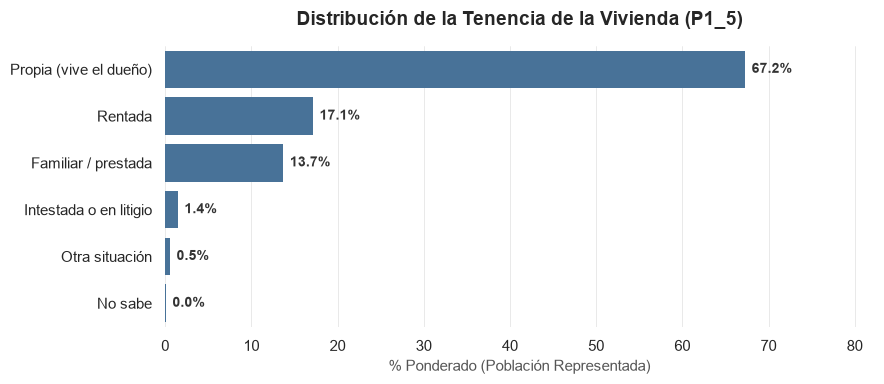

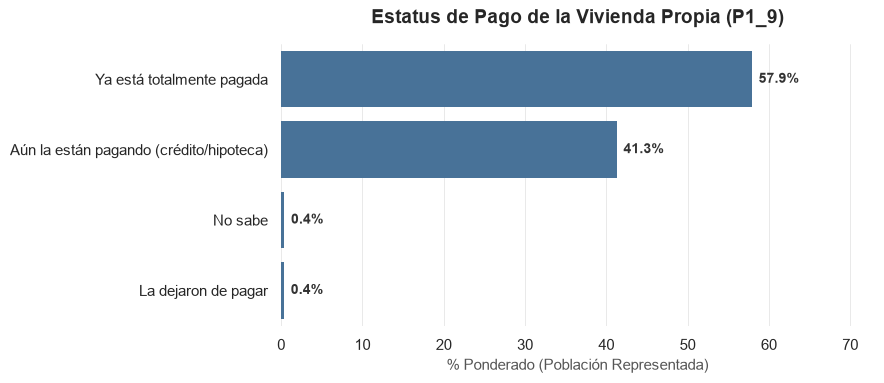

In [62]:
def graficar_distribucion_ponderada(df, col_variable, col_peso, diccionario_etiquetas, titulo):
    df_temp = df[[col_variable, col_peso]].dropna()
    peso_total = df_temp[col_peso].sum()
    pct_ponderado = (df_temp.groupby(col_variable)[col_peso].sum() / peso_total) * 100

    pct_ponderado.index = pct_ponderado.index.map(diccionario_etiquetas)
    pct_ponderado = pct_ponderado.sort_values(ascending=False)

    sns.set_theme(style="whitegrid", rc={"grid.linewidth": 0.5, "grid.color": "#e0e0e0"})
    plt.figure(figsize=(9, 4))

    ax = sns.barplot(x=pct_ponderado.values, y=pct_ponderado.index, color="#3b72a5", edgecolor="none")

    for p in ax.patches:
        width = p.get_width()
        plt.text(width + 0.8, p.get_y() + p.get_height()/2.,
                 f'{width:.1f}%', va='center', ha='left',
                 fontsize=10, color='#333333', fontweight='bold')

    plt.title(titulo, fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('% Ponderado (Población Representada)', fontsize=11, color='#555555')
    plt.ylabel('')
    plt.xlim(0, pct_ponderado.max() + 15)
    sns.despine(left=True, bottom=True)
    plt.tight_layout()
    plt.savefig(p3_salidas / f"p3_distribucion_{col_variable}.png", dpi=150, bbox_inches="tight")
    plt.show()

dicc_p1_5 = {1: "Propia (vive el dueño)", 2: "Rentada", 3: "Familiar / prestada", 4: "Intestada o en litigio", 5: "Otra situación", 9: "No sabe"}
dicc_p1_9 = {1: "Ya está totalmente pagada", 2: "Aún la están pagando (crédito/hipoteca)", 3: "La dejaron de pagar", 9: "No sabe"}

# 2. CORRECCIÓN: Llamamos a la función usando 'df_vivienda' en lugar de 'df_tvivienda'
graficar_distribucion_ponderada(df_vivienda, 'P1_5', 'FAC_VIV', dicc_p1_5, 'Distribución de la Tenencia de la Vivienda (P1_5)')
graficar_distribucion_ponderada(df_vivienda, 'P1_9', 'FAC_VIV', dicc_p1_9, 'Estatus de Pago de la Vivienda Propia (P1_9)')
# =====================================================================

### Conclusiones del Análisis Exploratorio de Tenencia Habitacional

El análisis exploratorio de las distribuciones poblacionales ponderadas (previo a la aplicación de filtros de exclusión) revela tres hallazgos fundamentales:

* **Dominancia de la vivienda propia como esquema principal:** Más de dos terceras partes de la población adulta representada habitan en una vivienda propia (67.2 %). Las alternativas de arrendamiento (17.1 %) y alojamiento prestado por familiares (13.7 %) representan los esquemas secundarios más relevantes. En conjunto, estas tres categorías agrupan al 98 % del panorama habitacional del país.
* **Alta prevalencia de viviendas liquidadas frente a la carga hipotecaria:** Dentro del subconjunto de propietarios a los que les aplicó la pregunta sobre el estatus de su financiamiento, la mayoría reporta habitar una vivienda totalmente pagada (57.9 %). No obstante, una proporción altamente significativa (41.3 %) aún se encuentra pagando un crédito o hipoteca, lo que consolida a este grupo ("Propia hipotecada") como una categoría indispensable para evaluar el impacto de la carga de deuda en el bienestar financiero. La morosidad declarada ("La dejaron de pagar") es poco significativa (0.4 %).
* **Justificación de las exclusiones metodológicas:** Las gráficas confirman que las viviendas en situación de "Intestada o en litigio" (1.4 %) y "Otra situación" (0.5 %) constituyen escenarios poblacionales atípicos y poco significativos. Su exclusión del modelo final no solo es necesaria por la ambigüedad jurídica que representan, sino que además consideramos que no compromete la significancia estadística de la muestra nacional.

In [63]:
# Reemplazar 'No sabe' (9) por NaN para no sesgar los datos
df_vivienda['P1_9'] = df_vivienda['P1_9'].replace({9: np.nan})
df_modulo['NIV_BIENES'] = pd.to_numeric(df_modulo['NIV_BIENES'], errors='coerce')

# Función de recodificación basada en el Cuestionario ENSAFI 2023
def categorizar_tenencia(row):
    p1_5 = row['P1_5']
    p1_9 = row['P1_9']

    if p1_5 == 1:
        if p1_9 == 1: return 'Propia pagada'
        elif p1_9 == 2: return 'Propia hipotecada'
        elif p1_9 == 3: return 'Propia (Dejada de pagar)'
        else: return 'Propia (Estatus desconocido)'
    elif p1_5 == 2: return 'Rentada'
    elif p1_5 == 3: return 'Prestada'
    elif p1_5 == 4: return 'Intestada / Litigio'
    elif p1_5 == 5: return 'Otra situación'
    else: return np.nan

# Aplicamos la función para crear la nueva columna
df_vivienda['estatus_tenencia'] = df_vivienda.apply(categorizar_tenencia, axis=1)

# Vaalidaciones de consistencia y calidad de los datos
display(Markdown("### Calidad de Datos"))

display(Markdown("#### 1. Valores Nulos Iniciales"))

nulos_viv = df_vivienda.isna().sum().to_frame(name='Valores Nulos')
nulos_viv.index.name = 'Tabla Vivienda'
display(nulos_viv.style.format("{:,}"))

nulos_mod = df_modulo.isna().sum().to_frame(name='Valores Nulos')
nulos_mod.index.name = 'Tabla Módulo'
display(nulos_mod.style.format("{:,}"))

print("\nConsistencia de los Datos")

# 1. Duplicados en Llave Primaria
duplicados_viv = df_vivienda.duplicated(subset=['LLAVEVIV']).sum()
duplicados_mod = df_modulo.duplicated(subset=['LLAVEVIV']).sum()
print(f"\n1. DUPLICADOS DE LLAVE:")
print(f"  - Llaves duplicadas en tvivienda: {duplicados_viv}")
print(f"  - Llaves duplicadas en tmodulo: {duplicados_mod}")

# 2. Consistencia Lógica
inconsistencias = df_vivienda[(df_vivienda['P1_5'] != 1) & (df_vivienda['P1_9'].notna())].shape[0]
print(f"\n2. CONSISTENCIA LÓGICA:")
print(f"- Casos que rentan/piden prestado pero tienen estatus de hipoteca: {inconsistencias}")

# 3. Rangos y Factores
print(f"\n3. RANGOS (Valores atípicos en Módulo):")
display(df_modulo[['NIV_BIENES', 'FAC_ELE']].describe().loc[['min', 'max']])

fac_invalidos = (df_modulo['FAC_ELE'] <= 0).sum()
print(f"- Factores de expansión menores o iguales a cero: {fac_invalidos}")

# 4. Tipos de Datos
print(f"\n4. TIPOS DE DATOS:")
print(df_modulo[['NIV_BIENES', 'FAC_ELE']].dtypes)

# 5. Rango de la Variable Objetivo
valores_unicos = sorted(df_modulo['NIV_BIENES'].dropna().unique())
fuera_rango = df_modulo[~df_modulo['NIV_BIENES'].isin([1, 2, 3, 4, np.nan])].shape[0]
print(f"\n5. RANGO DE LA VARIABLE OBJETIVO (NIV_BIENES):")
print(f"- Valores únicos encontrados: {valores_unicos}")
print(f"  - Registros fuera de la escala 1-4: {fuera_rango}")

# Merge de las tablitas y depuración final
df_master = pd.merge(df_modulo, df_vivienda, on='LLAVEVIV', how='inner')
categorias_obj = ['Propia pagada', 'Propia hipotecada', 'Rentada', 'Prestada']
df_clean = df_master[df_master['estatus_tenencia'].isin(categorias_obj)].copy()
df_clean.dropna(subset=['NIV_BIENES', 'FAC_ELE', 'estatus_tenencia'], inplace=True)

# 6. Suficiencia Muestral
display(Markdown("#### 6. Suficiencia muestral por categoría (N Crudo vs N Ponderado)"))
resumen_muestral = df_clean.groupby('estatus_tenencia').agg(
    Muestra_Fisica=('LLAVEVIV', 'count'),
    Poblacion_Representada=('FAC_ELE', 'sum')
).style.format({
    'Muestra_Fisica': '{:,.0f}',
    'Poblacion_Representada': '{:,.0f}'
})

display(resumen_muestral)
print(f"\nRegistros limpios y consolidados listos para análisis: {len(df_clean)}")

### Calidad de Datos

#### 1. Valores Nulos Iniciales

,Valores Nulos
Tabla Vivienda,
LLAVEVIV,0
P1_5,0
P1_9,"15,983"
FAC_VIV,0
estatus_tenencia,12


,Valores Nulos
Tabla Módulo,
LLAVEVIV,0
FAC_ELE,0
NIV_BIENES,0
P7_1,0



Consistencia de los Datos

1. DUPLICADOS DE LLAVE:
  - Llaves duplicadas en tvivienda: 0
  - Llaves duplicadas en tmodulo: 247

2. CONSISTENCIA LÓGICA:
- Casos que rentan/piden prestado pero tienen estatus de hipoteca: 0

3. RANGOS (Valores atípicos en Módulo):


,NIV_BIENES,FAC_ELE
min,1.00,126.00
max,4.00,"364,007.00"


- Factores de expansión menores o iguales a cero: 0

4. TIPOS DE DATOS:
NIV_BIENES    int64
FAC_ELE       int64
dtype: object

5. RANGO DE LA VARIABLE OBJETIVO (NIV_BIENES):
- Valores únicos encontrados: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
  - Registros fuera de la escala 1-4: 0


#### 6. Suficiencia muestral por categoría (N Crudo vs N Ponderado)

,Muestra_Fisica,Poblacion_Representada
estatus_tenencia,,
Prestada,"2,614","10,971,920"
Propia hipotecada,"1,896","8,150,375"
Propia pagada,"2,323","12,097,249"
Rentada,"3,362","13,317,936"



Registros limpios y consolidados listos para análisis: 10195


### Nota Metodológica: Justificación de Desviaciones y Filtros en la limpieza de Datos

Durante la validación de calidad de las tablas `tvivienda` y `tmodulo`, se identificaron cuatro comportamientos que no representan errores en los datos, sino características propias del diseño muestral y del cuestionario de la ENSAFI 2023:

* **Valores nulos en `P1_9` (15,983 registros) y acotamiento de la muestra (10,195 registros finales):** La pregunta `P1_9` (*estatus de pago o deuda de la vivienda*) está sujeta a saltos condicionales dentro del cuestionario. No se aplica a quienes rentan, habitan una vivienda prestada, ni a todos los propietarios por igual (se omite cuando la propiedad no proviene de un esquema de compra/financiamiento, como viviendas heredadas o donadas). Adicionalmente, las respuestas codificadas como `9` (*"No sabe"*) se transformaron a `NaN` para evitar sesgos. Al cruzar la base con el módulo individual y conservar únicamente las cuatro categorías objetivo, se consolidaron **10,195 registros limpios**. Por rigor metodológico, se aclara que los grupos *"Propia pagada"* y *"Propia hipotecada"* representan específicamente a los propietarios que pasaron por el filtro de estatus de pago/deuda (`P1_9`).
* **Valores nulos en `estatus_tenencia` (12 registros):** Aunque la variable origen `P1_5` no presenta celdas vacías, al aplicar la regla de recodificación surgen 12 valores nulos. Esto corresponde a los  que respondieron con el código `9` (*"No sabe"*) respecto a la situación legal de la vivienda, por lo que descartarlos evita imputar categorías de forma arbitraria.
* **Llaves duplicadas en `tmodulo` (247 registros) frente a `tvivienda` (0 registros):** La llave `LLAVEVIV` identifica de manera única a cada vivienda física (`tvivienda`), mientras que `tmodulo` registra entrevistas a nivel individual (una persona adulta seleccionada por cada hogar dentro de la vivienda). Las 247 repeticiones en `tmodulo` corresponden a viviendas donde habitan dos o más hogares independientes y se entrevistó a un adulto por hogar. En consecuencia, el cruce (*inner merge*) por `LLAVEVIV` es  válido, ya que asigna las características físicas de la tenencia a cada persona entrevistada.
* **Integridad completa en `tmodulo` (0 valores nulos):** Las variables críticas del módulo individual (`LLAVEVIV`, `NIV_BIENES`, `FAC_ELE` y `P7_1`) presentan un 100 % de completez desde la fuente original, garantizando que no exista pérdida de información por falta de respuesta en la variable objetivo ni en los factores de expansión.

---

### Conclusiones de Calidad de Datos

* **Limpieza e integridad numérica:** La base de datos está libre de contradicciones lógicas en los filtros del cuestionario (0 inconsistencias) y carece de valores numéricos atípicos. La variable objetivo de bienestar financiero (`NIV_BIENES`) es de tipo entero (`int64`) y está estrictamente acotada a su escala oficial de 1 a 4 (0 registros fuera de rango), mientras que los factores de expansión (`FAC_ELE`, `int64`) son todos positivos y válidos (rango de 126 a 364,007). Excluyendo los recortes deliberados por flujo del cuestionario y selección de categorías, la pérdida de información por falta de respuesta es prácticamente nula (apenas 12 registros sin estatus de tenencia identificable).
* **Alto poder estadístico:** Todas las categorías analizadas superan holgadamente el volumen "mínimo" de observaciones requerido para realizar pruebas de hipótesis no paramétricas válidas; incluso el grupo mças pequeño (*"Propia hipotecada"*) cuenta con una muestra de **1,896 personas** entrevistadas, seguido por *"Propia pagada"* (2,323), *"Prestada"* (2,614) y *"Rentada"* (3,362).
* **Proyección nacional validada:** Esta robustez en la muestra física permite que la aplicación del factor de expansión (`FAC_ELE`) proyecte con alta precisión estadística el panorama de bienestar financiero de aproximadaente 44.5 millones de mexicanos adultos pertenecientes a las cuatro modalidades de vivienda estudiadas.

In [64]:
# Creación de la muestra representativa (Resampling mencionado al inicio)
# Para las gráficas de Seaborn y la prueba de hipótesis que no soportan pesos originales, creamos una muestra "remuestreada".
# La probabilidad de selección de cada individuo es proporcional a su FAC_ELE.

np.random.seed(42)
df_resampled = df_clean.sample(
    n=len(df_clean),
    replace=True,
    weights=df_clean['FAC_ELE']
)

In [65]:
def mediana_ponderada(valores, pesos):
    # Función para calcular la mediana con factores de expansión
    df_temp = pd.DataFrame({'valores': valores, 'pesos': pesos}).dropna().sort_values('valores')
    df_temp['peso_acumulado'] = df_temp['pesos'].cumsum()
    punto_corte = df_temp['pesos'].sum() / 2.0
    return df_temp[df_temp['peso_acumulado'] >= punto_corte]['valores'].iloc[0]

def estadisticas_completas(x):
    media = np.average(x['NIV_BIENES'], weights=x['FAC_ELE'])
    varianza = np.average((x['NIV_BIENES'] - media)**2, weights=x['FAC_ELE'])
    desviacion = np.sqrt(varianza)
    # Implementación de la mediana ponderada:
    mediana = mediana_ponderada(x['NIV_BIENES'], x['FAC_ELE'])

    return pd.Series({
        'Media Ponderada': media,
        'Mediana Ponderada': mediana,
        'Desviación Estándar': desviacion
    })

display(Markdown("#### Estadísticas Descriptivas del Bienestar Financiero por Tenencia"))

# Cálculo de estadísticas
tabla_estadisticas = df_clean.groupby('estatus_tenencia').apply(estadisticas_completas)
tabla_estadisticas = tabla_estadisticas.sort_values(by='Media Ponderada', ascending=False)

tabla_estilizada = tabla_estadisticas.style.format({
    'Media Ponderada': '{:.2f}',
    'Mediana Ponderada': '{:.2f}',
    'Desviación Estándar': '{:.2f}'
})

display(tabla_estilizada)

#### Estadísticas Descriptivas del Bienestar Financiero por Tenencia

,Media Ponderada,Mediana Ponderada,Desviación Estándar
estatus_tenencia,,,
Prestada,2.62,3.00,0.98
Rentada,2.40,2.00,0.98
Propia hipotecada,2.36,2.00,0.95
Propia pagada,2.28,2.00,0.98


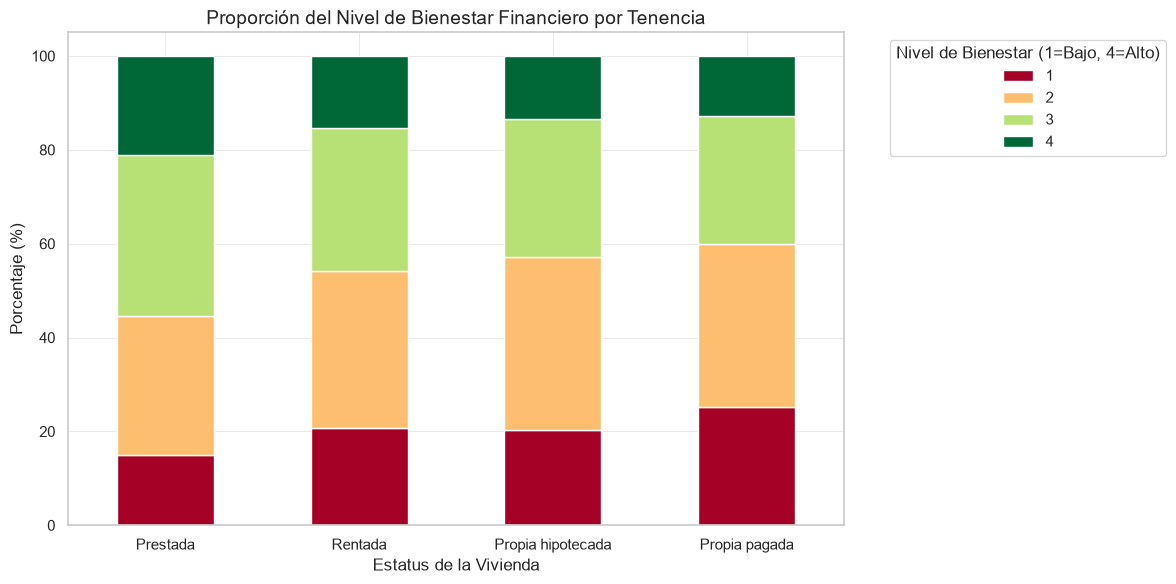

In [66]:
# Barras Apiladas (Proporciones)
tabla_proporciones = pd.crosstab(
    index=df_clean['estatus_tenencia'],
    columns=df_clean['NIV_BIENES'],
    values=df_clean['FAC_ELE'],
    aggfunc='sum',
    normalize='index'
) * 100

tabla_proporciones = tabla_proporciones.reindex(tabla_estadisticas.index)

ax = tabla_proporciones.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    colormap='RdYlGn'
)

plt.title('Proporción del Nivel de Bienestar Financiero por Tenencia', fontsize=14)
plt.xlabel('Estatus de la Vivienda', fontsize=12)
plt.ylabel('Porcentaje (%)', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Nivel de Bienestar (1=Bajo, 4=Alto)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(p3_salidas / "p3_proporcion_bienestar_tenencia.png", dpi=150, bbox_inches="tight")
plt.show()

### Conclusiones de la Proporción del Nivel de Bienestar Financiero por Tenencia

El análisis de la distribución del bienestar financiero a través de las diferentes categorías de tenencia revela patrones relevantes sobre el impacto de la carga económica habitacional:

* **El beneficio financiero de la vivienda prestada:** Las personas que habitan en una vivienda "Prestada" exhiben la mejor distribución de bienestar financiero, concentrando la mayor proporción de niveles altos (nivel 4) y la menor proporción del nivel más bajo (nivel 1) en comparación con el resto de los grupos. Esto indica que la ausencia de un gasto fijo mensual destinado a la vivienda probablemente libera flujo de efectivo, impactando positivamente en la estabilidad financiera.
* **Similitud de estrés financiero entre arrendamiento y deuda hipotecaria:** Los grupos con vivienda "Rentada" y "Propia hipotecada" presentan estructuras de bienestar financiero muy similares entre sí, ubicándose en un punto intermedio. En ambos escenarios, los niveles medios (2 y 3) conforman la gran mayoría de su población. Esto sugiere que el estrés generado por la obligación mensual de pago (ya sea por renta o por pago de crédito hipotecario) ejerce una presión comparable sobre el bienestar económico general de los hogares.
* **La paradoja de la vivienda propia pagada:** Contrario a la expectativa tradicional de que poseer una casa totalmente liquidada garantiza mayor tranquilidad, el grupo de vivienda "Propia pagada" concentra la mayor proporción de personas en el nivel más bajo de bienestar financiero (nivel 1, rozando el 25 %) y la menor proporción en el nivel más alto (nivel 4). Este fenómeno evidencia una clara desconexión entre la riqueza patrimonial (la casa) y el bienestar financiero diario, sugiriendo que ser dueño absoluto del inmueble no compensa otras posibles vulnerabilidades económicas que afectan a este grupo demográfico.

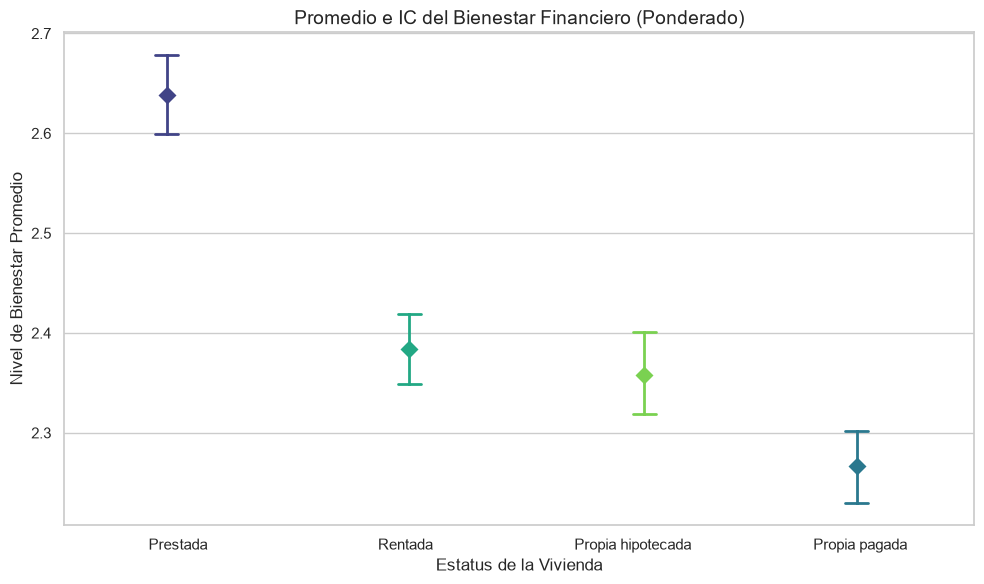

In [67]:
# Pointplot con Intervalos de Confianza
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.pointplot(
    data=df_resampled,
    x='estatus_tenencia',
    y='NIV_BIENES',
    order=tabla_estadisticas.index,
    hue='estatus_tenencia',
    palette='viridis',
    dodge=True,
    capsize=0.1,
    markers="D",
    err_kws={'linewidth': 2},
    legend=False,
    seed=42  # bootstrap de los IC reproducible
)

plt.title('Promedio e IC del Bienestar Financiero (Ponderado)', fontsize=14)
plt.xlabel('Estatus de la Vivienda', fontsize=12)
plt.ylabel('Nivel de Bienestar Promedio', fontsize=12)
plt.tight_layout()
plt.savefig(p3_salidas / "p3_ic_bienestar_tenencia.png", dpi=150, bbox_inches="tight")
plt.show()

### Conclusiones del Promedio e Intervalos de Confianza del Bienestar Financiero por Tenencia

El análisis de los promedios ponderados y sus respectivos intervalos de confianza (IC) proporciona evidencia estadística robusta sobre las diferencias en el bienestar financiero entre los grupos:

* **Superioridad de la vivienda prestada:** El grupo que habita en una vivienda "Prestada" registra el puntaje promedio más alto de la muestra, ubicándose por encima de los 2.6 puntos. El hecho de que su intervalo de confianza no se traslape con el de ninguna otra categoría demuestra empíricamente que esta ventaja en el bienestar financiero es estadísticamente significativa.
* **Equivalencia de impacto entre rentar y pagar hipoteca:** Las categorías de vivienda "Rentada" y "Propia hipotecada" muestran promedios muy cercanos. El traslape de sus intervalos de confianza indica que no existe una diferencia estadísticamente significativa entre ambos grupos. Esto confirma que la carga de un pago mensual fijo por vivienda (ya sea a un arrendador o a una institución financiera) genera un nivel de estrés económico equiparable.
* **Vulnerabilidad de la vivienda propia pagada:** El grupo con vivienda "Propia pagada" exhibe el nivel de bienestar financiero promedio más bajo. Su intervalo de confianza se ubica en el extremo inferior de la gráfica, separándose de los grupos de renta e hipoteca. Esto consolida estadísticamente la observación anterior: el valor patrimonial de una casa liquidada no garantiza el bienestar financiero, probablemente debido a que este grupo concentra poblaciones con ingresos fijos bajos (como pensionados o jóvenes en condiciones financieras más críticas).

In [68]:
# Prueba estadística (Kruskal-Wallis)
# Usamos df_resampled para que el análisis de varianza contemple el impacto real de los factores de expansión poblacionales, no solo la muestra no representativa.

grupos_ponderados = [grupo['NIV_BIENES'].values for nombre, grupo in df_resampled.groupby('estatus_tenencia')]

stat, p_valor = stats.kruskal(*grupos_ponderados)

print("Resultados de Prueba Estadística Kruskal-Wallis (Ponderada)")
print(f"Estadístico H: {stat:.2f}")
print(f"Valor p: {p_valor:.4e}")

if p_valor < 0.05:
    print("\nConclusión: Existe evidencia estadísticamente significativa (p < 0.05) para afirmar que el estatus de la vivienda sí impacta en el bienestar financiero.")
else:
    print("\nConclusión: No hay evidencia suficiente (p >= 0.05). El tipo de vivienda no muestra un impacto significativo en el bienestar.")

Resultados de Prueba Estadística Kruskal-Wallis (Ponderada)
Estadístico H: 197.82
Valor p: 1.2503e-42

Conclusión: Existe evidencia estadísticamente significativa (p < 0.05) para afirmar que el estatus de la vivienda sí impacta en el bienestar financiero.


### Conclusiones de la Prueba Estadística de Kruskal-Wallis

Para confirmar formalmente si las variaciones observadas en el bienestar financiero (`NIV_BIENES`) responden a diferencias estructurales entre los estatus de tenencia y no al azar, se aplicó la prueba no paramétrica de **Kruskal-Wallis** sobre la distribución ponderada, obteniendo un estadístico **$H = 197.82$** y un valor **$p = 1.2503 \times 10^{-42}$**:

* **Rechazo de la hipótesis nula ($H_0$):** Dado que el valor $p$ obtenido ($1.2503 \times 10^{-42}$) es infinitesimalmente menor a cualquier umbral estándar de significancia ($\alpha = 0.05$ o $\alpha = 0.01$), se rechaza de manera definitiva la hipótesis nula de igualdad de distribuciones. Esto demuestra con buena certeza estadística que el nivel de bienestar financiero varía significativamente según el estatus de tenencia de la vivienda en la población adulta representada.
* **Respaldo inferencial a los contrastes visuales:** Aunque la prueba de Kruskal-Wallis es un contraste global que indica la existencia de diferencias sin aislar por sí sola cada par de categorías, su resultado valida formalmente la separación observada en el análisis de intervalos de confianza: la brecha está impulsada principalmente por el mayor bienestar del grupo en vivienda *"Prestada"* (con promedio superior a 2.6 puntos) frente al rezago del grupo en vivienda *"Propia pagada"*, mientras que *"Rentada"* y *"Propia hipotecada"* se mantienen traslapadas en un nivel intermedio.

### Referencias

- Instituto Nacional de Estadística y Geografía (INEGI). (2024). [ENSAFI 2023: Cuestionario](https://www.inegi.org.mx/contenidos/programas/ensafi/2023/doc/ensafi_2023_cuestionario.pdf).
- INEGI. (2024). [ENSAFI 2023: Diseño muestral](https://www.inegi.org.mx/contenidos/productos/prod_serv/contenidos/espanol/bvinegi/productos/nueva_estruc/889463916840.pdf).
- INEGI. (2024). [ENSAFI 2023: Microdatos y documentación](https://www.inegi.org.mx/programas/ensafi/2023/).
- Holm, S. (1979). *A simple sequentially rejective multiple test procedure*. Scandinavian Journal of Statistics, 6(2), 65–70.
- Lumley, T. (2010). *Complex Surveys: A Guide to Analysis Using R*. Wiley.